# 胃癌进展风险分型与多组学预测（TCGA-STAD）

**一次运行产出全部结果**：本 notebook 从原始文件（`dataset/`）出发，依次完成 结局定义分型 → 多组学对齐与预过滤 → 预测分型 → RNA 的贡献 → 机制，所有图表同时保存到 `figures/`（PNG 300 dpi + PDF 矢量）。

 总体设计：一个分型，三步

```
阶段 A  定义分型（数据自己分）：PFI 的时间 + 删失 → 混合模型 → 急型进展 / 惰型进展 2 类；M1 单列
           │
阶段 B  6 种组学对齐、预过滤（无监督）
           │
阶段 C  预测分型：确诊时的临床 + 多组学 → 属于"急型"的概率；消融 / 置换 / 批次 / 风险分档
           │
阶段 D  RNA 的贡献：稳定入选基因、需要多少基因、与临床的比较
           │
阶段 E  机制（简要）：风险基因在肿瘤 vs 同一患者癌旁组织中是否改变；通路富集
```

**三条红线**：① 分型的定义只用 PFI 的时间与是否事件，临床与组学不参与；② 有监督特征筛选只在交叉验证训练折内进行；③ 解释用"相关/提示"，不说"因果"。

**为什么不聚类临床变量**：之前试过用 Gower 距离 + 共识聚类对临床变量分型，结果被"部位 × M1"主导（与两行规则的一致率 99%），且各簇之间生存无差异、组学也预测不了；改成"定义分型的是结局本身，预测的是确诊时的信息"后，分型与预测才成为同一件事。

## 运行方式

```bash
source .venv/bin/activate          # 依赖见 requirements.txt（uv pip install -r requirements.txt）
jupyter nbconvert --to notebook --execute --inplace exp.ipynb
```
首次运行约 5–6 分钟（含 1.2 GB 甲基化矩阵读取与探针→基因聚合；结果缓存到 `cache/`，之后约 4 分钟）。通路富集调用 Enrichr 在线服务，联网时自动执行，结果同样缓存。所有随机过程固定了随机种子。

> 图中文字统一使用中文。

In [1]:
import warnings, time, json, itertools, pickle, re, os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, Markdown
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import seaborn as sns
from scipy import stats, sparse
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from joblib import Parallel, delayed

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.impute import KNNImputer
from sklearn.manifold import MDS
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
                             f1_score, balanced_accuracy_score, roc_auc_score, confusion_matrix,
                             roc_curve, auc)

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test, pairwise_logrank_test
from lifelines.utils import concordance_index
from lifelines.plotting import add_at_risk_counts
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd()
DATA, CACHE, FIG = ROOT / "dataset", ROOT / "cache", ROOT / "figures"
CACHE.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
assert DATA.exists(), "请在项目根目录（含 dataset/）下运行本 notebook"
N_JOBS = max(1, (os.cpu_count() or 4) - 1)
T0 = time.time()

try:  # 在 notebook 中使用高分辨率内联图
    from IPython import get_ipython
    get_ipython().run_line_magic("config", "InlineBackend.figure_format='retina'")
except Exception:
    pass

# ---- 全局绘图风格 ----
sns.set_theme(style="ticks", context="notebook", font_scale=0.95)
mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "figure.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial Unicode MS", "PingFang SC", "Heiti SC", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.labelsize": 10,
    "axes.edgecolor": "#444444", "axes.linewidth": 0.9,
    "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "legend.frameon": False, "legend.fontsize": 9,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
MOD_COLORS = {"RNA": "#4C78A8", "Methylation": "#F58518", "CNV": "#54A24B",
              "Mutation": "#E45756", "miRNA": "#72B7B2", "RPPA": "#B279A2", "Site": "#B8860B"}
CL_PALETTE = ["#3B6FB6", "#2E9E6B", "#E6A532", "#D1495B", "#8E6BBF", "#7F7F7F"]  # 亚型配色（C1..）
DIV_CMAP = LinearSegmentedColormap.from_list("div", ["#2B6CB0", "#F7F7F7", "#C53030"])


def savefig(fig, name, show=True):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


def panel_label(ax, s, x=-0.12, y=1.06):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=14, fontweight="bold", va="bottom")


def tick():
    return f"[{(time.time() - T0) / 60:.1f} min]"


print("pandas", pd.__version__, "| numpy", np.__version__, "| cores used:", N_JOBS)

pandas 3.1.0 | numpy 2.5.4 | cores used: 7


In [2]:
def draw_at_risk(ax, df, group_col, names, colors, ticks, time_col="OS_months", fontsize=8.5):
    """手写 number-at-risk 表（lifelines 的 add_at_risk_counts 与 pandas 3 不兼容）。"""
    ax.set_xlim(ax.get_xlim()); ax.set_ylim(-0.5, len(names) - 0.5)
    for i, n in enumerate(names):
        t = df.loc[df[group_col] == n, time_col].values
        for tk in ticks:
            ax.text(tk, i, str(int((t >= tk).sum())), ha="center", va="center", fontsize=fontsize, color=colors[n], fontweight="bold")
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=fontsize)
    for t_, n in zip(ax.get_yticklabels(), names): t_.set_color(colors[n]); t_.set_fontweight("bold")
    ax.tick_params(axis="y", pad=14)
    ax.set_xticks(ticks); ax.invert_yaxis()
    for sp in ["top", "right", "left"]: ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0); ax.set_xlabel("")
    ax.set_title("Number at risk", fontsize=9, loc="left", pad=2)

In [3]:
def show_table(df, name, title, fmt=None, hl=None, cmap="Blues", col_w=None, fs=8.5, na="–", max_rows=None, wrap=None):
    """把 DataFrame 渲染成图片表格（同时保存到 figures/，并在 notebook 里直接显示）。
    fmt: {列名: 格式串或函数}；hl: 需要色阶高亮的列名列表；多级行索引会被展开成普通列。"""
    d = df.copy()
    if max_rows: d = d.head(max_rows)
    if isinstance(d.index, pd.MultiIndex) or d.index.name or not isinstance(d.index, pd.RangeIndex):
        d = d.reset_index()
        if "index" in d.columns and d.columns[0] == "index": d = d.rename(columns={"index": ""})
    cols = [str(c) for c in d.columns]; d.columns = cols
    raw = d.copy()
    def f(v, c):
        if v is None or (isinstance(v, float) and np.isnan(v)): return na
        ff = (fmt or {}).get(c)
        if callable(ff): return ff(v)
        if isinstance(ff, str):
            try: return ff.format(v)
            except Exception: return str(v)
        if isinstance(v, (float, np.floating)): return f"{v:.3g}"
        if isinstance(v, (bool, np.bool_)): return "是" if v else "否"
        return str(v)
    cells = [[f(v, c) for c, v in zip(cols, row)] for row in d.itertuples(index=False, name=None)]
    if wrap:
        import textwrap
        cells = [[textwrap.fill(x, wrap) if len(x) > wrap else x for x in r] for r in cells]
    nr, nc = len(cells), len(cols)
    import unicodedata
    _dw = lambda t: sum(2 if unicodedata.east_asian_width(ch) in "WF" else 1 for ch in str(t))       # 中文字符按两格宽计算
    widths = col_w or [max(_dw(cols[j]), max((max(_dw(x) for x in str(cells[i][j]).split("\n")) for i in range(nr)), default=1)) + 2 for j in range(nc)]
    W = max(5.5, 0.095 * sum(widths) + 0.6); H = 0.34 * (nr + 1) + 0.9
    fig, ax = plt.subplots(figsize=(W, H)); ax.axis("off")
    tb = ax.table(cellText=cells, colLabels=cols, loc="center", cellLoc="center", colWidths=[w / sum(widths) for w in widths])
    tb.auto_set_font_size(False); tb.set_fontsize(fs); tb.scale(1, 1.35)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#DDDDDD"); cell.set_linewidth(0.6)
        if r == 0: cell.set_facecolor("#2F4B6E"); cell.set_text_props(color="white", fontweight="bold")
        else: cell.set_facecolor("#F7F9FB" if r % 2 == 0 else "white")
        if c == 0 and r > 0 and not pd.api.types.is_numeric_dtype(raw.iloc[:, 0]): cell.set_text_props(ha="left", fontweight="bold"); cell._loc = "left"
    for col in (hl or []):
        if col not in cols: continue
        j = cols.index(col); vals = pd.to_numeric(raw[col], errors="coerce")
        if vals.notna().sum() < 2: continue
        lo, hi = vals.min(), vals.max(); cm = plt.get_cmap(cmap)
        for i, v in enumerate(vals):
            if pd.notna(v): tb[i + 1, j].set_facecolor(cm(0.15 + 0.6 * (v - lo) / (hi - lo + 1e-12)))
    ax.set_title(title, fontsize=10.5, fontweight="bold", loc="left", pad=6)
    savefig(fig, name)
    return df

In [4]:
def md(s):
    """输出由运行结果自动生成的 Markdown 结论（数字与该次运行严格一致）。"""
    display(Markdown(s))

---
# 1. 数据读入与临床变量整理

本节读取临床矩阵与生存表，只保留原发肿瘤（`sample_type == Primary Tumor`），整理**确诊时就已知**的临床变量。

**字段使用原则**
- **分型的定义只用结局**：无进展间隔 PFI（时间 + 是否事件）。临床变量与组学都不参与分型的定义。
- **预测模型的输入**：确诊时已知的 T、N、阳性淋巴结比例 LNR、年龄、解剖部位，加多组学。
- **M1（确诊即有远处转移）单列**：这是确诊时已知的事实，不需要预测，不进入混合模型与预测。
- **不进模型**：性别（只用来剔除性别相关基因）、TCGA 分子亚型与 MSI（留作事后对照）。

In [5]:
# ---------- 读取 ----------
clin = pd.read_csv(DATA / "TCGA.STAD.sampleMap_STAD_clinicalMatrix", sep="\t", low_memory=False)
n_all = len(clin)
clin = clin[clin["sample_type"] == "Primary Tumor"].set_index("sampleID")
surv_raw = pd.read_csv(DATA / "survival_STAD_survival.txt", sep="\t").set_index("sample")
official = pd.read_csv(ROOT / "stad_tcga_pub_clinical_data.tsv", sep="\t").set_index("Sample ID")

clin["TSS"] = [s.split("-")[1] for s in clin.index]         # 组织来源中心（批次）
print(f"clinicalMatrix: {n_all} 行 → 原发肿瘤 {len(clin)} 例（其余为癌旁正常组织）")
print(f"TCGA 官方四亚型标签: {len(official)} 例；与原发肿瘤交集 {len(set(official.index) & set(clin.index))} 例")

clinicalMatrix: 580 行 → 原发肿瘤 478 例（其余为癌旁正常组织）
TCGA 官方四亚型标签: 295 例；与原发肿瘤交集 295 例


In [6]:
# ---------- 字段清洗 ----------
def _T(s):
    return np.nan if pd.isna(s) or s == "TX" else s[:2]
def _N(s):
    return np.nan if pd.isna(s) or s in ("NX", "[Discrepancy]") else s[:2]

SITE_SHORT = {"Fundus/Body": "Body", "Antrum/Distal": "Antrum", "Cardia/Proximal": "Cardia", "Gastroesophageal Junction": "GEJ"}
age = pd.to_numeric(clin["age_at_initial_pathologic_diagnosis"], errors="coerce")
CLIN = pd.DataFrame(index=clin.index)
CLIN["N"] = clin["pathologic_N"].map(_N).map({"N0": 0, "N1": 1, "N2": 2, "N3": 3})
CLIN["T"] = clin["pathologic_T"].map(_T).map({"T1": 1, "T2": 2, "T3": 3, "T4": 4})
CLIN["LNR"] = (pd.to_numeric(clin["number_of_lymphnodes_positive_by_he"], errors="coerce")
               / pd.to_numeric(clin["lymph_node_examined_count"], errors="coerce"))
CLIN["Age"] = age
CLIN["Site"] = clin["anatomic_neoplasm_subdivision"].map(lambda s: SITE_SHORT.get(s, np.nan))
CLIN["M"] = clin["pathologic_M"].map(lambda s: s if s in ("M0", "M1") else np.nan)

# 供 RNA 预过滤剔除"性别相关基因"、以及 MSI / 分期对照使用
ENRICH = pd.DataFrame(index=clin.index)
ENRICH["Sex"] = clin["gender"].str.title()
ENRICH["MSI_status"] = clin["CDE_ID_3226963"]
ENRICH["Stage"] = clin["pathologic_stage"].map(
    lambda s: np.nan if pd.isna(s) else ("IV" if "IV" in s else "III" if "III" in s else "II" if "II" in s else "I" if s.startswith("Stage I") else np.nan))
CLIN["Stage"] = ENRICH["Stage"]

# 结局：PFI（无进展间隔）。M1 单列。
SURVP = surv_raw[["OS", "OS.time", "PFI", "PFI.time"]].reindex(clin.index)
is_m1 = (CLIN["M"] == "M1")
has_pfi = SURVP["PFI"].notna() & SURVP["PFI.time"].notna() & (SURVP["PFI.time"] > 0)
print(f"PFI 可用 {has_pfi.sum()} 例（事件 {int(SURVP.loc[has_pfi, 'PFI'].sum())}）；其中 M1 {int((is_m1 & has_pfi).sum())} 例（单列），"
      f"M1 以外 {int((~is_m1 & has_pfi).sum())} 例（事件 {int(SURVP.loc[has_pfi & ~is_m1, 'PFI'].sum())}）")
print("确诊时变量缺失（M1 以外、有 PFI）:", {c: int(CLIN.loc[has_pfi & ~is_m1, c].isna().sum()) for c in ["N", "T", "LNR", "Age", "Site", "M"]})
print("PFI 事件里以死亡计的比例:", f"{((surv_raw.loc[clin.index.intersection(surv_raw.index),'OS']==1) & (surv_raw.loc[clin.index.intersection(surv_raw.index),'PFI.time']==surv_raw.loc[clin.index.intersection(surv_raw.index),'OS.time']) & (surv_raw.loc[clin.index.intersection(surv_raw.index),'PFI']==1)).sum()} / {int(surv_raw.loc[clin.index.intersection(surv_raw.index),'PFI'].sum())}")

PFI 可用 419 例（事件 142）；其中 M1 27 例（单列），M1 以外 392 例（事件 130）
确诊时变量缺失（M1 以外、有 PFI）: {'N': 10, 'T': 5, 'LNR': 39, 'Age': 3, 'Site': 16, 'M': 19}
PFI 事件里以死亡计的比例: 28 / 143


---
# 阶段 A：用数据定义分型 —— 进展时间的混合模型

**任务**：不预设规则，只用 **PFI（无进展间隔：时间 + 是否事件）** 让数据自己分出类别。

**为什么不能把时间当一列放进 KMeans**：随访不够长的患者"没出事件"不等于"不会进展"（删失）。直接聚类会把"出事件的人"和"没出事件的人"分开，这是把结局当输入。
正确做法是**生存混合模型**：假设患者来自 K 个不同的"进展时间分布"，用带删失的似然拟合，给每个患者算他属于各类的后验概率。

| 步骤 | 内容 | 回答的问题 |
|---|---|---|
| A1 | 进展风险随时间的形状（不依赖任何模型） | 数据里有没有"多类"的迹象 |
| A2 | 1–4 类混合模型 + 两种分布族（Weibull / 对数正态），AIC / BIC | 选几类 |
| A3 | 拟合曲线 vs 观察曲线 | 选定的类数是否贴合数据 |
| A4 | 参数自举似然比检验、自举与对半拆分下的稳定性 | 类数是否稳健；3 类有没有证据 |
| A5 | 三种结局定义（PFI / 去掉死亡事件 / DFI）的对比 | 用哪种结局定义分型 |
| A6 | 最终分型：急型 / 惰型，各患者的后验概率；M1 单列 | 得到可用的标签 |

## A1 先看数据：年化进展风险率随时间的形状

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


分型对象：M1 以外、有 PFI 的患者 n = 392，事件 130（33%），中位随访 1.10 年；其中 3 年处仍在风险集的仅 42 人


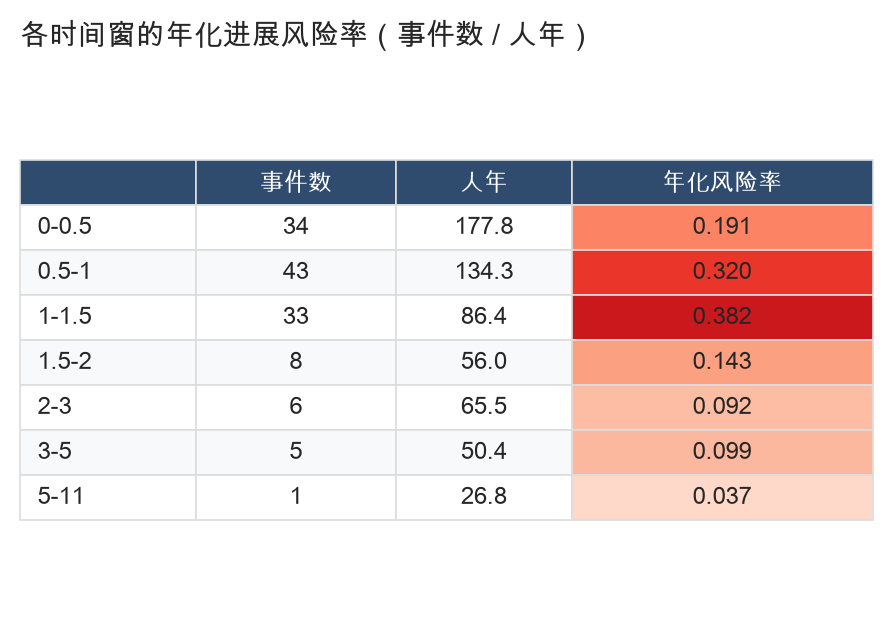

,事件数,人年,年化风险率
0-0.5,34,177.831507,0.191192
0.5-1,43,134.283562,0.320218
1-1.5,33,86.445205,0.381745
1.5-2,8,56.017808,0.142812
2-3,6,65.542466,0.091544
3-5,5,50.364384,0.099277
5-11,1,26.843836,0.037253


In [7]:
from scipy.optimize import minimize
from scipy.special import logsumexp
from scipy.stats import norm as _norm

PTS = has_pfi & ~is_m1                      # M1 以外且有 PFI
tP = (SURVP.loc[PTS, "PFI.time"] / 365.0).values
eP = SURVP.loc[PTS, "PFI"].astype(float).values
idsP = SURVP.index[PTS]
nP = len(tP)
print(f"分型对象：M1 以外、有 PFI 的患者 n = {nP}，事件 {int(eP.sum())}（{eP.mean():.0%}），中位随访 {np.median(tP):.2f} 年；其中 3 年处仍在风险集的仅 {int((tP >= 3).sum())} 人")

edges = [0, .5, 1, 1.5, 2, 3, 5, 11]
hz = []
for a_, b_ in zip(edges[:-1], edges[1:]):
    ev = int(((eP == 1) & (tP > a_) & (tP <= b_)).sum()); py = float((np.clip(tP, a_, b_) - a_)[tP > a_].sum())
    hz.append(dict(window=f"{a_}-{b_} y", events=ev, person_years=py, hazard_per_year=ev / py))
HZ = pd.DataFrame(hz).set_index("window")
HZ_show = HZ.rename(columns={"events": "事件数", "person_years": "人年", "hazard_per_year": "年化风险率"}).rename_axis("时间窗（年）")
HZ_show.index = [i.replace(" y", "") for i in HZ_show.index]
show_table(HZ_show, "T_A1_hazard_by_window", "各时间窗的年化进展风险率（事件数 / 人年）", fmt={"人年": "{:.1f}", "年化风险率": "{:.3f}", "事件数": "{:.0f}"}, hl=["年化风险率"], cmap="Reds")

## A2 混合模型与类数选择

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


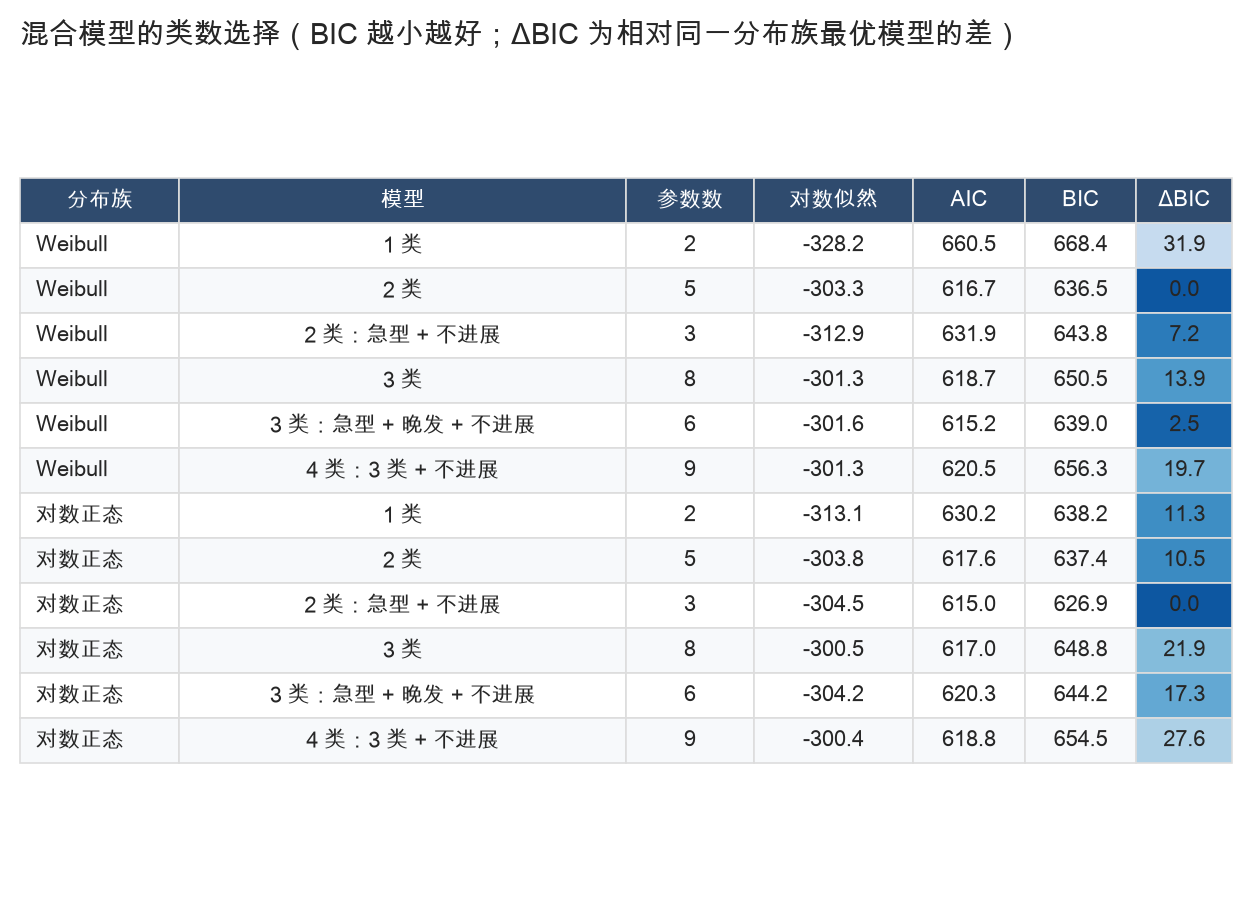

,分布族,模型,参数数,对数似然,AIC,BIC,ΔBIC
0,Weibull,1 类,2,-328.238948,660.477895,668.420419,31.874999
1,Weibull,2 类,5,-303.344555,616.689111,636.545420,0.000000
2,Weibull,2 类：急型 + 不进展,3,-312.937968,631.875935,643.789721,7.244301
3,Weibull,3 类,8,-301.340724,618.681448,650.451543,13.906123
4,Weibull,3 类：急型 + 晚发 + 不进展,6,-301.593256,615.186512,639.014083,2.468664
5,Weibull,4 类：3 类 + 不进展,9,-301.260922,620.521844,656.263201,19.717781
6,对数正态,1 类,2,-313.123346,630.246693,638.189216,11.285227
7,对数正态,2 类,5,-303.795962,617.591925,637.448234,10.544245
8,对数正态,2 类：急型 + 不进展,3,-304.495102,614.990204,626.903990,0.000000
9,对数正态,3 类,8,-300.516654,617.033308,648.803402,21.899413


In [8]:
def _logdens(fam, par, t, e):
    if fam == "wb":
        lam, k = np.exp(par[0]), np.exp(par[1])
        return np.where(e == 1, np.log(k / lam) + (k - 1) * np.log(t / lam) - (t / lam) ** k, -(t / lam) ** k)
    mu, sg = par[0], np.exp(par[1]); z = (np.log(t) - mu) / sg
    return np.where(e == 1, _norm.logpdf(z) - np.log(sg * t), _norm.logsf(z))

def _init(fam, rng):
    return np.log([rng.uniform(.3, 3), rng.uniform(.8, 2)]) if fam == "wb" else np.array([np.log(rng.uniform(.3, 3)), np.log(rng.uniform(.5, 1.5))])

def mix_fit(kinds, t, e, fam="wb", seed=0, iters=70):
    """EM 拟合带删失的混合模型。kinds 中 "f" 为一个进展时间分布，"cure" 为"不进展"类。"""
    rng = np.random.RandomState(seed); K = len(kinds)
    pars = [None if kd == "cure" else _init(fam, rng) for kd in kinds]; pi = np.ones(K) / K; prev = -1e18
    for it in range(iters):
        L = np.column_stack([np.where(e == 1, -1e9, 0.0) if kinds[j] == "cure" else _logdens(fam, pars[j], t, e) for j in range(K)]) + np.log(pi + 1e-12)
        ll = logsumexp(L, axis=1).sum(); R = np.exp(L - logsumexp(L, axis=1, keepdims=True)); pi = R.mean(0)
        for j in range(K):
            if kinds[j] == "cure": continue
            f = lambda p: -(R[:, j] * _logdens(fam, p, t, e)).sum()
            pars[j] = minimize(f, pars[j], method="Nelder-Mead", options=dict(xatol=1e-2, fatol=1e-3, maxiter=70)).x
        if it > 5 and abs(ll - prev) < 1e-3: break
        prev = ll
    return dict(ll=ll, pars=pars, pi=pi, R=R, kinds=kinds, fam=fam)

def mix_best(kinds, t, e, fam="wb", ns=5):
    return max((mix_fit(kinds, t, e, fam, s) for s in range(ns)), key=lambda r: r["ll"])
def mix_npar(kinds): return 2 * sum(k != "cure" for k in kinds) + len(kinds) - 1
def mix_bic(r, n): return -2 * r["ll"] + mix_npar(r["kinds"]) * np.log(n)
def mix_aic(r): return -2 * r["ll"] + 2 * mix_npar(r["kinds"])
def mix_median(r, j):
    p = r["pars"][j]
    if r["kinds"][j] == "cure": return np.inf
    return np.exp(p[0]) * np.log(2) ** (1 / np.exp(p[1])) if r["fam"] == "wb" else np.exp(p[0])
def mix_surv(r, tt):
    S = np.zeros_like(tt, dtype=float)
    for j, kd in enumerate(r["kinds"]):
        if kd == "cure": S += r["pi"][j]; continue
        p = r["pars"][j]
        Sj = np.exp(-(tt / np.exp(p[0])) ** np.exp(p[1])) if r["fam"] == "wb" else _norm.sf((np.log(tt) - p[0]) / np.exp(p[1]))
        S += r["pi"][j] * Sj
    return S

CANDS = {"1 class": ["f"], "2 classes": ["f", "f"], "2: fast + non-progressing": ["f", "cure"],
         "3 classes": ["f", "f", "f"], "3: fast + late + non-progressing": ["f", "f", "cure"], "4: 3 + non-progressing": ["f", "f", "f", "cure"]}
MIX = {}
rows = []
for fam, fam_name in [("wb", "Weibull"), ("ln", "Log-normal")]:
    for nm, kinds in CANDS.items():
        r = mix_best(kinds, tP, eP, fam, ns=5); MIX[(fam, nm)] = r
        rows.append(dict(family=fam_name, model=nm, npar=mix_npar(kinds), logL=r["ll"], AIC=mix_aic(r), BIC=mix_bic(r, nP)))
A2 = pd.DataFrame(rows)
A2["dBIC"] = A2.groupby("family")["BIC"].transform(lambda x: x - x.min())
_CLS_ZH = {"1 class": "1 类", "2 classes": "2 类", "2: fast + non-progressing": "2 类：急型 + 不进展", "3 classes": "3 类",
           "3: fast + late + non-progressing": "3 类：急型 + 晚发 + 不进展", "4: 3 + non-progressing": "4 类：3 类 + 不进展"}
A2_show = A2.assign(model=A2.model.map(_CLS_ZH), family=A2.family.map({"Weibull": "Weibull", "Log-normal": "对数正态"})).rename(columns={"family": "分布族", "model": "模型", "npar": "参数数", "logL": "对数似然", "dBIC": "ΔBIC"})
show_table(A2_show, "T_A2_class_number_selection", "混合模型的类数选择（BIC 越小越好；ΔBIC 为相对同一分布族最优模型的差）", fmt={"参数数": "{:.0f}", "对数似然": "{:.1f}", "AIC": "{:.1f}", "BIC": "{:.1f}", "ΔBIC": "{:.1f}"}, hl=["ΔBIC"], cmap="Blues_r", fs=8)

## A3 拟合曲线是否贴合观察曲线

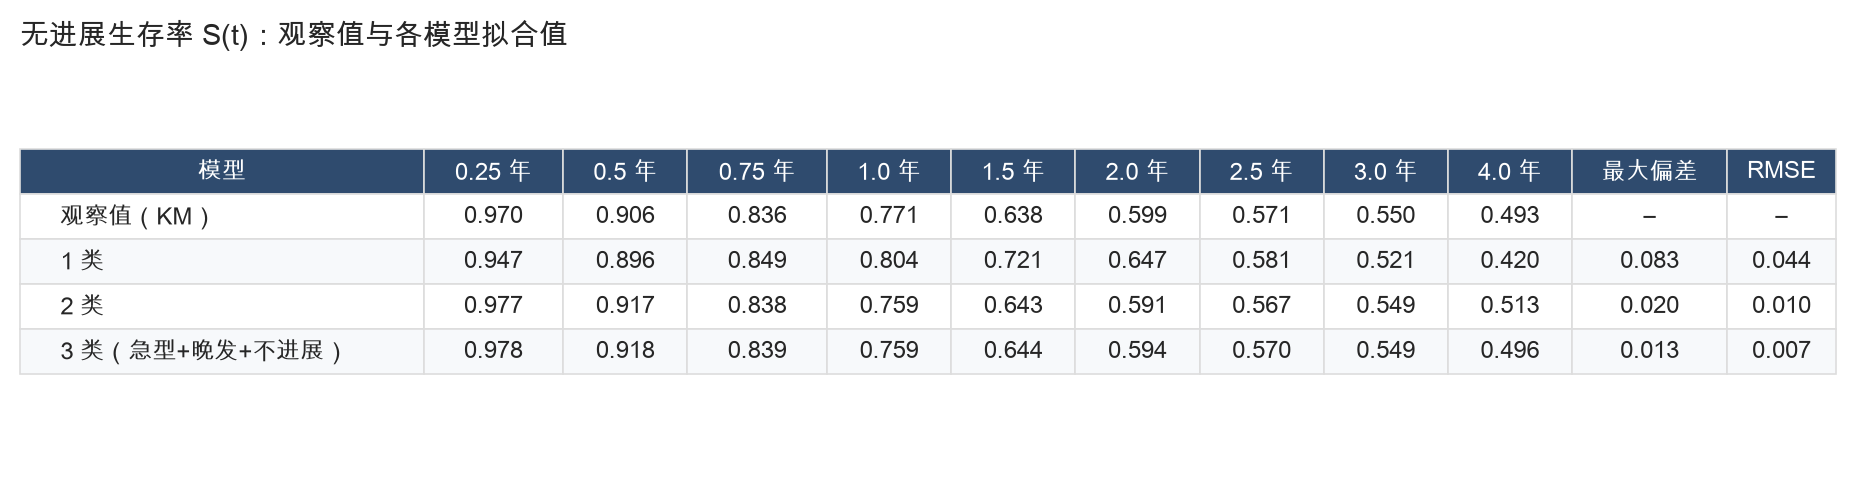

,0.25 年,0.5 年,0.75 年,1.0 年,1.5 年,2.0 年,2.5 年,3.0 年,4.0 年,最大偏差,RMSE
模型,,,,,,,,,,,
观察值（KM）,0.970172,0.905795,0.836254,0.770935,0.638249,0.598631,0.571434,0.550121,0.492908,NaN,NaN
1 类,0.946503,0.896205,0.848700,0.803786,0.721100,0.647038,0.580661,0.521150,0.419907,0.082851,0.043903
2 类,0.976853,0.917359,0.838346,0.758677,0.643383,0.590837,0.566631,0.548665,0.513387,0.020479,0.009802
3 类（急型+晚发+不进展）,0.977846,0.918346,0.838807,0.758684,0.643937,0.593608,0.570405,0.549381,0.496170,0.012551,0.007015


In [9]:
km = KaplanMeierFitter().fit(tP, eP)
grid = np.array([.25, .5, .75, 1, 1.5, 2, 2.5, 3, 4])
obs = np.array([float(km.predict(x)) for x in grid])
fitrows = {"Observed (KM)": obs}
for key, lab_ in [(("wb", "1 class"), "1 class"), (("wb", "2 classes"), "2 classes"), (("wb", "3: fast + late + non-progressing"), "3 classes (fast+late+non-prog.)")]:
    fitrows[lab_] = mix_surv(MIX[key], grid)
A3 = pd.DataFrame(fitrows, index=[f"{x}y" for x in grid]).T
A3["max |dev|"] = [np.nan] + [np.abs(A3.iloc[i, :len(grid)].values - obs).max() for i in range(1, len(A3))]
A3["RMSE"] = [np.nan] + [np.sqrt(((A3.iloc[i, :len(grid)].values - obs) ** 2).mean()) for i in range(1, len(A3))]
A3_show = A3.rename(index={"Observed (KM)": "观察值（KM）", "1 class": "1 类", "2 classes": "2 类", "3 classes (fast+late+non-prog.)": "3 类（急型+晚发+不进展）"}).rename(columns={"max |dev|": "最大偏差"})
A3_show.columns = [c.replace("y", " 年") if c.endswith("y") else c for c in A3_show.columns]
show_table(A3_show.rename_axis("模型"), "T_A3_fit_vs_observed", "无进展生存率 S(t)：观察值与各模型拟合值", fmt={c: "{:.3f}" for c in A3_show.columns})

## A4 类数是否稳健：参数自举似然比检验、自举与对半拆分

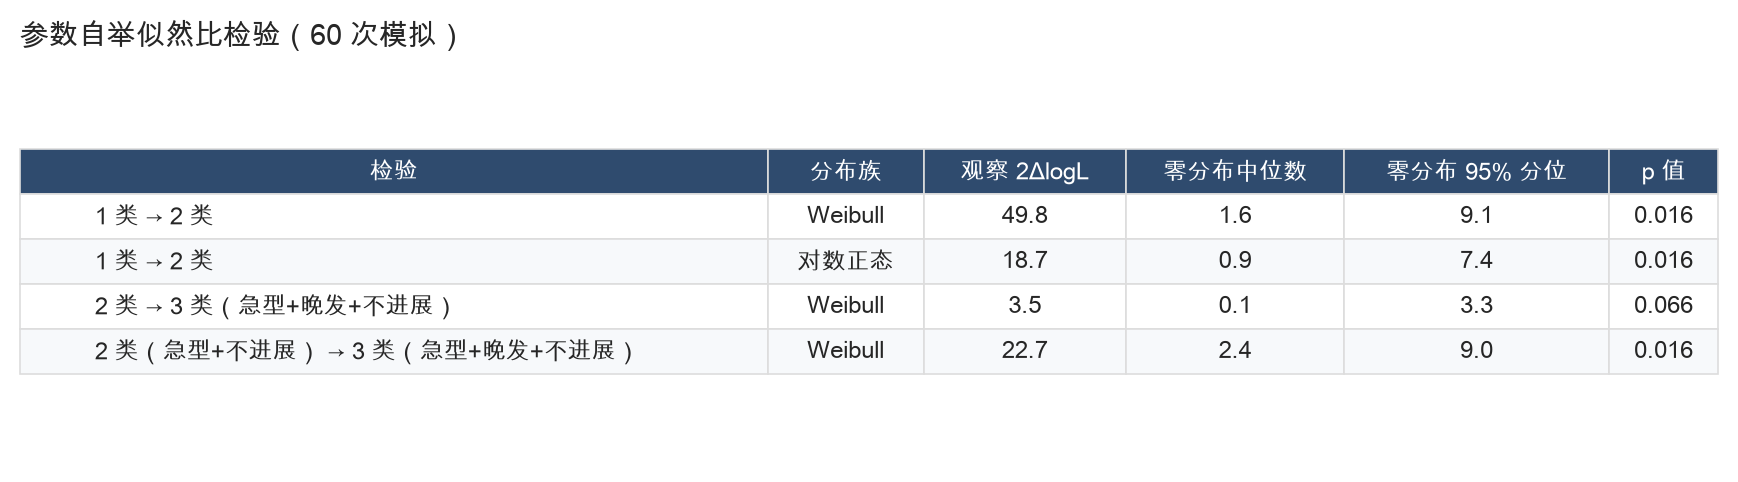

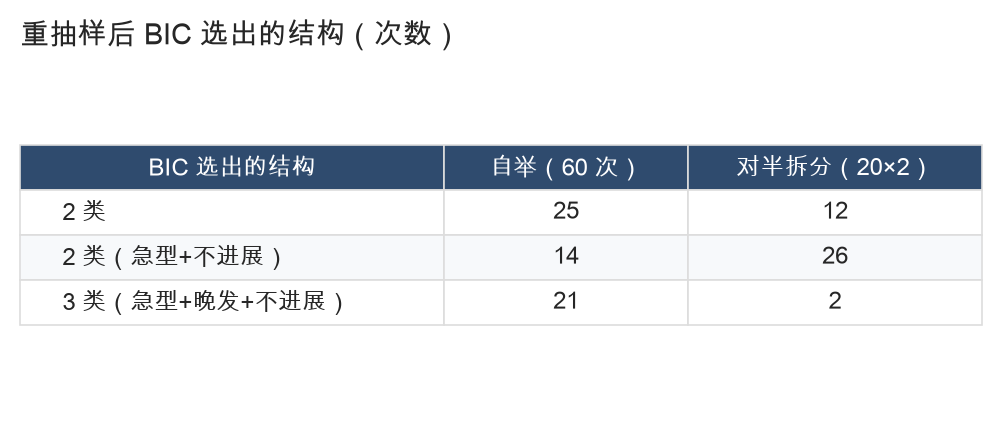

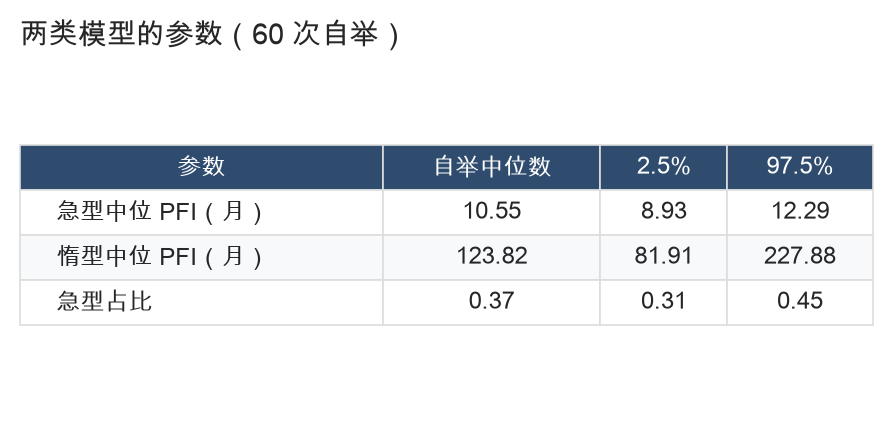

,自举中位数,2.5%,97.5%
参数,,,
急型中位 PFI（月）,10.546913,8.934476,12.290482
惰型中位 PFI（月）,123.822726,81.913778,227.876933
急型占比,0.374344,0.305447,0.448092


In [10]:
def _simulate(r, n, t_obs, e_obs, rng):
    kmc = KaplanMeierFitter().fit(t_obs, 1 - e_obs); sf = kmc.survival_function_.iloc[:, 0]; tt = sf.index.values; sv = sf.values
    comp = rng.choice(len(r["kinds"]), n, p=r["pi"]); T = np.full(n, np.inf)
    for j, kd in enumerate(r["kinds"]):
        m = comp == j
        if kd == "cure" or m.sum() == 0: continue
        p = r["pars"][j]; u = rng.uniform(size=m.sum())
        T[m] = np.exp(p[0]) * (-np.log(u)) ** (1 / np.exp(p[1])) if r["fam"] == "wb" else np.exp(p[0] + np.exp(p[1]) * _norm.ppf(1 - u))
    u = rng.uniform(size=n); C = np.array([tt[np.argmax(sv <= x)] if (sv <= x).any() else tt[-1] for x in u]); C = np.maximum(C, 1e-3)
    return np.maximum(np.minimum(T, C), 1e-3), (T <= C).astype(float)

def lrt_boot(k0, k1, fam, B=60):
    r0, r1 = MIX[(fam, k0)], MIX[(fam, k1)]; obs_ = 2 * (r1["ll"] - r0["ll"])
    def one(b):
        rng = np.random.default_rng(1000 + b); tb, eb = _simulate(r0, nP, tP, eP, rng)
        a = mix_best(r0["kinds"], tb, eb, fam, ns=3); c = mix_best(r1["kinds"], tb, eb, fam, ns=3); return 2 * (c["ll"] - a["ll"])
    nl = np.array(Parallel(n_jobs=N_JOBS)(delayed(one)(b) for b in range(B)))
    return dict(test=f"{k0} → {k1}", family="Weibull" if fam == "wb" else "Log-normal", observed_2dLL=obs_, null_median=np.median(nl),
                null_95pct=np.percentile(nl, 95), p=(np.sum(nl >= obs_) + 1) / (B + 1))
LRT = pd.DataFrame([lrt_boot("1 class", "2 classes", "wb"), lrt_boot("1 class", "2 classes", "ln"),
                    lrt_boot("2 classes", "3: fast + late + non-progressing", "wb"),
                    lrt_boot("2: fast + non-progressing", "3: fast + late + non-progressing", "wb")]).set_index("test")
LRT_show = LRT.copy(); LRT_show.index = [i.replace("1 class", "1 类").replace("2 classes", "2 类").replace("3: fast + late + non-progressing", "3 类（急型+晚发+不进展）").replace("2: fast + non-progressing", "2 类（急型+不进展）") for i in LRT_show.index]
LRT_show["family"] = LRT_show["family"].map({"Weibull": "Weibull", "Log-normal": "对数正态"})
LRT_show = LRT_show.rename(columns={"family": "分布族", "observed_2dLL": "观察 2ΔlogL", "null_median": "零分布中位数", "null_95pct": "零分布 95% 分位", "p": "p 值"}).rename_axis("检验")
show_table(LRT_show, "T_A4_bootstrap_LRT", "参数自举似然比检验（60 次模拟）", fmt={"观察 2ΔlogL": "{:.1f}", "零分布中位数": "{:.1f}", "零分布 95% 分位": "{:.1f}", "p 值": "{:.3f}"}, wrap=30)

_pick_c = {"1": ["f"], "2": ["f", "f"], "2c": ["f", "cure"], "3c": ["f", "f", "cure"], "3": ["f", "f", "f"]}
def _pick(tb, eb):
    b = {k: mix_bic(mix_best(v, tb, eb, "wb", ns=3), len(tb)) for k, v in _pick_c.items()}; return min(b, key=b.get)
def _boot(i):
    rng = np.random.default_rng(i); ii = rng.integers(0, nP, nP); return _pick(tP[ii], eP[ii])
def _half(i):
    rng = np.random.default_rng(500 + i); p = rng.permutation(nP); a, b = p[:nP // 2], p[nP // 2:]; return _pick(tP[a], eP[a]), _pick(tP[b], eP[b])
sel_boot = Parallel(n_jobs=N_JOBS)(delayed(_boot)(i) for i in range(60))
sel_half = [x for h in Parallel(n_jobs=N_JOBS)(delayed(_half)(i) for i in range(20)) for x in h]
NAME_PICK = {"1": "1 class", "2": "2 classes", "2c": "2: fast + non-progressing", "3c": "3: fast + late + non-prog.", "3": "3 classes"}
STAB = pd.DataFrame({"bootstrap (60×)": pd.Series(sel_boot).value_counts(), "half-split (20×2)": pd.Series(sel_half).value_counts()}).fillna(0).astype(int)
STAB.index = [NAME_PICK[i] for i in STAB.index]
STAB_show = STAB.copy(); STAB_show.index = [i.replace("1 class", "1 类").replace("2 classes", "2 类").replace("3: fast + late + non-prog.", "3 类（急型+晚发+不进展）").replace("2: fast + non-progressing", "2 类（急型+不进展）").replace("3 classes", "3 类") for i in STAB_show.index]
STAB_show.columns = ["自举（60 次）", "对半拆分（20×2）"]
show_table(STAB_show.rename_axis("BIC 选出的结构"), "T_A4_resampling_stability", "重抽样后 BIC 选出的结构（次数）", fmt={c: "{:.0f}" for c in STAB_show.columns})

def _p2(i):
    rng = np.random.default_rng(900 + i); ii = rng.integers(0, nP, nP); r = mix_best(["f", "f"], tP[ii], eP[ii], "wb", ns=3)
    meds = [mix_median(r, j) * 12 for j in range(2)]; o = np.argsort(meds); return meds[o[0]], meds[o[1]], r["pi"][o[0]]
PP2 = np.array(Parallel(n_jobs=N_JOBS)(delayed(_p2)(i) for i in range(60)))
_f = lambda x: (np.median(x), *np.percentile(x, [2.5, 97.5]))
PAR2 = pd.DataFrame({"fast-class median PFI (months)": _f(PP2[:, 0]), "slow-class median PFI (months)": _f(PP2[:, 1]), "fast-class share": _f(PP2[:, 2])},
                    index=["bootstrap median", "2.5%", "97.5%"]).T
PAR2_show = PAR2.rename(index={"fast-class median PFI (months)": "急型中位 PFI（月）", "slow-class median PFI (months)": "惰型中位 PFI（月）", "fast-class share": "急型占比"}, columns={"bootstrap median": "自举中位数", "2.5%": "2.5%", "97.5%": "97.5%"}).rename_axis("参数")
show_table(PAR2_show, "T_A4_two_class_parameters", "两类模型的参数（60 次自举）", fmt={c: "{:.2f}" for c in PAR2_show.columns})

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


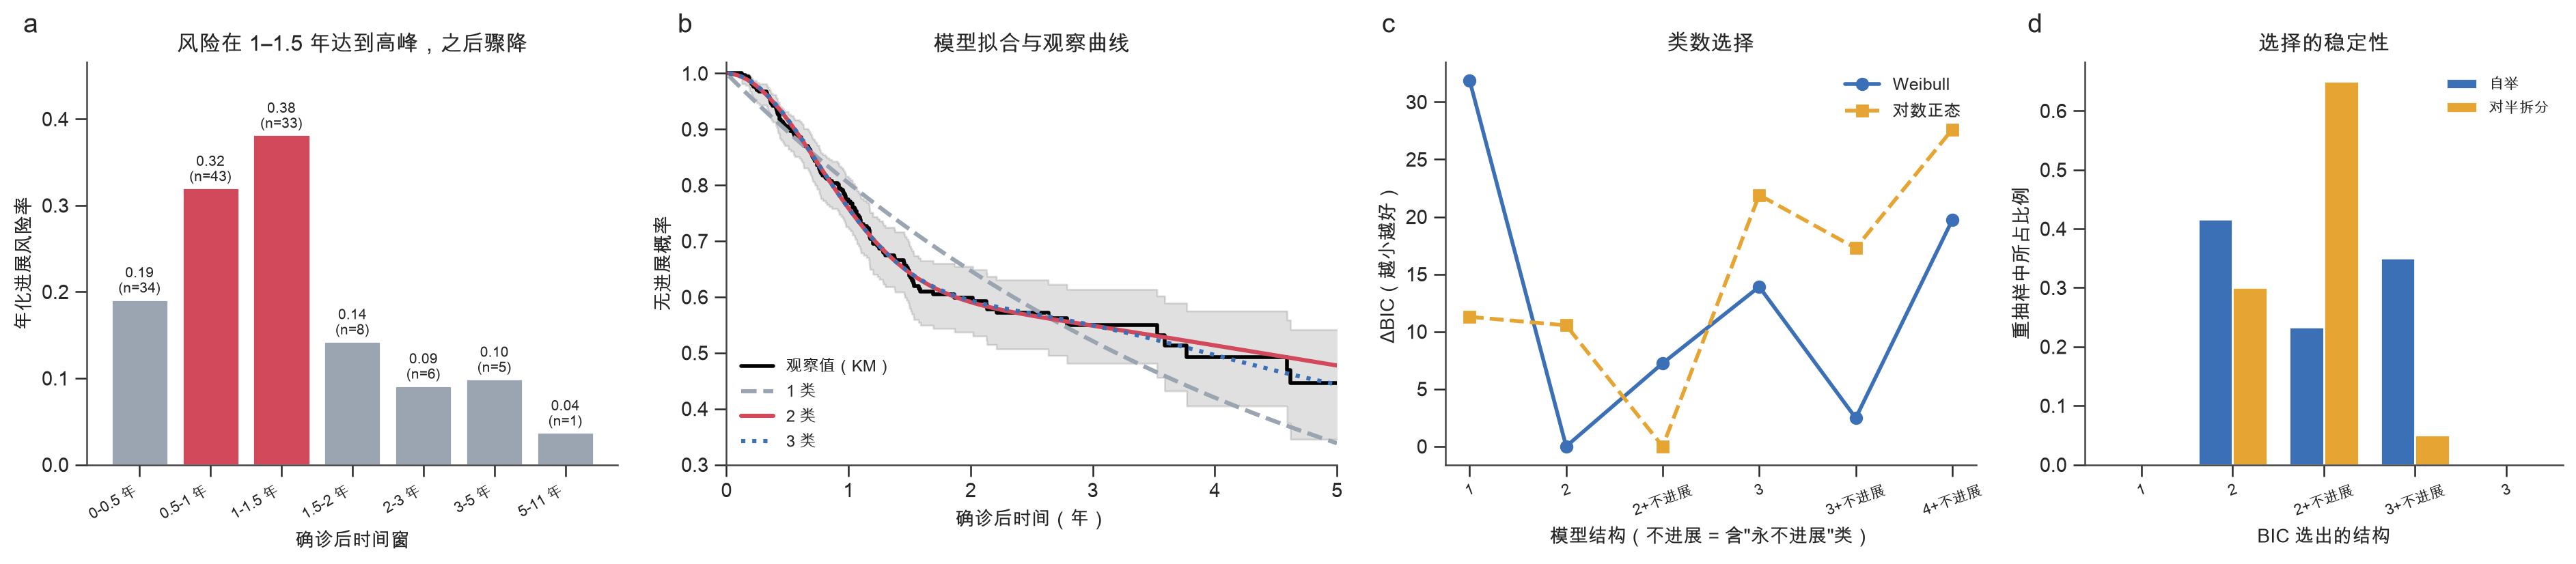

In [11]:
# ----- 图 A-1：风险率形状 + 拟合曲线 + BIC + 稳定性 -----
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), gridspec_kw=dict(width_ratios=[1, 1.15, 1, 0.9]))
ax = axes[0]
mid = [(a + b) / 2 for a, b in zip(edges[:-1], edges[1:])]
ax.bar(range(len(HZ)), HZ.hazard_per_year, color=["#D1495B" if v > 0.3 else "#9AA5B1" for v in HZ.hazard_per_year], edgecolor="white")
for i, (v, n_) in enumerate(zip(HZ.hazard_per_year, HZ.events)): ax.text(i, v + 0.008, f"{v:.2f}\n(n={n_})", ha="center", fontsize=7.5)
ax.set_xticks(range(len(HZ))); ax.set_xticklabels([i.replace(" y", " 年") for i in HZ.index], rotation=30, ha="right", fontsize=8); ax.set_ylim(0, HZ.hazard_per_year.max() * 1.22)
ax.set(ylabel="年化进展风险率", title="风险在 1–1.5 年达到高峰，之后骤降", xlabel="确诊后时间窗"); panel_label(ax, "a")
ax = axes[1]
km.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.12, color="black", lw=2, label="观察值（KM）", show_censors=False)
tt_ = np.linspace(0.02, 5, 200)
for key, c_, ls_, lb_ in [(("wb", "1 class"), "#9AA5B1", "--", "1 类"), (("wb", "2 classes"), "#D1495B", "-", "2 类"), (("wb", "3: fast + late + non-progressing"), "#3B6FB6", ":", "3 类")]:
    ax.plot(tt_, mix_surv(MIX[key], tt_), c=c_, ls=ls_, lw=2.2, label=lb_)
ax.set(xlim=(0, 5), ylim=(0.3, 1.02), xlabel="确诊后时间（年）", ylabel="无进展概率", title="模型拟合与观察曲线"); ax.legend(loc="lower left", fontsize=8.5)
panel_label(ax, "b", -0.08)
ax = axes[2]
for fam_, c_, mk_, lb_ in [("Weibull", "#3B6FB6", "o-", "Weibull"), ("Log-normal", "#E6A532", "s--", "对数正态")]:
    g = A2[A2.family == fam_]; ax.plot(range(len(g)), g.BIC - g.BIC.min(), mk_, c=c_, lw=2, ms=6, label=lb_)
ax.set_xticks(range(len(CANDS))); ax.set_xticklabels(["1", "2", "2+不进展", "3", "3+不进展", "4+不进展"], fontsize=8, rotation=20)
ax.set(xlabel="模型结构（不进展 = 含\"永不进展\"类）", ylabel="ΔBIC（越小越好）", title="类数选择"); ax.legend(); panel_label(ax, "c")
ax = axes[3]
stab_plot = STAB.reindex(["1 class", "2 classes", "2: fast + non-progressing", "3: fast + late + non-prog.", "3 classes"]).fillna(0)
stab_plot = stab_plot / stab_plot.sum()
x_ = np.arange(len(stab_plot)); w_ = 0.38
ax.bar(x_ - w_ / 2, stab_plot["bootstrap (60×)"], w_, color="#3B6FB6", label="自举"); ax.bar(x_ + w_ / 2, stab_plot["half-split (20×2)"], w_, color="#E6A532", label="对半拆分")
ax.set_xticks(x_); ax.set_xticklabels(["1", "2", "2+不进展", "3+不进展", "3"], fontsize=8, rotation=20)
ax.set(xlabel="BIC 选出的结构", ylabel="重抽样中所占比例", title="选择的稳定性"); ax.legend(fontsize=8); panel_label(ax, "d")
fig.tight_layout(); savefig(fig, "A1_mixture_model_selection")

## A5 用哪种结局定义分型：PFI、死亡改为删失的 PFI、DFI

**为什么要做这个对照。** TCGA 的 PFI（无进展间隔）把**死亡**也算作进展事件：一个患者在没有记录到复发或转移的情况下去世，数据里就把他的死亡时间当成 PFI 事件时间。这些人可能死于手术并发症、感染或其他疾病，不一定是肿瘤进展，把他们算进"急型"会混入非肿瘤进展的事件。

**"把以死亡计的 PFI 事件改为删失"是什么意思。**
- *事件*：我们关心的结局发生了（这里是进展）。
- *删失（截尾）*：随访到某个时间就停了，之后不知道发生了什么；这个人只提供"至少到这时没出事件"这一条信息。
- 操作：对"患者已死亡（OS = 1）且 PFI 时间恰好等于 OS 时间"的人，把 PFI 事件由 1 改为 0、时间不变；有复发 / 转移记录的人不变。

例如：某患者第 9 个月去世、没有复发或转移记录 → 原始 PFI 记为"第 9 个月进展"；改为删失后记为"观察到第 9 个月没有进展就中断了"。

**这是对照实验，不是正式分型。** 正式分型仍用原始 PFI；这里把混合模型在"死亡改为删失"的版本上再跑一遍，看结论会不会变：如果急型的中位进展时间、占比、BIC 选出的结构都基本不变，就说明急型不是由早期死亡造成的。

**局限。** 改成删失，等于假设"这些人如果没死就不会因肿瘤进展"，这个假设不一定成立。更严格的做法是竞争风险模型（死亡与进展互相竞争），但在 130 个事件的规模下不值得使用，这里只把它当作稳健性检验。

另一个对照 **DFI（无病间隔）** 只包含复发和转移，不含死亡，但只有 46 个事件。

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


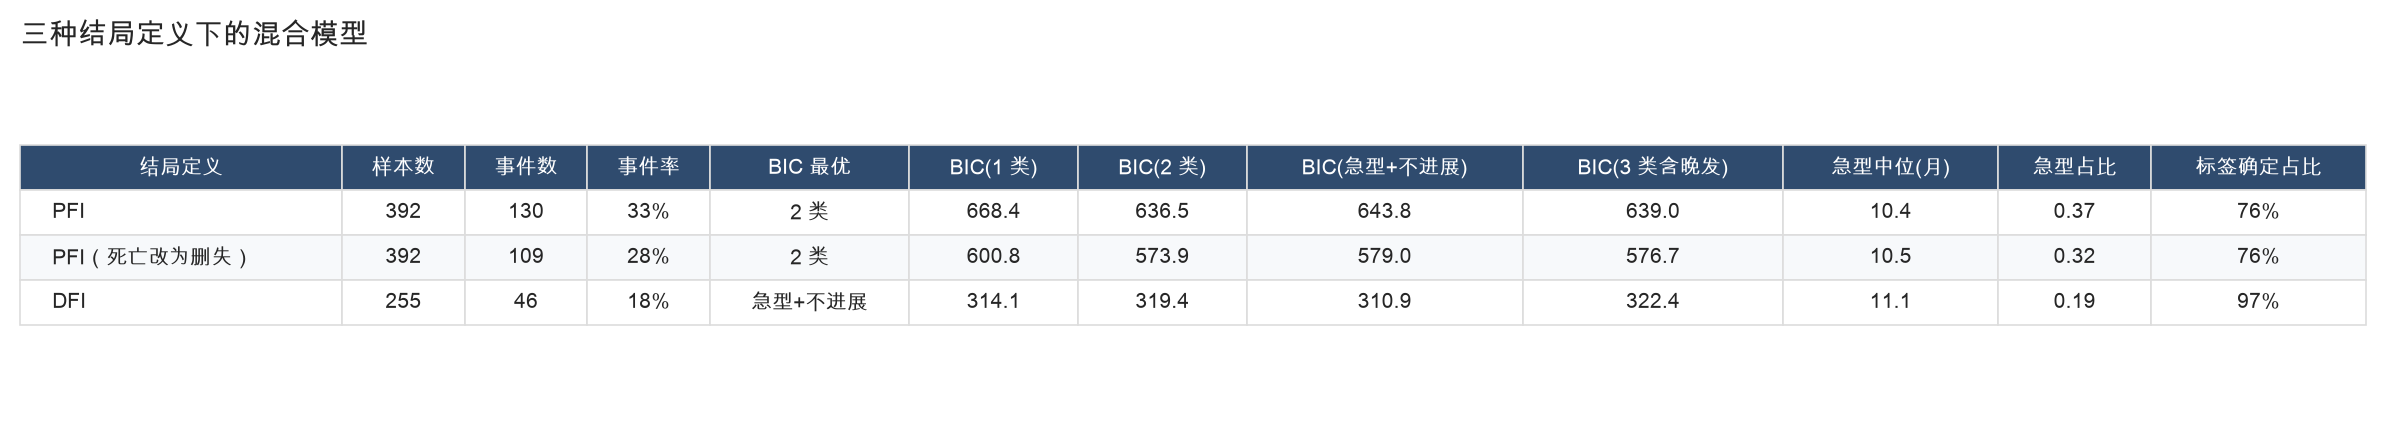

非 M1 患者的 PFI 事件 130 个，其中以死亡计（OS=1 且 PFI 时间=OS 时间）21 个（16%）；改为删失后事件数 130 → 109


In [12]:
def _variant(name):
    x = surv_raw.reindex(clin.index)[["OS", "OS.time", "PFI", "PFI.time"]].copy()
    x["DFI"] = surv_raw.reindex(clin.index)["DFI"]; x["DFI.time"] = surv_raw.reindex(clin.index)["DFI.time"]
    x = x[~is_m1]
    if name == "PFI": tm, ev = x["PFI.time"], x["PFI"]
    elif name == "PFI (deaths censored)":
        tm = x["PFI.time"]; ev = x["PFI"].copy(); ev[(x["OS"] == 1) & (x["PFI.time"] == x["OS.time"])] = 0
    else: tm, ev = x["DFI.time"], x["DFI"]
    m = tm.notna() & ev.notna() & (tm > 0)
    return tm[m] / 365.0, ev[m].astype(float)
rows = []; VAR = {}
for name in ["PFI", "PFI (deaths censored)", "DFI"]:
    tv, ev = _variant(name); tv_, ev_ = tv.values, ev.values; n_ = len(tv_)
    rr = {k: mix_best(v, tv_, ev_, "wb", ns=4) for k, v in {"1": ["f"], "2": ["f", "f"], "2c": ["f", "cure"], "3c": ["f", "f", "cure"]}.items()}
    b = {k: mix_bic(r, n_) for k, r in rr.items()}; r2 = rr["2"]; meds = [mix_median(r2, j) * 12 for j in range(2)]; o = int(np.argmin(meds))
    pf = r2["R"][:, o]; VAR[name] = (tv.index, pf)
    rows.append(dict(outcome=name, n=n_, events=int(ev_.sum()), event_rate=ev_.mean(), best_by_BIC=min(b, key=b.get),
                     BIC_1=b["1"], BIC_2=b["2"], BIC_2np=b["2c"], BIC_3np=b["3c"], fast_median_months=meds[o], fast_share=r2["pi"][o],
                     confident=((pf > .8) | (pf < .2)).mean()))
A5 = pd.DataFrame(rows).set_index("outcome")
A5_show = A5.rename(index={"PFI": "PFI", "PFI (deaths censored)": "PFI（死亡改为删失）", "DFI": "DFI"}).rename(columns={"n": "样本数", "events": "事件数", "event_rate": "事件率", "best_by_BIC": "BIC 最优", "BIC_1": "BIC(1 类)", "BIC_2": "BIC(2 类)", "BIC_2np": "BIC(急型+不进展)", "BIC_3np": "BIC(3 类含晚发)", "fast_median_months": "急型中位(月)", "fast_share": "急型占比", "confident": "标签确定占比"}).rename_axis("结局定义")
A5_show["BIC 最优"] = A5_show["BIC 最优"].map({"2": "2 类", "2c": "急型+不进展", "1": "1 类", "3c": "3 类"})
show_table(A5_show, "T_A5_outcome_definitions", "三种结局定义下的混合模型", fmt={"样本数": "{:.0f}", "事件数": "{:.0f}", "事件率": "{:.0%}", "BIC(1 类)": "{:.1f}", "BIC(2 类)": "{:.1f}", "BIC(急型+不进展)": "{:.1f}", "BIC(3 类含晚发)": "{:.1f}",
                         "急型中位(月)": "{:.1f}", "急型占比": "{:.2f}", "标签确定占比": "{:.0%}"}, fs=7.5)

# 现场统计"以死亡计"的事件数,作为上面说明的数据依据
_x = surv_raw.reindex(clin.index)[["OS", "OS.time", "PFI", "PFI.time"]]; _x = _x[~is_m1]; _x = _x[_x["PFI"].notna() & _x["PFI.time"].notna() & (_x["PFI.time"] > 0)]
N_DEATH_EV = int(((_x["PFI"] == 1) & (_x["OS"] == 1) & (_x["PFI.time"] == _x["OS.time"])).sum()); N_PFI_EV = int((_x["PFI"] == 1).sum())
print(f"非 M1 患者的 PFI 事件 {N_PFI_EV} 个，其中以死亡计（OS=1 且 PFI 时间=OS 时间）{N_DEATH_EV} 个（{N_DEATH_EV / N_PFI_EV:.0%}）；改为删失后事件数 {N_PFI_EV} → {N_PFI_EV - N_DEATH_EV}")

## A6 最终分型

急型：占 37.0%，中位 PFI 10.4 个月；惰型：中位 118 个月
硬划分：急型 118 / 惰型 274；后验确定（>0.8 或 <0.2）296 人（76%）；不确定 96 人，其中无事件 92%
急型里事件发生时间(月) 最小/中位/最大: 2.0 9.0 22.0
惰型里的事件：12 例，发生时间 ≥ 24 个月
硬划分与规则「2 年内是否进展」的一致率: 100.0%


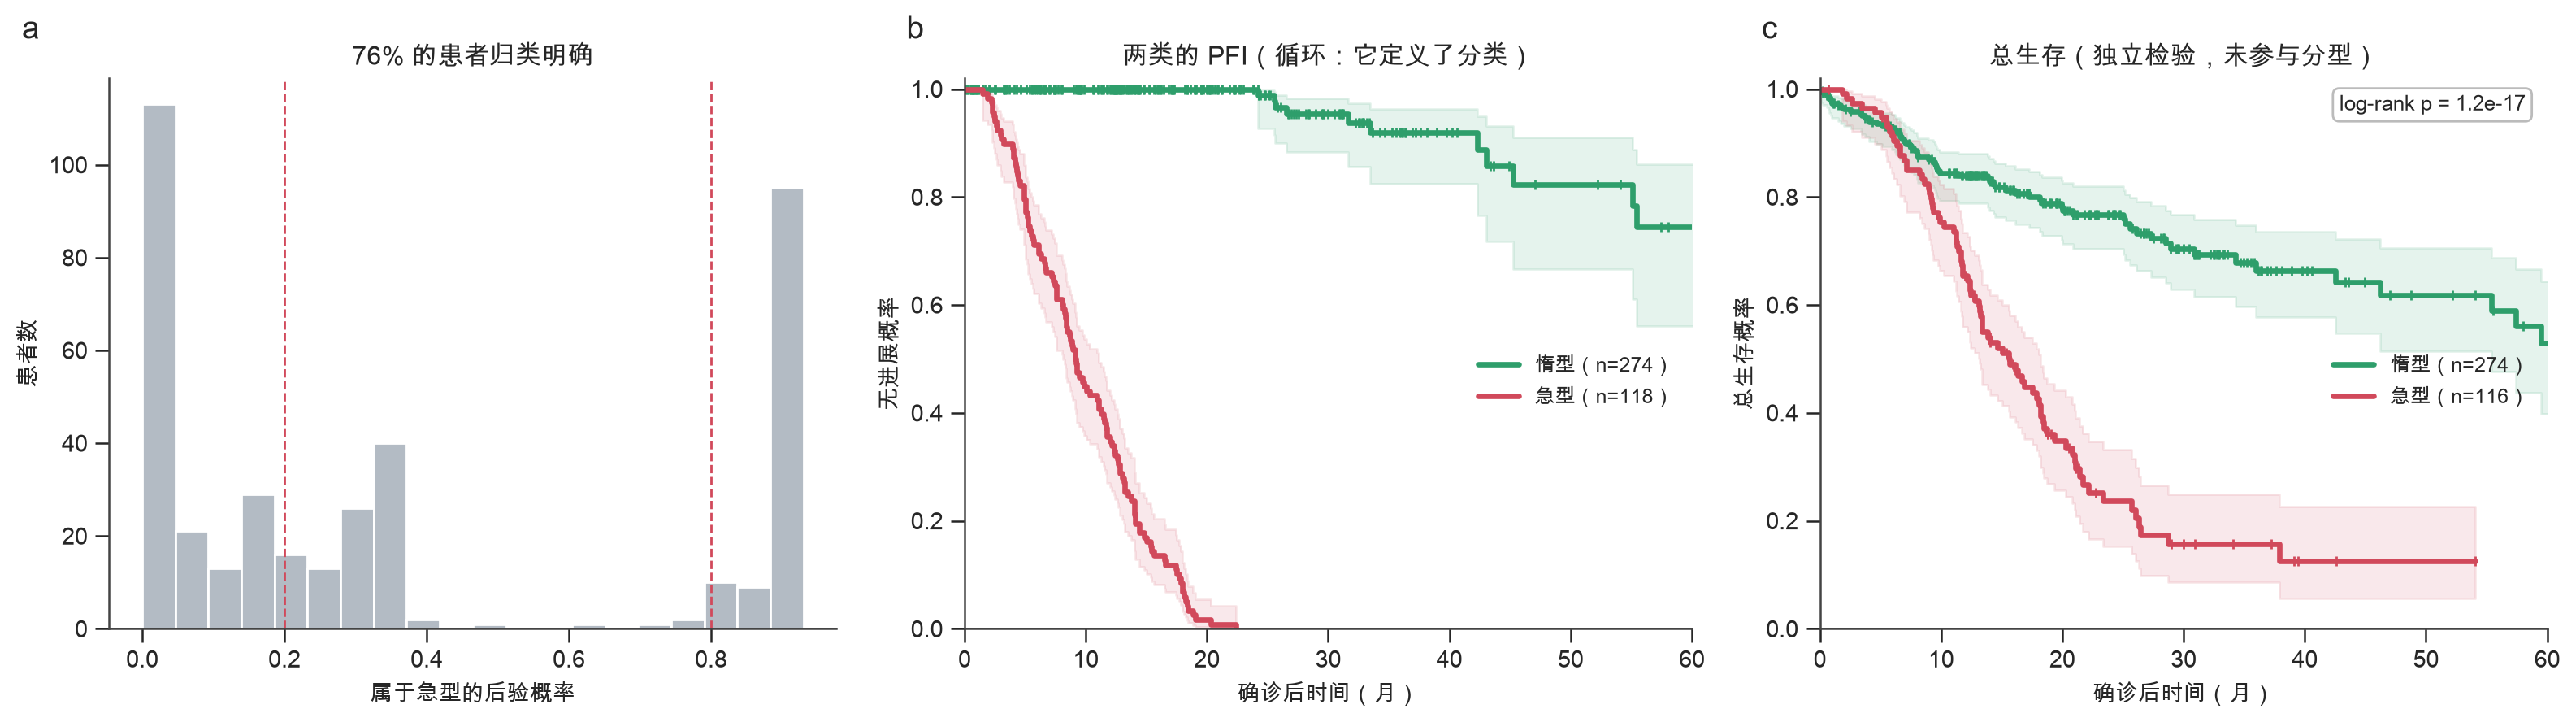

M1 组 27 例：PFI 中位 4.6 个月；事件率 44%


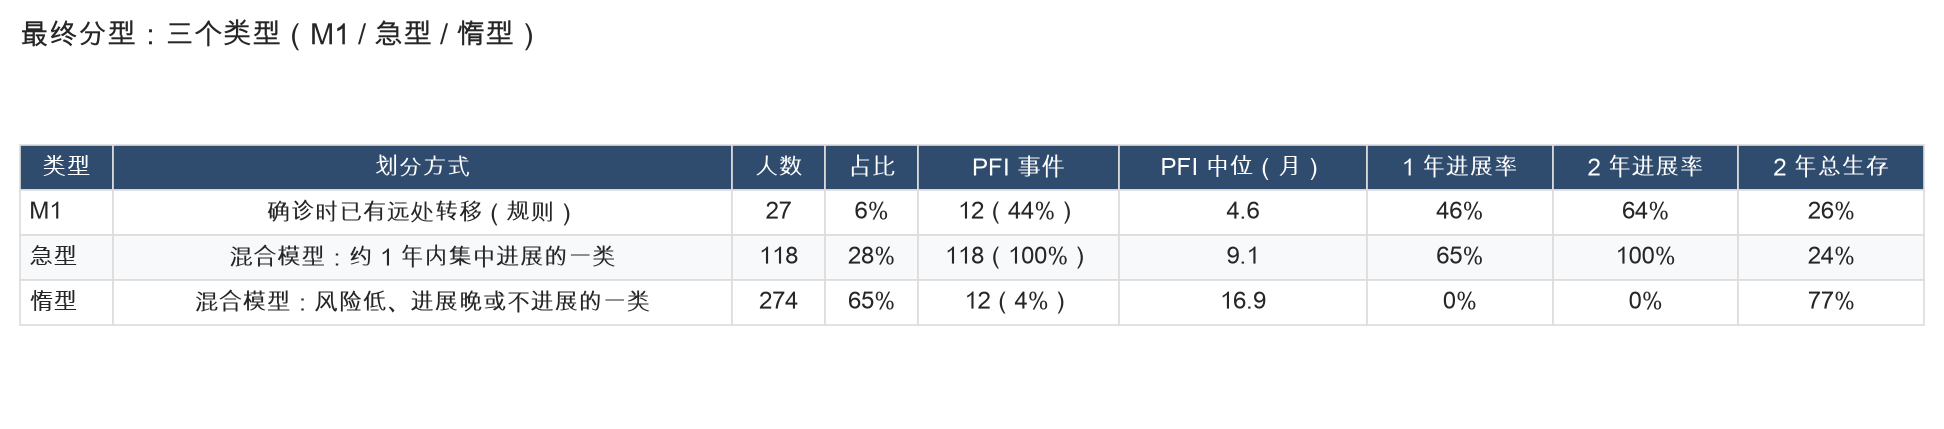

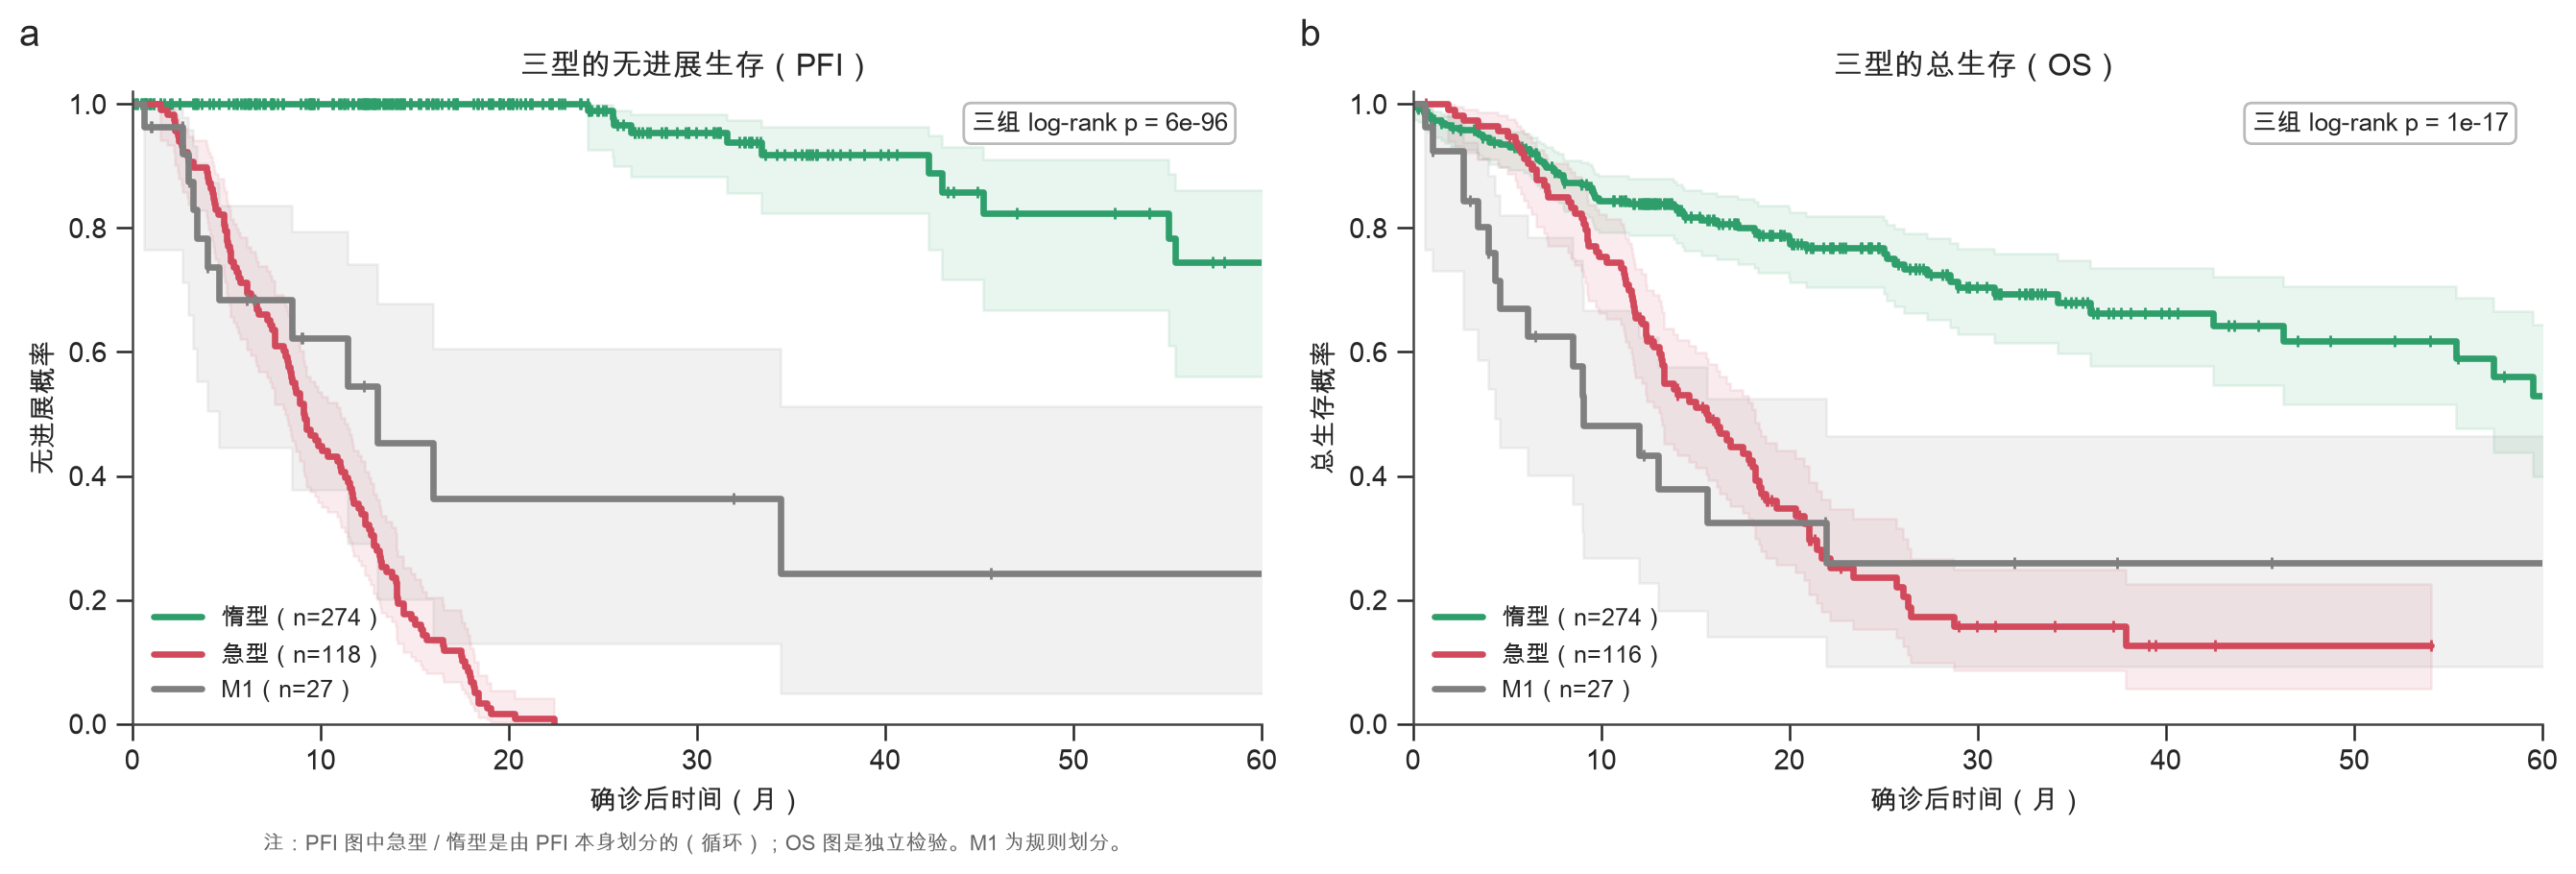

In [13]:
RFIN = MIX[("wb", "2 classes")]
_med = [mix_median(RFIN, j) for j in range(2)]; _fj = int(np.argmin(_med))
post_fast = pd.Series(RFIN["R"][:, _fj], index=idsP, name="P_fast")
FAST_MED, SLOW_MED = _med[_fj] * 12, _med[1 - _fj] * 12
FAST_SHARE = RFIN["pi"][_fj]
CONF = ((post_fast > 0.8) | (post_fast < 0.2))                 # 标签确定者：训练只用这些人
SUBTYPE = pd.Series(np.where(post_fast > 0.5, "Fast", "Slow"), index=idsP, name="Subtype")
print(f"急型：占 {FAST_SHARE:.1%}，中位 PFI {FAST_MED:.1f} 个月；惰型：中位 {SLOW_MED:.0f} 个月")
print(f"硬划分：急型 {int((SUBTYPE=='Fast').sum())} / 惰型 {int((SUBTYPE=='Slow').sum())}；后验确定（>0.8 或 <0.2）{int(CONF.sum())} 人（{CONF.mean():.0%}）；不确定 {int((~CONF).sum())} 人，其中无事件 {(eP[~CONF.values]==0).mean():.0%}")
print("急型里事件发生时间(月) 最小/中位/最大:", *(np.round([tP[(SUBTYPE.values=='Fast') & (eP==1)].min()*12, np.median(tP[(SUBTYPE.values=='Fast') & (eP==1)])*12, tP[(SUBTYPE.values=='Fast') & (eP==1)].max()*12], 0)))
_slow_ev = (SUBTYPE.values == "Slow") & (eP == 1)
print(f"惰型里的事件：{int(_slow_ev.sum())} 例，发生时间 ≥ {tP[_slow_ev].min()*12:.0f} 个月")
print(f"硬划分与规则「2 年内是否进展」的一致率: {(((eP==1)&(tP<=2)).astype(int) == (SUBTYPE.values=='Fast').astype(int)).mean():.1%}")

# 分型的预后验证：KM 与 OS
dfK = pd.DataFrame({"t": tP * 12, "e": eP, "grp": SUBTYPE.values}, index=idsP)
dfK["OS_t"] = SURVP.loc[idsP, "OS.time"].values / 30.4375; dfK["OS_e"] = SURVP.loc[idsP, "OS"].values
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 1]))
ax = axes[0]
sns.histplot(post_fast, bins=20, color="#9AA5B1", edgecolor="white", ax=ax)
ax.axvline(.2, c="#D1495B", ls="--", lw=1); ax.axvline(.8, c="#D1495B", ls="--", lw=1)
ax.set(xlabel="属于急型的后验概率", ylabel="患者数", title=f"{CONF.mean():.0%} 的患者归类明确"); panel_label(ax, "a")
ax = axes[1]
for g_, c_ in [("Slow", "#2E9E6B"), ("Fast", "#D1495B")]:
    s_ = dfK[dfK.grp == g_]
    KaplanMeierFitter().fit(s_.t, s_.e, label=f"{ {'Slow': '惰型', 'Fast': '急型'}[g_] }（n={len(s_)}）").plot_survival_function(ax=ax, color=c_, lw=2.4, ci_alpha=0.12, show_censors=True, censor_styles=dict(ms=4.5, marker="|", mew=1))
ax.set(xlim=(0, 60), ylim=(0, 1.02), xlabel="确诊后时间（月）", ylabel="无进展概率", title="两类的 PFI（循环：它定义了分类）"); ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.45)); panel_label(ax, "b", -0.08)
ax = axes[2]
d2_ = dfK[(dfK.OS_t > 0)].dropna(subset=["OS_t", "OS_e"])
for g_, c_ in [("Slow", "#2E9E6B"), ("Fast", "#D1495B")]:
    s_ = d2_[d2_.grp == g_]
    KaplanMeierFitter().fit(s_.OS_t, s_.OS_e, label=f"{ {'Slow': '惰型', 'Fast': '急型'}[g_] }（n={len(s_)}）").plot_survival_function(ax=ax, color=c_, lw=2.4, ci_alpha=0.12, show_censors=True, censor_styles=dict(ms=4.5, marker="|", mew=1))
p_os_sub = multivariate_logrank_test(d2_.OS_t, d2_.grp, d2_.OS_e).p_value
ax.set(xlim=(0, 60), ylim=(0, 1.02), xlabel="确诊后时间（月）", ylabel="总生存概率", title="总生存（独立检验，未参与分型）")
ax.text(0.97, 0.97, f"log-rank p = {p_os_sub:.2g}", transform=ax.transAxes, ha="right", va="top", fontsize=9.5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#BBB")); ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.45)); panel_label(ax, "c", -0.08)
fig.tight_layout(); savefig(fig, "A2_subtype_definition")

# M1 组：确诊即转移
m1_ids = SURVP.index[is_m1 & has_pfi]
print(f"M1 组 {len(m1_ids)} 例：PFI 中位 {SURVP.loc[m1_ids,'PFI.time'].median()/30.4375:.1f} 个月；事件率 {SURVP.loc[m1_ids,'PFI'].mean():.0%}")


# ---------- 最终三型：M1 / 急型 / 惰型 ----------
m1_ids = SURVP.index[is_m1 & has_pfi]
FINAL3 = pd.concat([pd.Series("M1", index=m1_ids), SUBTYPE.rename("T")]).rename("三型")
FINAL3.loc[SUBTYPE.index] = SUBTYPE.map({"Fast": "急型", "Slow": "惰型"})
dfF = pd.DataFrame({"type": FINAL3, "t": SURVP.loc[FINAL3.index, "PFI.time"] / 30.4375, "e": SURVP.loc[FINAL3.index, "PFI"],
                    "OS_t": SURVP.loc[FINAL3.index, "OS.time"] / 30.4375, "OS_e": SURVP.loc[FINAL3.index, "OS"]})
rows3 = []
for nm, how in [("M1", "确诊时已有远处转移（规则）"), ("急型", "混合模型：约 1 年内集中进展的一类"), ("惰型", "混合模型：风险低、进展晚或不进展的一类")]:
    g = dfF[dfF.type == nm]; k_ = KaplanMeierFitter().fit(g.t, g.e)
    go = g.dropna(subset=["OS_t", "OS_e"]); go = go[go.OS_t > 0]                     # OS 时间有 2 例缺失，先剔除
    ko = KaplanMeierFitter().fit(go.OS_t, go.OS_e)
    rows3.append({"类型": nm, "划分方式": how, "人数": len(g), "占比": f"{len(g)/len(dfF):.0%}", "PFI 事件": f"{int(g.e.sum())}（{g.e.mean():.0%}）",
                  "PFI 中位（月）": f"{g.t.median():.1f}", "1 年进展率": f"{1-float(k_.predict(12)):.0%}", "2 年进展率": f"{1-float(k_.predict(24)):.0%}",
                  "2 年总生存": f"{float(ko.predict(24)):.0%}"})
T3 = pd.DataFrame(rows3).set_index("类型")
show_table(T3, "T_A6_three_types", "最终分型：三个类型（M1 / 急型 / 惰型）", wrap=22, fs=8.5)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
TCOL = {"M1": "#7F7F7F", "急型": "#D1495B", "惰型": "#2E9E6B"}
for ax, (tc, ec, ylab, ttl) in zip(axes, [("t", "e", "无进展概率", "三型的无进展生存（PFI）"), ("OS_t", "OS_e", "总生存概率", "三型的总生存（OS）")]):
    dd = dfF.dropna(subset=[tc, ec]); dd = dd[dd[tc] > 0]
    for nm in ["惰型", "急型", "M1"]:
        g = dd[dd.type == nm]
        KaplanMeierFitter().fit(g[tc], g[ec], label=f"{nm}（n={len(g)}）").plot_survival_function(ax=ax, color=TCOL[nm], lw=2.4, ci_alpha=0.1, show_censors=True, censor_styles=dict(ms=4, marker="|", mew=1))
    p3 = multivariate_logrank_test(dd[tc], dd.type, dd[ec]).p_value
    ax.set(xlim=(0, 60), ylim=(0, 1.02), xlabel="确诊后时间（月）", ylabel=ylab, title=ttl)
    ax.text(0.97, 0.97, f"三组 log-rank p = {p3:.1g}", transform=ax.transAxes, ha="right", va="top", fontsize=9.5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#BBB"))
    ax.legend(loc="lower left")
panel_label(axes[0], "a", -0.1); panel_label(axes[1], "b", -0.1)
axes[0].text(0.5, -0.2, "注：PFI 图中急型 / 惰型是由 PFI 本身划分的（循环）；OS 图是独立检验。M1 为规则划分。", transform=axes[0].transAxes, ha="center", fontsize=8, color="#666")
fig.tight_layout(); savefig(fig, "A3_three_types")

In [14]:
_lrt12 = LRT[(LRT.index == "1 class → 2 classes") & (LRT.family == "Weibull")].iloc[0]
_lrt12_ln = LRT[(LRT.index == "1 class → 2 classes") & (LRT.family == "Log-normal")].iloc[0]
_lrt23 = LRT[LRT.index == "2 classes → 3: fast + late + non-progressing"].iloc[0]
_lrt23b = LRT[LRT.index == "2: fast + non-progressing → 3: fast + late + non-progressing"].iloc[0]
_ln_bic = A2[A2.family == "Log-normal"].set_index("model")["BIC"]
_fits = A3.loc[["1 class", "2 classes", "3 classes (fast+late+non-prog.)"], "max |dev|"]
_best_bic = A2[A2.family == "Weibull"].set_index("model")["BIC"]
_sb = STAB["bootstrap (60×)"] / STAB["bootstrap (60×)"].sum(); _sh = STAB["half-split (20×2)"] / STAB["half-split (20×2)"].sum()
_s3b = _sb.reindex(["3: fast + late + non-prog.", "3 classes"]).fillna(0).sum(); _s3h = _sh.reindex(["3: fast + late + non-prog.", "3 classes"]).fillna(0).sum()
_s2b = _sb.reindex(["2 classes", "2: fast + non-progressing"]).fillna(0).sum(); _s2h = _sh.reindex(["2 classes", "2: fast + non-progressing"]).fillna(0).sum()
md(f"""### 阶段 A 结论：分型由数据定义，为 2 类

**只用了什么** PFI 的时间与是否事件（{nP} 例 M1 以外的患者，{int(eP.sum())} 个事件，中位随访 {np.median(tP):.2f} 年）。临床变量与组学没有参与分型。M1（{len(m1_ids)} 例）确诊时即已转移，单列。

**为什么是 2 类（五条独立证据）**
1. **风险率有"高峰—骤降"的形状**（A1，不依赖任何模型）：0.5–1.5 年风险率 {HZ.loc['0.5-1 y','hazard_per_year']:.2f}–{HZ.loc['1-1.5 y','hazard_per_year']:.2f}/年，1.5–2 年降到 {HZ.loc['1.5-2 y','hazard_per_year']:.2f}，之后低而平。
2. **1 类不够**（A4 参数自举 LRT）：1→2 类 2ΔlogL = {_lrt12.observed_2dLL:.1f}（Weibull；零分布 95% 分位 {_lrt12.null_95pct:.1f}，p ≈ {_lrt12.p:.3f}）、{_lrt12_ln.observed_2dLL:.1f}（对数正态；零分布 95% 分位 {_lrt12_ln.null_95pct:.1f}，p ≈ {_lrt12_ln.p:.3f}）。
3. **拟合贴合**（A3）：1 类最大偏差 {_fits.iloc[0]:.3f}，2 类 {_fits.iloc[1]:.3f}，3 类 {_fits.iloc[2]:.3f}。
4. **BIC**（Weibull）：1 类 {_best_bic['1 class']:.0f}，**2 类 {_best_bic['2 classes']:.0f}**，3 类（含晚发）{_best_bic['3: fast + late + non-progressing']:.0f}；对数正态：1 类 {_ln_bic['1 class']:.0f}，2 类 {_ln_bic['2 classes']:.0f}，急型 + 不进展 {_ln_bic['2: fast + non-progressing']:.0f}。
5. **参数稳定**（A4）：急型中位 PFI {PAR2.loc['fast-class median PFI (months)','bootstrap median']:.1f} 个月（自举 95% 区间 {PAR2.loc['fast-class median PFI (months)','2.5%']:.1f}–{PAR2.loc['fast-class median PFI (months)','97.5%']:.1f}），占比 {PAR2.loc['fast-class share','bootstrap median']:.0%}。

**不能说的** ① **类数不是"恰好 2"，而是"至少 2，第 3 类没有可靠证据"**：Weibull 下 BIC 最优是 2 类，对数正态下最优是"急型 + 不进展"（BIC {_ln_bic['2: fast + non-progressing']:.0f}，2 类 {_ln_bic['2 classes']:.0f}）——两种分布族选出的结构不同，但都是 2 个类。2→3 类（含晚发）的 BIC 仅差 {_best_bic['3: fast + late + non-progressing'] - _best_bic['2 classes']:.1f}，LRT {_lrt23.observed_2dLL:.1f} 对零分布 95% 分位 {_lrt23.null_95pct:.1f}（p ≈ {_lrt23.p:.3f}，未达 0.05）；重抽样下 BIC 选 3 类结构的比例：自举 {_s3b:.0%}、对半拆分 {_s3h:.0%}。所谓"晚发类"只由 2 年后才发生的约 13 个事件撑起，TCGA-STAD 的随访太短。注意"急型 + 不进展 → 3 类"的 LRT 是显著的（{_lrt23b.observed_2dLL:.1f}，p ≈ {_lrt23b.p:.3f}）：这说明"惰型"里不是"全都永不进展"，有少数 2 年后才进展的人。② **"惰型"究竟是"进展很慢"还是"永不进展"，现有随访下分不开。**③ 分型含 {(~CONF).mean():.0%} 的"后验不确定"患者，其中 {(eP[~CONF.values]==0).mean():.0%} 是随访不足的无事件者。

**结局定义的选择**（A5）：PFI 的样本最多（{int(A5.loc['PFI','n'])} 例）且 2 类有 BIC 支持；PFI 把死亡也算作进展，其中 {N_DEATH_EV}/{N_PFI_EV} 个事件是以死亡计的（可能死于非肿瘤原因），所以做了对照——把这些事件改为删失（即只记"至少到那时没进展"）；改完后急型中位仍为 {A5.loc['PFI (deaths censored)','fast_median_months']:.1f} 个月（原 {A5.loc['PFI','fast_median_months']:.1f}），说明急型不是早期死亡造成的；DFI 只有 {int(A5.loc['DFI','events'])} 个事件，BIC 选 {A5.loc['DFI','best_by_BIC']}，不支持 2 类。因此用 PFI。

**最终分型是三个类型**：**M1**（确诊即有远处转移，{len(m1_ids)} 例，按规则划分）、**急型**（{int((SUBTYPE=='Fast').sum())} 例）、**惰型**（{int((SUBTYPE=='Slow').sum())} 例）；后两者由混合模型对 PFI 聚类得到。急型占非 M1 患者的 {FAST_SHARE:.0%}（中位 PFI {FAST_MED:.1f} 个月），惰型中位 {SLOW_MED:.0f} 个月；硬划分与规则「2 年内是否进展」一致率 {(((eP==1)&(tP<=2)).astype(int) == (SUBTYPE.values=='Fast').astype(int)).mean():.0%}。独立检验：急型的总生存也更差（log-rank p = {p_os_sub:.2g}）。
""")

### 阶段 A 结论：分型由数据定义，为 2 类

**只用了什么** PFI 的时间与是否事件（392 例 M1 以外的患者，130 个事件，中位随访 1.10 年）。临床变量与组学没有参与分型。M1（27 例）确诊时即已转移，单列。

**为什么是 2 类（五条独立证据）**
1. **风险率有"高峰—骤降"的形状**（A1，不依赖任何模型）：0.5–1.5 年风险率 0.32–0.38/年，1.5–2 年降到 0.14，之后低而平。
2. **1 类不够**（A4 参数自举 LRT）：1→2 类 2ΔlogL = 49.8（Weibull；零分布 95% 分位 9.1，p ≈ 0.016）、18.7（对数正态；零分布 95% 分位 7.4，p ≈ 0.016）。
3. **拟合贴合**（A3）：1 类最大偏差 0.083，2 类 0.020，3 类 0.013。
4. **BIC**（Weibull）：1 类 668，**2 类 637**，3 类（含晚发）639；对数正态：1 类 638，2 类 637，急型 + 不进展 627。
5. **参数稳定**（A4）：急型中位 PFI 10.5 个月（自举 95% 区间 8.9–12.3），占比 37%。

**不能说的** ① **类数不是"恰好 2"，而是"至少 2，第 3 类没有可靠证据"**：Weibull 下 BIC 最优是 2 类，对数正态下最优是"急型 + 不进展"（BIC 627，2 类 637）——两种分布族选出的结构不同，但都是 2 个类。2→3 类（含晚发）的 BIC 仅差 2.5，LRT 3.5 对零分布 95% 分位 3.3（p ≈ 0.066，未达 0.05）；重抽样下 BIC 选 3 类结构的比例：自举 35%、对半拆分 5%。所谓"晚发类"只由 2 年后才发生的约 13 个事件撑起，TCGA-STAD 的随访太短。注意"急型 + 不进展 → 3 类"的 LRT 是显著的（22.7，p ≈ 0.016）：这说明"惰型"里不是"全都永不进展"，有少数 2 年后才进展的人。② **"惰型"究竟是"进展很慢"还是"永不进展"，现有随访下分不开。**③ 分型含 24% 的"后验不确定"患者，其中 92% 是随访不足的无事件者。

**结局定义的选择**（A5）：PFI 的样本最多（392 例）且 2 类有 BIC 支持；PFI 把死亡也算作进展，其中 21/130 个事件是以死亡计的（可能死于非肿瘤原因），所以做了对照——把这些事件改为删失（即只记"至少到那时没进展"）；改完后急型中位仍为 10.5 个月（原 10.4），说明急型不是早期死亡造成的；DFI 只有 46 个事件，BIC 选 2c，不支持 2 类。因此用 PFI。

**最终分型是三个类型**：**M1**（确诊即有远处转移，27 例，按规则划分）、**急型**（118 例）、**惰型**（274 例）；后两者由混合模型对 PFI 聚类得到。急型占非 M1 患者的 37%（中位 PFI 10.4 个月），惰型中位 118 个月；硬划分与规则「2 年内是否进展」一致率 100%。独立检验：急型的总生存也更差（log-rank p = 1.2e-17）。


---
# 阶段 B：多组学数据读入、对齐与无监督预过滤

六种组学全部读入并使用：

| 模态 | 文件 | 原始维度 | 预处理 |
|---|---|---|---|
| RNA | `HiSeqV2` | 20,530 基因 | 低表达过滤 → 性别相关基因剔除 → MAD 取 Top |
| Methylation | `HumanMethylation450` + `probeMap` | 485,577 探针 | 探针→基因聚合（均值）→ M 值转换 → MAD 取 Top |
| CNV | `Gistic2` | 24,776 基因 | 低变异过滤 → 相邻基因高度共线性去冗余（取代表基因）|
| Mutation | `mc3` | 40,543 基因 | 突变频率 ≥ 3% 的基因 |
| miRNA | `miRNA_HiSeq` | 2,178 | 缺失率过滤 → 中位数填补 → MAD 取 Top |
| RPPA | `RPPA` | 227 抗体 | 缺失率过滤 → 中位数填补 |

本阶段**只做不看标签的预过滤**（档位①），有监督的筛选放在阶段 C 的交叉验证内部。

对齐规则：条形码保留 `-01` 原发肿瘤；以患者为单位取交集。**不同模态样本数不同**，因此做两套实验：
- **主模型**：RNA + Methylation + CNV + Mutation（样本量大）；
- **全模态模型**：再加入 miRNA + RPPA（样本量减少）——展示"尽量用上数据"与"样本骤减"的权衡。

读取缓存: omics_prefiltered.pkl


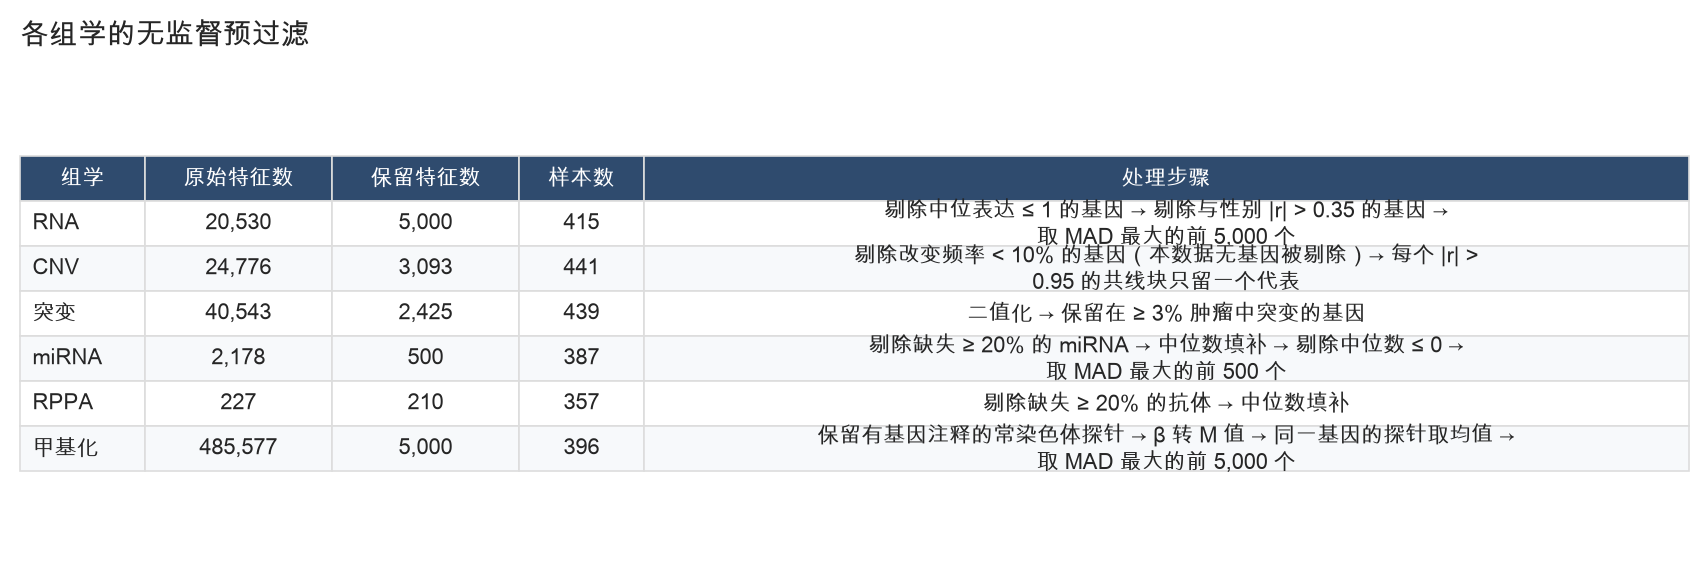

,原始特征数,保留特征数,样本数,处理步骤
组学,,,,
RNA,20530,5000,415,剔除中位表达 ≤ 1 的基因 → 剔除与性别 |r| > 0.35 的基因 → 取 MAD ...
CNV,24776,3093,441,剔除改变频率 < 10% 的基因（本数据无基因被剔除）→ 每个 |r| > 0.95 的共线...
突变,40543,2425,439,二值化 → 保留在 ≥ 3% 肿瘤中突变的基因
miRNA,2178,500,387,剔除缺失 ≥ 20% 的 miRNA → 中位数填补 → 剔除中位数 ≤ 0 → 取 MAD...
RPPA,227,210,357,剔除缺失 ≥ 20% 的抗体 → 中位数填补
甲基化,485577,5000,396,保留有基因注释的常染色体探针 → β 转 M 值 → 同一基因的探针取均值 → 取 MAD ...


In [15]:
CACHE_PRE = CACHE / "omics_prefiltered.pkl"
PRIMARY = set(clin.index)       # 全部原发肿瘤样本（缓存与分型标签无关）


def read_matrix(path, sep="\t"):
    """读取 特征×样本 矩阵，仅保留原发肿瘤（-01）列，并转置为 样本×特征。"""
    hdr = pd.read_csv(path, sep=sep, nrows=0).columns
    use = [hdr[0]] + [c for c in hdr[1:] if c in PRIMARY]
    df = pd.read_csv(path, sep=sep, usecols=use, index_col=0, dtype={c: np.float32 for c in use[1:]})
    return df.T


def mad(x, axis=0):
    med = np.nanmedian(x, axis=axis, keepdims=True)
    return np.nanmedian(np.abs(x - med), axis=axis) * 1.4826


if CACHE_PRE.exists():
    OM, QC = pickle.load(open(CACHE_PRE, "rb"))
    print("读取缓存:", CACHE_PRE.name)
else:
    OM, QC = {}, []           # OM: 模态 → 样本×特征（预过滤后）；QC: 过滤漏斗记录
    # 性别（仅用于识别"性别相关基因"并剔除，不用于任何标签）
    sex = (ENRICH["Sex"] == "Male").astype(float).where(ENRICH["Sex"].notna())

    # ---------- RNA ----------
    t0 = time.time()
    rna = read_matrix(DATA / "TCGA.STAD.sampleMap_HiSeqV2")
    n0 = rna.shape[1]
    rna = rna.loc[:, rna.median() > 1.0]                       # 低表达基因
    n1 = rna.shape[1]
    s_ok = sex.reindex(rna.index).notna().values
    r_sex = pd.Series({g: abs(np.corrcoef(rna.loc[s_ok, g], sex.reindex(rna.index)[s_ok])[0, 1]) for g in rna.columns})
    sexual = r_sex[r_sex > 0.35].index                           # 性别相关（Y 染色体、XIST 等）
    rna = rna.drop(columns=sexual)
    n2 = rna.shape[1]
    OM["RNA_full"] = rna.copy()                                  # 阶段 D 的差异表达/富集分析使用全部 ~1.7 万基因
    keep = pd.Series(mad(rna.values), index=rna.columns).nlargest(5000).index
    OM["RNA"] = rna[keep]
    QC.append(("RNA", n0, n1, n2, 5000, f"低表达(median≤1)→{n1}; 性别相关(|r|>0.35)剔除{len(sexual)}→{n2}; MAD Top5000"))
    print(f"RNA done {time.time()-t0:.0f}s", rna.shape, "| 例: 被剔除的性别相关基因", list(sexual[:8]))

    # ---------- CNV ----------
    t0 = time.time()
    cnv = read_matrix(DATA / "TCGA.STAD.sampleMap_Gistic2_CopyNumber_Gistic2_all_thresholded.by_genes")
    n0 = cnv.shape[1]
    OM["CNV_burden"] = pd.DataFrame({"CNV_altered_frac": (cnv != 0).mean(axis=1), "CNV_gain_frac": (cnv > 0).mean(axis=1),
                                     "CNV_loss_frac": (cnv < 0).mean(axis=1)})          # 每例"基因组改变比例"（染色体不稳定的代理）
    OM["CNV_full_sel"] = cnv[[g for g in ["ERBB2", "EGFR", "MYC", "CCNE1", "KRAS", "GATA4", "GATA6", "VEGFA", "MET", "FGFR2", "CDK6", "CDKN2A", "SMAD4", "APC"] if g in cnv.columns]]
    cnv = cnv.loc[:, (cnv != 0).mean() >= 0.10]                  # 至少 10% 样本有改变
    n1 = cnv.shape[1]
    # 相邻基因 CNV 高度共线（同一染色体片段）：贪心去冗余，|r|>0.95 只留一个代表
    C = np.corrcoef(cnv.values.T)
    keep_idx, dropped = [], np.zeros(len(C), bool)
    for i in range(len(C)):
        if dropped[i]: continue
        keep_idx.append(i); dropped |= (np.abs(C[i]) > 0.95) & (np.arange(len(C)) > i)
    cnv = cnv.iloc[:, keep_idx]
    OM["CNV"] = cnv
    QC.append(("CNV", n0, n1, cnv.shape[1], cnv.shape[1], f"改变频率≥10%→{n1}; |r|>0.95 共线去冗余→{cnv.shape[1]}"))
    print(f"CNV done {time.time()-t0:.0f}s", cnv.shape)

    # ---------- Mutation ----------
    t0 = time.time()
    mut = read_matrix(DATA / "mc3_gene_level_STAD_mc3_gene_level.txt")
    n0 = mut.shape[1]
    mut = (mut > 0).astype(np.float32)
    OM["Mut_burden"] = pd.DataFrame({"Mutated_genes": mut.sum(axis=1)})                # 每例突变基因数（TMB 的代理）
    OM["Mut_full_sel"] = mut[[g for g in ["TP53", "ARID1A", "PIK3CA", "KRAS", "CDH1", "RHOA", "SMAD4", "APC", "ERBB2", "ERBB3", "CTNNB1", "MUC16", "LRP1B", "FAT4", "TTN", "PTEN", "BRAF", "NRAS", "MLH1", "B2M"] if g in mut.columns]]
    mut = mut.loc[:, mut.mean() >= 0.03]
    OM["Mutation"] = mut
    QC.append(("Mutation", n0, mut.shape[1], mut.shape[1], mut.shape[1], f"突变频率≥3%→{mut.shape[1]}"))
    print(f"Mutation done {time.time()-t0:.0f}s", mut.shape)

    # ---------- miRNA ----------
    t0 = time.time()
    mir = read_matrix(DATA / "TCGA.STAD.sampleMap_miRNA_HiSeq_gene")
    n0 = mir.shape[1]
    mir = mir.loc[:, mir.isna().mean() < 0.20]
    n1 = mir.shape[1]
    mir = mir.fillna(mir.median())
    mir = mir.loc[:, mir.median() > 0]
    keep = pd.Series(mad(mir.values), index=mir.columns).nlargest(min(500, mir.shape[1])).index
    OM["miRNA"] = mir[keep]
    QC.append(("miRNA", n0, n1, mir.shape[1], len(keep), f"缺失<20%→{n1}; 中位数填补; 低表达剔除→{mir.shape[1]}; MAD Top{len(keep)}"))
    print(f"miRNA done {time.time()-t0:.0f}s", OM["miRNA"].shape)

    # ---------- RPPA ----------
    t0 = time.time()
    rp = read_matrix(DATA / "TCGA.STAD.sampleMap_RPPA")
    n0 = rp.shape[1]
    rp = rp.loc[:, rp.isna().mean() < 0.20]
    rp = rp.fillna(rp.median())
    OM["RPPA"] = rp
    QC.append(("RPPA", n0, rp.shape[1], rp.shape[1], rp.shape[1], f"缺失<20%→{rp.shape[1]}; 中位数填补"))
    print(f"RPPA done {time.time()-t0:.0f}s", rp.shape)

    # ---------- 甲基化（1.2 GB，按块读取，探针→基因聚合）----------
    t0 = time.time()
    pm = pd.read_csv(DATA / "probeMap_illuminaMethyl450_hg19_GPL16304_TCGAlegacy", sep="\t")
    pm.columns = ["id", "gene", "chrom", "start", "end", "strand"]
    pm = pm[(pm.gene != ".") & (~pm.chrom.isin(["chrX", "chrY"]))]           # 剔除无基因注释探针与性染色体探针
    probe2genes = {r.id: r.gene.split(",") for r in pm.itertuples()}
    hdr = pd.read_csv(DATA / "TCGA.STAD.sampleMap_HumanMethylation450", sep="\t", nrows=0).columns
    use = [hdr[0]] + [c for c in hdr[1:] if c in PRIMARY]
    n_probe_total = 0
    agg_sum, agg_cnt = {}, {}
    for chunk in pd.read_csv(DATA / "TCGA.STAD.sampleMap_HumanMethylation450", sep="\t", usecols=use, index_col=0,
                             chunksize=40000, dtype={c: np.float32 for c in use[1:]}):
        n_probe_total += len(chunk)
        chunk = chunk[chunk.index.isin(probe2genes)]
        chunk = chunk[chunk.isna().mean(axis=1) < 0.2]
        M = np.log2((chunk.clip(1e-3, 1 - 1e-3)) / (1 - chunk.clip(1e-3, 1 - 1e-3)))   # β → M 值
        for pid, row in zip(M.index, M.values):
            for g in probe2genes[pid]:
                if g in agg_sum:
                    agg_sum[g] = agg_sum[g] + np.nan_to_num(row); agg_cnt[g] += 1
                else:
                    agg_sum[g] = np.nan_to_num(row).copy(); agg_cnt[g] = 1
    samples = [c for c in use[1:]]
    meth = pd.DataFrame({g: agg_sum[g] / agg_cnt[g] for g in agg_sum}, index=samples).astype(np.float32)
    n1 = meth.shape[1]
    keep = pd.Series(mad(meth.values), index=meth.columns).nlargest(5000).index
    OM["Methylation"] = meth[keep]
    QC.append(("Methylation", n_probe_total, len(probe2genes), n1, 5000,
               f"有基因注释且非性染色体探针 {len(probe2genes)}; 聚合到 {n1} 个基因(M值均值); MAD Top5000"))
    print(f"Methylation done {time.time()-t0:.0f}s", OM["Methylation"].shape)

    pickle.dump((OM, QC), open(CACHE_PRE, "wb"))
    print("已缓存预过滤结果 →", CACHE_PRE.name)

# ---------- 过滤漏斗 ----------
QCdf = pd.DataFrame(QC, columns=["Modality", "raw_features", "after_filter1", "after_filter2", "kept", "steps"]).set_index("Modality")
QCdf["samples"] = {m: OM[m].shape[0] for m in QCdf.index}
# 表格图里只用英文（图字体没有中文字形）：步骤描述用数字拼出来，不依赖缓存里的中文记录
_n = lambda m: int(QCdf.loc[m, "kept"])
_STEPS_EN = {
    "RNA": "剔除中位表达 ≤ 1 的基因 → 剔除与性别 |r| > 0.35 的基因 → 取 MAD 最大的前 5,000 个",
    "Methylation": "保留有基因注释的常染色体探针 → β 转 M 值 → 同一基因的探针取均值 → 取 MAD 最大的前 5,000 个",
    "CNV": "剔除改变频率 < 10% 的基因（本数据无基因被剔除）→ 每个 |r| > 0.95 的共线块只留一个代表",
    "Mutation": "二值化 → 保留在 ≥ 3% 肿瘤中突变的基因",
    "miRNA": "剔除缺失 ≥ 20% 的 miRNA → 中位数填补 → 剔除中位数 ≤ 0 → 取 MAD 最大的前 500 个",
    "RPPA": "剔除缺失 ≥ 20% 的抗体 → 中位数填补",
}
QCshow = QCdf[["raw_features", "kept", "samples"]].copy()
QCshow["steps"] = [_STEPS_EN.get(m, "") for m in QCshow.index]
QCshow = QCshow.rename(columns={"raw_features": "原始特征数", "kept": "保留特征数", "samples": "样本数", "steps": "处理步骤"}).rename(index={"RNA": "RNA", "Methylation": "甲基化", "CNV": "CNV", "Mutation": "突变", "miRNA": "miRNA", "RPPA": "RPPA"}).rename_axis("组学")
show_table(QCshow, "T_B1_prefilter_funnel", "各组学的无监督预过滤", fmt={"原始特征数": "{:,.0f}", "保留特征数": "{:,.0f}", "样本数": "{:.0f}"}, wrap=40, fs=8)

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


RNA          与分型患者交集: 367
Methylation  与分型患者交集: 366
CNV          与分型患者交集: 390
Mutation     与分型患者交集: 389
miRNA        与分型患者交集: 360
RPPA         与分型患者交集: 315

4 模态可用患者 = 343；6 模态可用患者 = 269
4 模态患者中急型（硬划分）: 108 / 标签确定者: 268


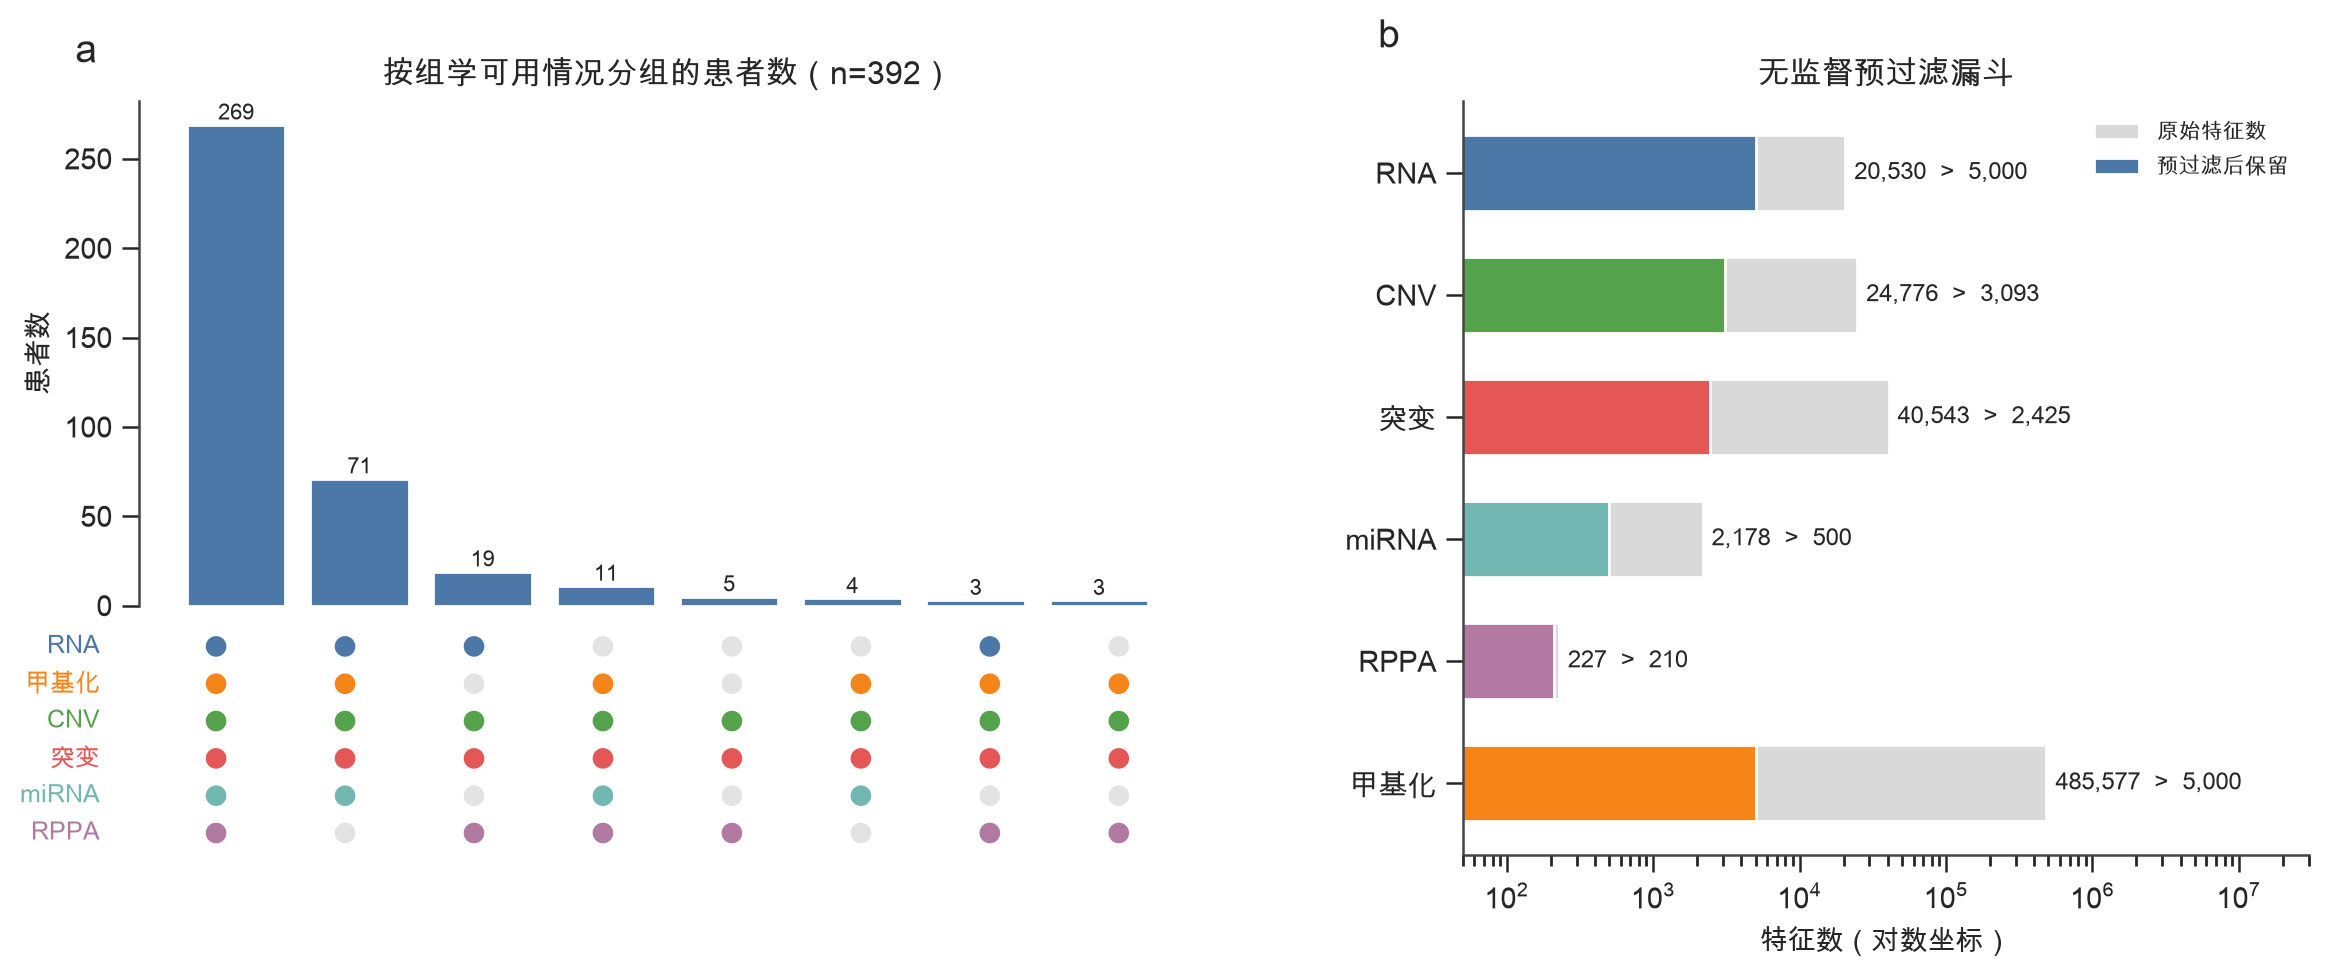

In [16]:
# ---------- 样本对齐 ----------
# 分型对象 = 阶段 A 中 M1 以外、有 PFI 的患者（PTS）；组学按患者取交集
MODS_MAIN = ["RNA", "Methylation", "CNV", "Mutation"]
MODS_ALL = MODS_MAIN + ["miRNA", "RPPA"]
SUB = SUBTYPE.copy()                                     # 以样本条码为 index，值为 "Fast" / "Slow"（含后验确定性）
sets = {m: set(OM[m].index) & set(SUB.index) for m in MODS_ALL}
for m in MODS_ALL: print(f"{m:12s} 与分型患者交集: {len(sets[m])}")
ids_main = sorted(set.intersection(*[sets[m] for m in MODS_MAIN]))
ids_all = sorted(set.intersection(*[sets[m] for m in MODS_ALL]))
print(f"\n4 模态可用患者 = {len(ids_main)}；6 模态可用患者 = {len(ids_all)}")
print("4 模态患者中急型（硬划分）:", int((SUB.loc[ids_main] == "Fast").sum()), "/ 标签确定者:", int(CONF.loc[ids_main].sum()))

# ----- 图 B-1：样本可用性（UpSet 风格）+ 特征漏斗 -----
fig = plt.figure(figsize=(14, 4.9))
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.28)
sub_ax = gs[0].subgridspec(2, 1, height_ratios=[2.4, 1.1], hspace=0.05)
axb, axm = fig.add_subplot(sub_ax[0]), fig.add_subplot(sub_ax[1])
allmods = MODS_ALL
pat = pd.DataFrame({m: [i in sets[m] for i in SUB.index] for m in allmods}, index=SUB.index)
combo = pat.apply(lambda r: tuple(r.values), axis=1).value_counts()
combo = combo[combo >= 3].head(12)
order_c = combo.sort_values(ascending=False)
axb.bar(range(len(order_c)), order_c.values, color="#4C78A8", edgecolor="white")
for i, v in enumerate(order_c.values): axb.text(i, v + 3, str(v), ha="center", fontsize=8)
axb.set_xticks([]); axb.set_ylabel("患者数"); axb.spines["bottom"].set_visible(False)
axb.set_title("按组学可用情况分组的患者数（n=%d）" % len(SUB))
panel_label(axb, "a", -0.06)
for j, m in enumerate(allmods):
    for i, key in enumerate(order_c.index):
        axm.scatter(i, j, s=55, c=MOD_COLORS[m] if key[j] else "#E3E3E3", edgecolor="none")
    axm.text(-0.9, j, {"RNA": "RNA", "Methylation": "甲基化", "CNV": "CNV", "Mutation": "突变", "miRNA": "miRNA", "RPPA": "RPPA"}[m], ha="right", va="center", fontsize=9, color=MOD_COLORS[m], fontweight="bold")
axm.set_ylim(-0.6, len(allmods) - 0.4); axm.invert_yaxis(); axm.set_xlim(-0.6, len(order_c) - 0.4)
axm.axis("off")

axf = fig.add_subplot(gs[1])
ypos = np.arange(len(QCdf))[::-1]
axf.barh(ypos, QCdf["raw_features"], color="#D9D9D9", height=0.62, label="原始特征数")
axf.barh(ypos, QCdf["kept"], color=[MOD_COLORS[m] for m in QCdf.index], height=0.62, label="预过滤后保留")
axf.set_xscale("log"); axf.set_yticks(ypos); axf.set_yticklabels([{"RNA": "RNA", "Methylation": "甲基化", "CNV": "CNV", "Mutation": "突变", "miRNA": "miRNA", "RPPA": "RPPA"}[m] for m in QCdf.index])
for y, (r, k) in zip(ypos, zip(QCdf["raw_features"], QCdf["kept"])):
    axf.text(r * 1.15, y, f"{r:,}  >  {k:,}", va="center", fontsize=8.5)
axf.set_xlim(50, 3e7); axf.set_xlabel("特征数（对数坐标）")
axf.set_title("无监督预过滤漏斗"); panel_label(axf, "b", -0.1)
axf.legend(loc="upper right", fontsize=8, bbox_to_anchor=(1.0, 1.0))
savefig(fig, "B1_data_overview")

**阶段 B 结论**：六种组学全部读入。特征由合计约 57 万降到约 1.6 万（RNA / 甲基化各 5000，CNV 3093、突变 2425、miRNA 500、RPPA 210；主模型 4 模态共 1.55 万），**未使用任何标签信息**。主模型 4 个模态的交集样本最大；加入 miRNA 与 RPPA 后样本数明显减少，这一权衡在阶段 C 用消融实验量化。

## B2 数据处理的直观图：处理前 → 处理后
左侧每个小图展示该数据**原始分布**，并标出处理步骤作用在哪里；用来直观检查"过滤阈值设得合不合理"。

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


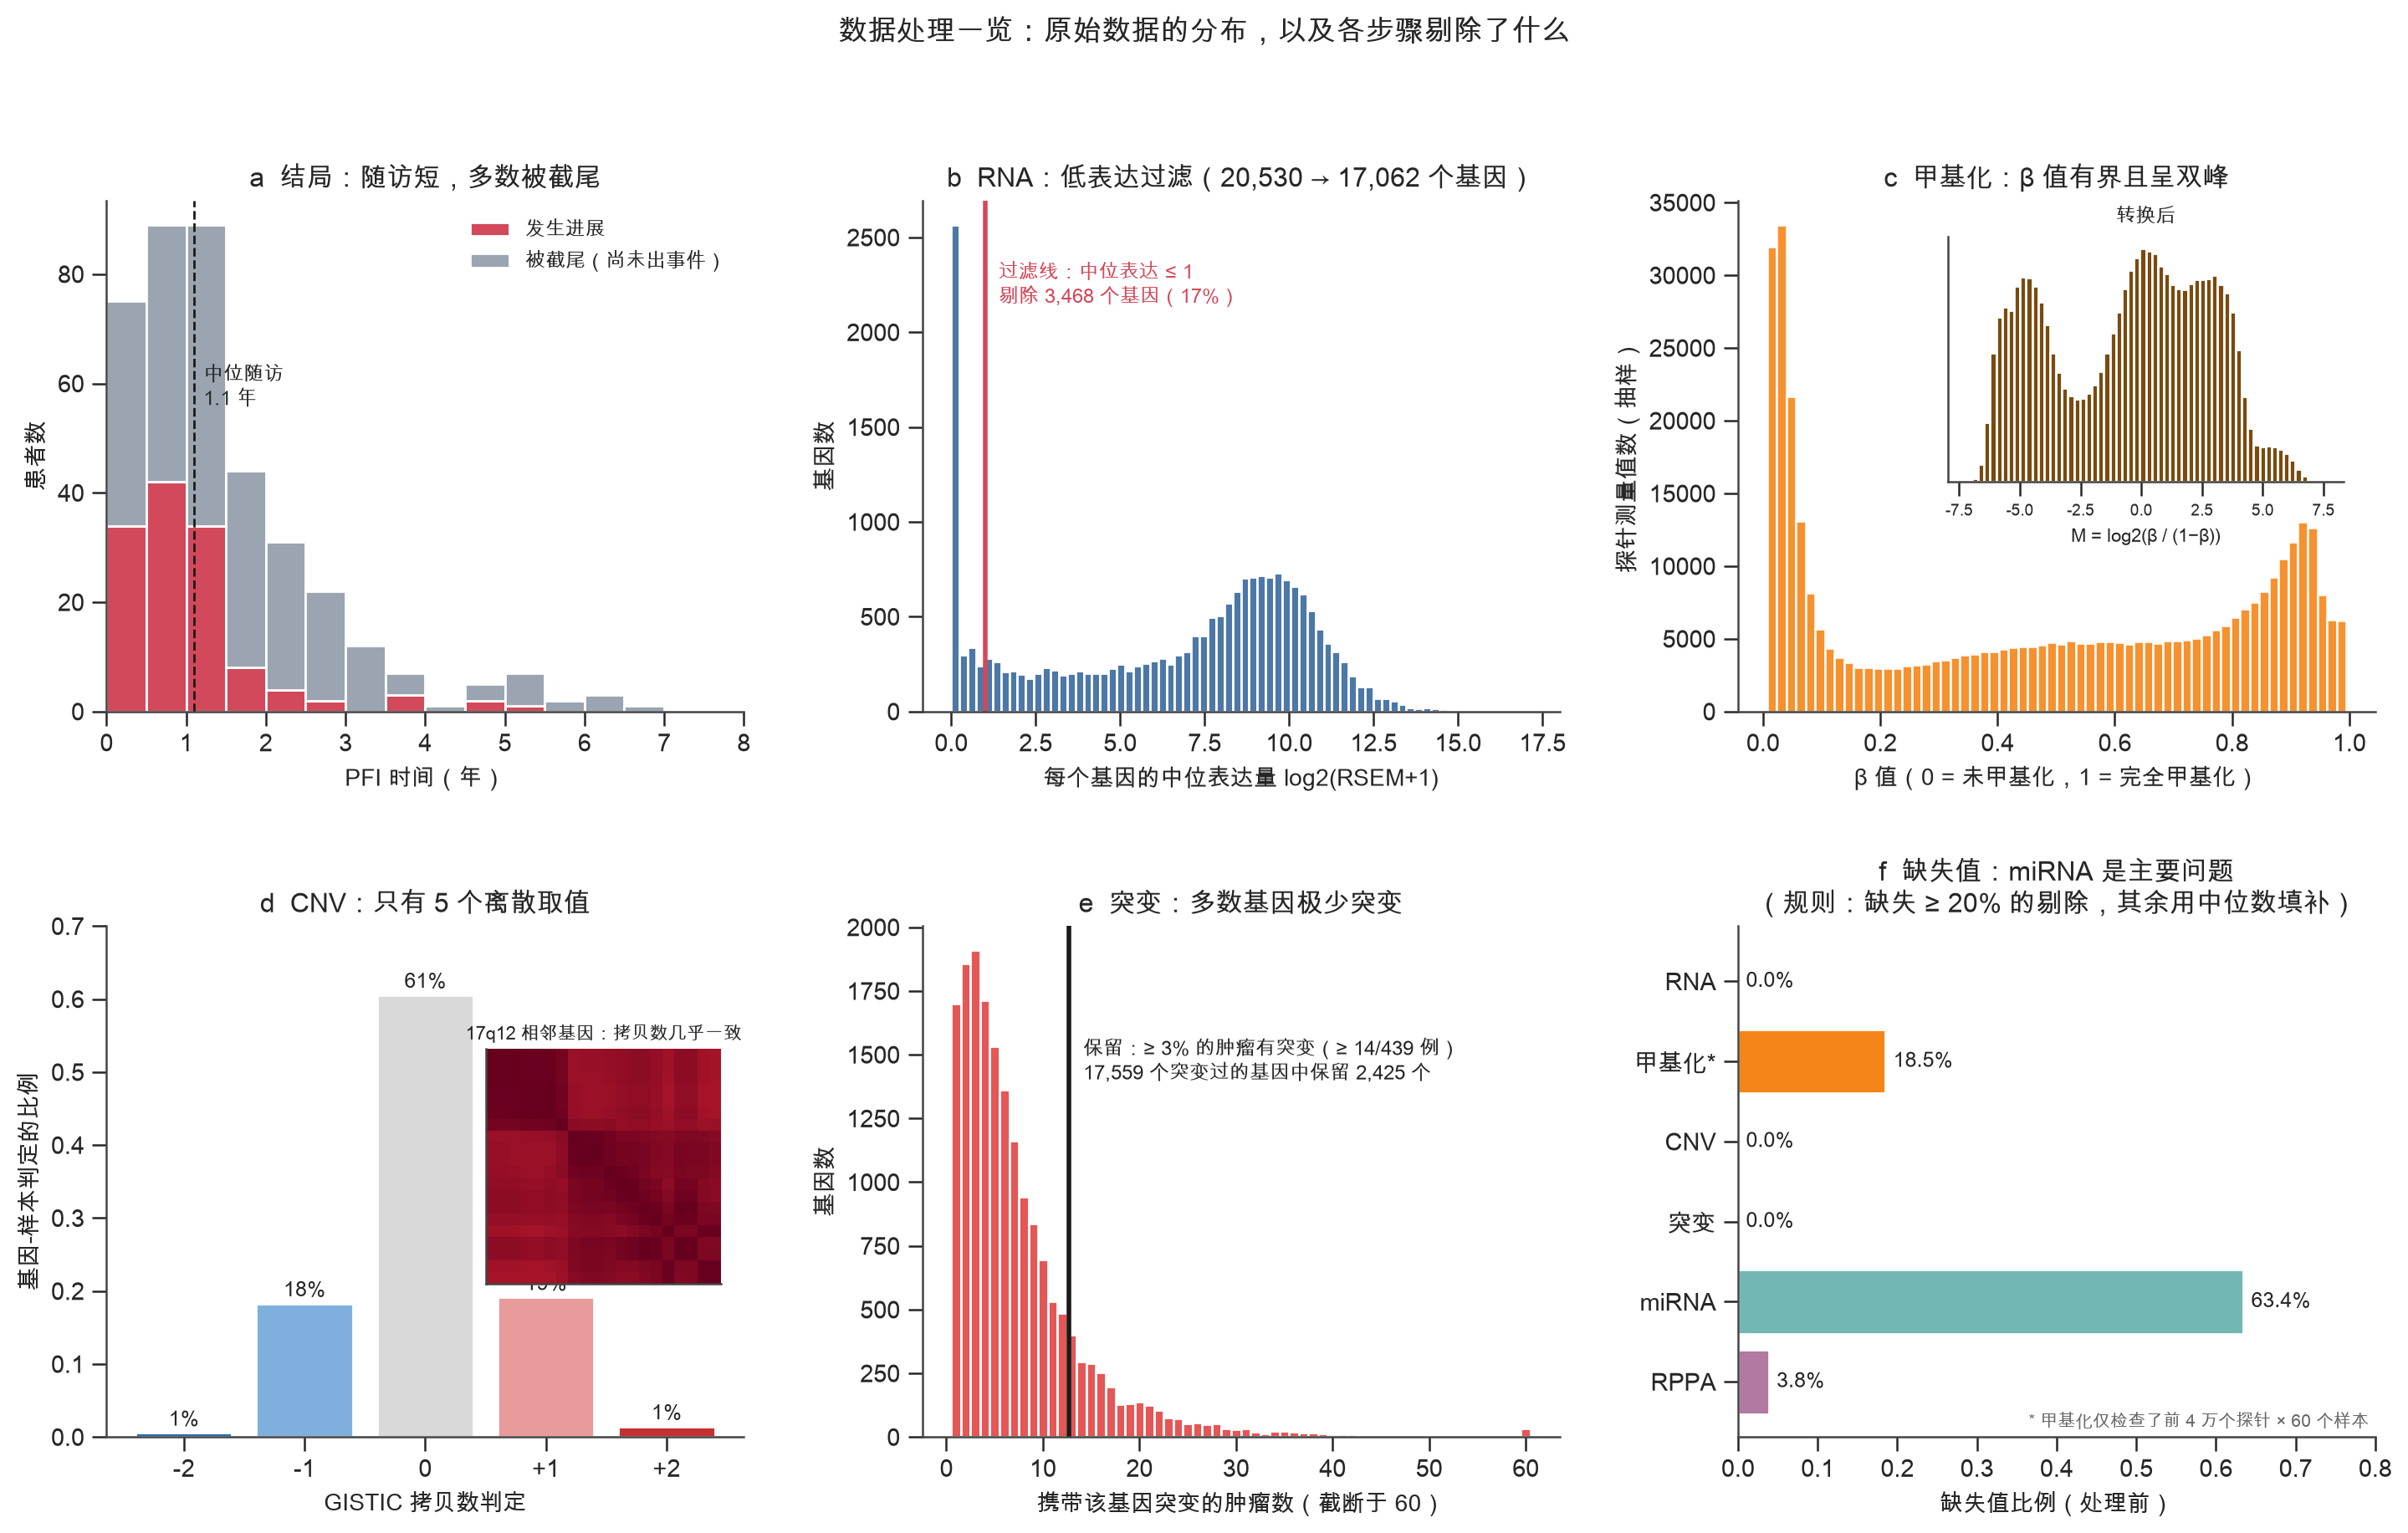

In [17]:
# ---------- 为作图读取少量原始数据（只读分布，不用于建模）----------
_raw_rna = pd.read_csv(DATA / "TCGA.STAD.sampleMap_HiSeqV2", sep="\t", index_col=0).astype(np.float32)
_raw_rna = _raw_rna.loc[:, [c for c in _raw_rna.columns if c in PRIMARY]]
_raw_cnv = pd.read_csv(DATA / "TCGA.STAD.sampleMap_Gistic2_CopyNumber_Gistic2_all_thresholded.by_genes", sep="\t", index_col=0)
_raw_cnv = _raw_cnv.loc[:, [c for c in _raw_cnv.columns if c in PRIMARY]]
_raw_mut = pd.read_csv(DATA / "mc3_gene_level_STAD_mc3_gene_level.txt", sep="\t", index_col=0)
_raw_mut = (_raw_mut.loc[:, [c for c in _raw_mut.columns if c in PRIMARY]] > 0)
_raw_mir = pd.read_csv(DATA / "TCGA.STAD.sampleMap_miRNA_HiSeq_gene", sep="\t", index_col=0)
_raw_mir = _raw_mir.loc[:, [c for c in _raw_mir.columns if c in PRIMARY]]
_raw_rp = pd.read_csv(DATA / "TCGA.STAD.sampleMap_RPPA", sep="\t", index_col=0)
_raw_rp = _raw_rp.loc[:, [c for c in _raw_rp.columns if c in PRIMARY]]
# 甲基化原始 β 值：只抽样 2 万个探针画分布（不读全表）
_rng = np.random.default_rng(SEED)
_mh = pd.read_csv(DATA / "TCGA.STAD.sampleMap_HumanMethylation450", sep="\t", nrows=0).columns
_use = [_mh[0]] + [c for c in _mh[1:] if c in PRIMARY][:60]
_meth_head = pd.read_csv(DATA / "TCGA.STAD.sampleMap_HumanMethylation450", sep="\t", usecols=_use, index_col=0, nrows=40000, dtype={c: np.float32 for c in _use[1:]})
_beta = _meth_head.values.ravel(); _beta = _beta[~np.isnan(_beta)]
_beta = _rng.choice(_beta, min(400000, len(_beta)), replace=False)
_Mval = np.log2(np.clip(_beta, 1e-3, 1 - 1e-3) / (1 - np.clip(_beta, 1e-3, 1 - 1e-3)))

fig = plt.figure(figsize=(17.5, 9.6))
gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.28)

# a. 结局：PFI 随访时间
ax = fig.add_subplot(gs[0, 0])
_d = SURVP.loc[has_pfi & ~is_m1]; _t = _d["PFI.time"] / 365.0
ax.hist([_t[_d.PFI == 1], _t[_d.PFI == 0]], bins=np.arange(0, 11.5, 0.5), stacked=True, color=["#D1495B", "#9AA5B1"], edgecolor="white", label=["发生进展", "被截尾（尚未出事件）"])
ax.axvline(np.median(_t), c="k", ls="--", lw=1); ax.text(np.median(_t) + 0.12, ax.get_ylim()[1] * 0.60, f"中位随访\n{np.median(_t):.1f} 年", fontsize=8.5)
ax.set(xlabel="PFI 时间（年）", ylabel="患者数", title="a  结局：随访短，多数被截尾"); ax.legend(fontsize=8.5, loc="upper right"); ax.set_xlim(0, 8)

# b. RNA：低表达过滤
ax = fig.add_subplot(gs[0, 1])
_med = _raw_rna.median(axis=1)             # 基因 × 样本：对每个基因取所有样本的中位数
ax.hist(_med, bins=70, color="#4C78A8", edgecolor="white")
ax.axvline(1.0, c="#D1495B", lw=2); ax.text(1.4, ax.get_ylim()[1] * 0.80, f"过滤线：中位表达 ≤ 1\n剔除 {(_med<=1).sum():,} 个基因（{(_med<=1).mean():.0%}）", color="#D1495B", fontsize=8.5)
ax.set(xlabel="每个基因的中位表达量 log2(RSEM+1)", ylabel="基因数", title=f"b  RNA：低表达过滤（{len(_med):,} → {int((_med>1).sum()):,} 个基因）")

# c. 甲基化：β → M
ax = fig.add_subplot(gs[0, 2])
ax.hist(_beta, bins=60, color="#F58518", edgecolor="white", alpha=0.9)
ax.set(xlabel="β 值（0 = 未甲基化，1 = 完全甲基化）", ylabel="探针测量值数（抽样）", title="c  甲基化：β 值有界且呈双峰")
axi = ax.inset_axes([0.33, 0.45, 0.62, 0.48]); axi.hist(_Mval, bins=60, color="#7A4A0E", edgecolor="white")
axi.set_xlabel("M = log2(β / (1−β))", fontsize=8); axi.set_title("转换后", fontsize=8.5); axi.tick_params(labelsize=7); axi.set_yticks([])

# d. CNV：取值构成 + 相邻基因相关
ax = fig.add_subplot(gs[1, 0])
_vc = pd.Series(_raw_cnv.values.ravel()).value_counts(normalize=True).sort_index()
ax.bar([str(int(i)) if i <= 0 else f"+{int(i)}" for i in _vc.index], _vc.values, color=["#2B6CB0", "#7FB0DD", "#D9D9D9", "#E99A9A", "#C53030"], edgecolor="white")
for i_, v_ in enumerate(_vc.values): ax.text(i_, v_ + 0.01, f"{v_:.0%}", ha="center", fontsize=9)
ax.set(xlabel="GISTIC 拷贝数判定", ylabel="基因-样本判定的比例", title="d  CNV：只有 5 个离散取值", ylim=(0, 0.7))
axi = ax.inset_axes([0.58, 0.30, 0.40, 0.46])
_blk = _raw_cnv.loc[[g for g in ["TCAP", "PNMT", "PGAP3", "ERBB2", "MIEN1", "GRB7", "IKZF3", "ZPBP2", "GSDMB", "ORMDL3", "LRRC3C", "GSDMA", "PSMD3", "CSF3", "THRA", "NR1D1", "MED24", "SNORD124", "CASC3", "RAPGEFL1"] if g in _raw_cnv.index]].T
_cc = np.corrcoef(_blk.values.T); axi.imshow(_cc, cmap="RdBu_r", vmin=-1, vmax=1); axi.set_xticks([]); axi.set_yticks([])
axi.set_title("17q12 相邻基因：拷贝数几乎一致", fontsize=8, pad=4)

# e. 突变：每个基因在多少个肿瘤里突变
ax = fig.add_subplot(gs[1, 1])
_cnt_m = _raw_mut.sum(axis=1); _cnt_m = _cnt_m[_cnt_m > 0]; _thr = 0.03 * _raw_mut.shape[1]
ax.hist(_cnt_m.clip(upper=60), bins=np.arange(0.5, 61.5, 1), color="#E45756", edgecolor="white")
ax.axvline(_thr - 0.5, c="k", lw=2); ax.text(_thr + 1, ax.get_ylim()[1] * 0.70, f"保留：≥ 3% 的肿瘤有突变（≥ {int(np.ceil(_thr))}/{_raw_mut.shape[1]} 例）\n{len(_cnt_m):,} 个突变过的基因中保留 {int((_cnt_m >= _thr).sum()):,} 个", fontsize=8.5)
ax.set(xlabel="携带该基因突变的肿瘤数（截断于 60）", ylabel="基因数", title="e  突变：多数基因极少突变")

# f. 缺失率
ax = fig.add_subplot(gs[1, 2])
_mi = {"RNA": 0.0, "Methylation*": float(_meth_head.isna().values.mean()), "CNV": 0.0, "Mutation": 0.0, "miRNA": float(_raw_mir.isna().values.mean()), "RPPA": float(_raw_rp.isna().values.mean())}
ax.barh([{"RNA": "RNA", "Methylation*": "甲基化*", "CNV": "CNV", "Mutation": "突变", "miRNA": "miRNA", "RPPA": "RPPA"}[m] for m in _mi], list(_mi.values()), color=[MOD_COLORS[m.rstrip("*")] for m in _mi], edgecolor="white")
for i_, (m_, v_) in enumerate(_mi.items()): ax.text(v_ + 0.01, i_, f"{v_:.1%}", va="center", fontsize=9)
ax.set_xlim(0, 0.8); ax.invert_yaxis()
ax.set(xlabel="缺失值比例（处理前）", title="f  缺失值：miRNA 是主要问题\n（规则：缺失 ≥ 20% 的剔除，其余用中位数填补）")
ax.text(0.99, 0.02, "* 甲基化仅检查了前 4 万个探针 × 60 个样本", transform=ax.transAxes, ha="right", fontsize=7.5, color="#666666")
fig.suptitle("数据处理一览：原始数据的分布，以及各步骤剔除了什么", fontsize=12.5, fontweight="bold", y=0.995)
savefig(fig, "B2_data_processing")
del _raw_rna, _raw_cnv, _raw_mut, _raw_mir, _raw_rp, _meth_head

## B3 患者漏斗与组学覆盖

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


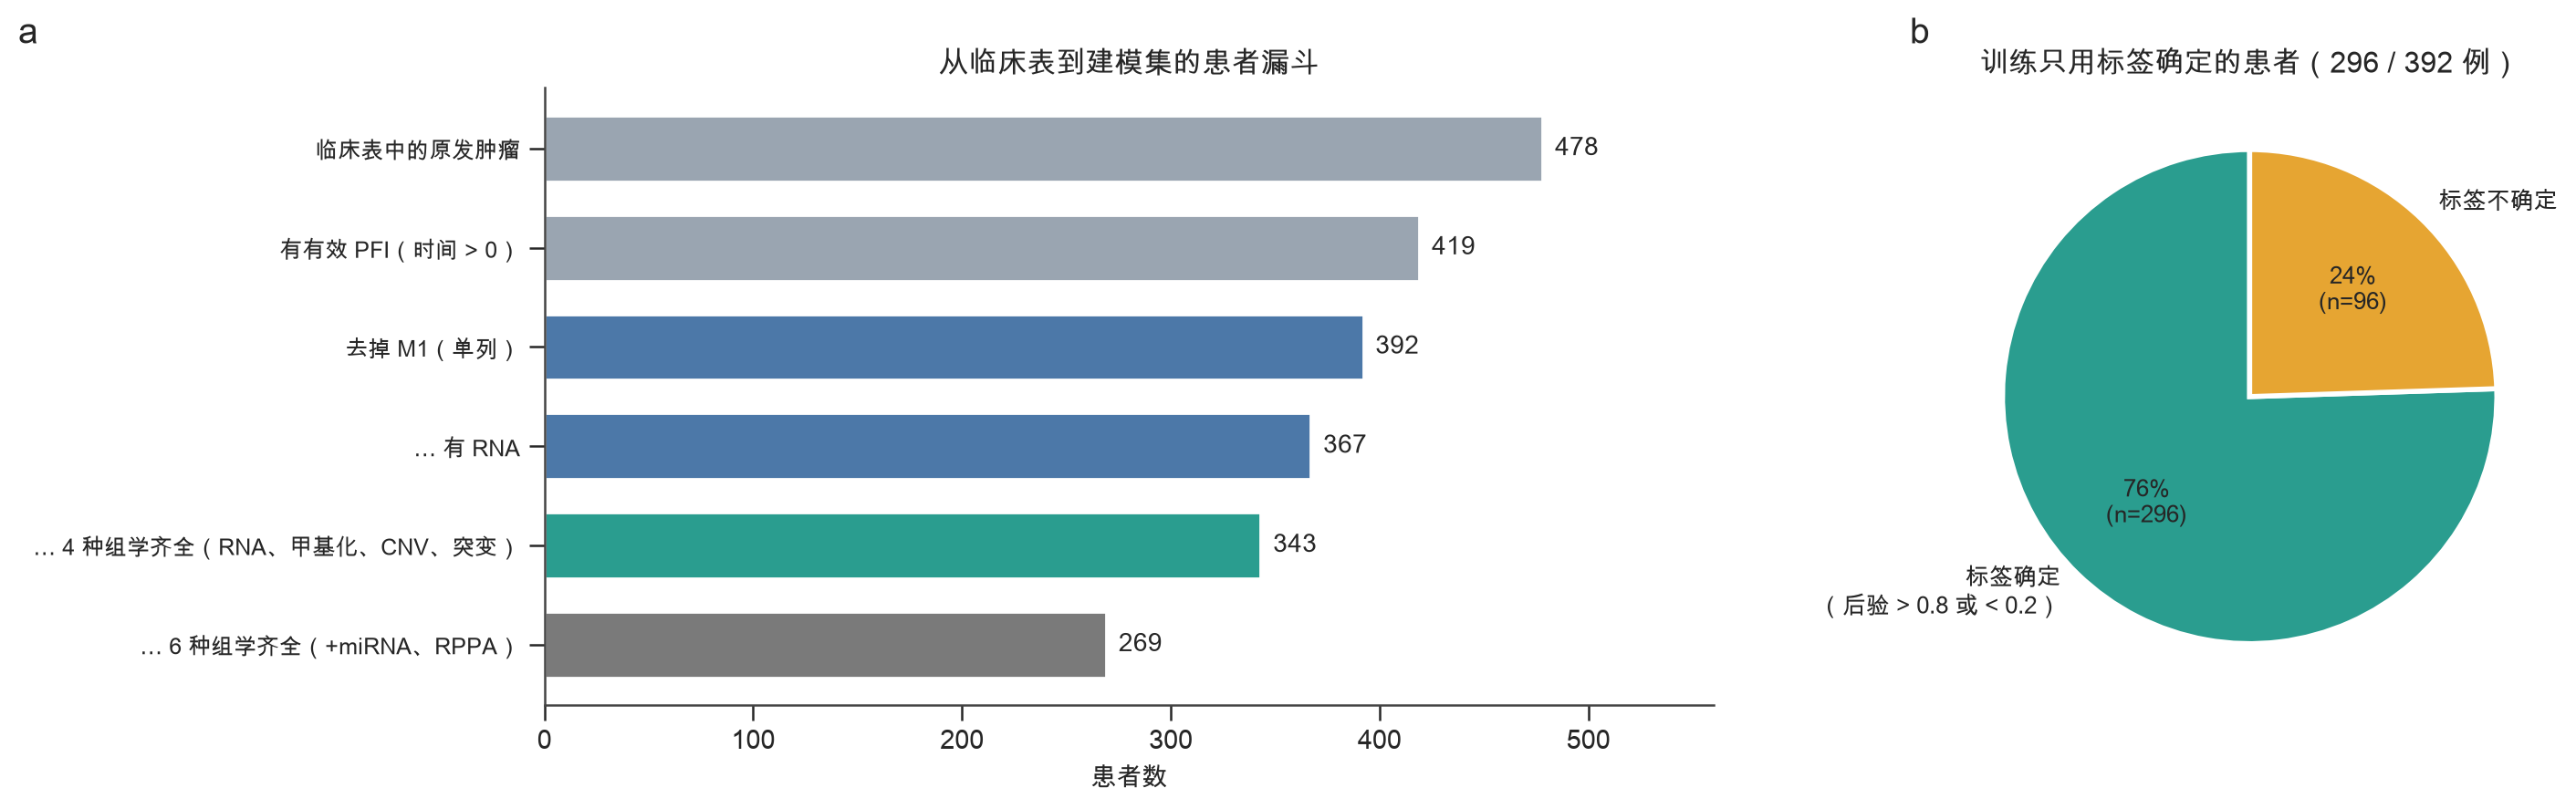

In [18]:
_steps = [("临床表中的原发肿瘤", int(len(clin))),
          ("有有效 PFI（时间 > 0）", int(has_pfi.sum())),
          ("去掉 M1（单列）", int((has_pfi & ~is_m1).sum())),
          ("… 有 RNA", int(sum(i in OM["RNA"].index for i in SUBTYPE.index))),
          ("… 4 种组学齐全（RNA、甲基化、CNV、突变）", len(ids_main)),
          ("… 6 种组学齐全（+miRNA、RPPA）", len(ids_all))]
_conf_n = int(CONF.loc[ids_main].sum())
fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.6), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = axes[0]
_cols = ["#9AA5B1", "#9AA5B1", "#4C78A8", "#4C78A8", "#2A9D8F", "#7A7A7A"]
ax.barh(range(len(_steps))[::-1], [s[1] for s in _steps], color=_cols, edgecolor="white", height=0.66)
for y_, (nm, v) in zip(range(len(_steps))[::-1], _steps): ax.text(v + 6, y_, f"{v}", va="center", fontweight="bold", fontsize=10)
ax.set_yticks(range(len(_steps))[::-1]); ax.set_yticklabels([s[0] for s in _steps], fontsize=9); ax.set_xlim(0, 560)
ax.set(xlabel="患者数", title="从临床表到建模集的患者漏斗"); panel_label(ax, "a", -0.45)
ax = axes[1]
_cnt = pd.Series({"标签确定\n（后验 > 0.8 或 < 0.2）": int(CONF.sum()), "标签不确定": int((~CONF).sum())})
ax.pie(_cnt.values, labels=_cnt.index, colors=["#2A9D8F", "#E6A532"], autopct=lambda p: f"{p:.0f}%\n(n={int(round(p*_cnt.sum()/100))})", startangle=90, wedgeprops=dict(edgecolor="white", linewidth=2), textprops=dict(fontsize=9.5))
ax.set_title(f"训练只用标签确定的患者（{int(CONF.sum())} / {len(CONF)} 例）"); panel_label(ax, "b", -0.05)
fig.tight_layout(); savefig(fig, "B3_patient_funnel")

---
# 阶段 C：用确诊时的信息预测分型（急型 / 惰型）

**任务**：输入一个病人确诊时就有的信息（临床 + 多组学），输出他属于"急型"的概率。

**训练只用标签确定的患者**（后验 > 0.8 或 < 0.2）；后验不确定的患者（多是随访不足的无事件者）不参与训练，但在测试折里照常给出预测，用于最后的风险分档。
所有有监督的特征筛选只在每个交叉验证的训练折内进行。

| 步骤 | 内容 | 回答的问题 |
|---|---|---|
| C1 | 各数据来源单独 / 组合的预测能力（消融） | 哪种数据有用 |
| C2 | 分类器与特征数 | 选什么模型 |
| C3 | 置换检验（只打乱组学行）、批次对照 | RNA 的增量是真的吗，是不是批次 |
| C4 | 风险分档：高 / 中 / 低 | 预测能转成可用的分层吗 |

## C1 各数据来源的预测能力

Clinical only                      n=392  AUC=0.614 ± 0.010


RNA                                n=367  AUC=0.660 ± 0.018


Methylation                        n=366  AUC=0.558 ± 0.025


CNV                                n=390  AUC=0.565 ± 0.025


Mutation                           n=389  AUC=0.498 ± 0.015


Methylation + CNV + Mutation       n=362  AUC=0.575 ± 0.020


/Users/foushen/bioinfo_report/.venv/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [223] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)


All 4 omics                        n=343  AUC=0.633 ± 0.024


Clinical + RNA                     n=367  AUC=0.675 ± 0.017


/Users/foushen/bioinfo_report/.venv/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [223] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)


Clinical + all 4 omics             n=343  AUC=0.656 ± 0.021


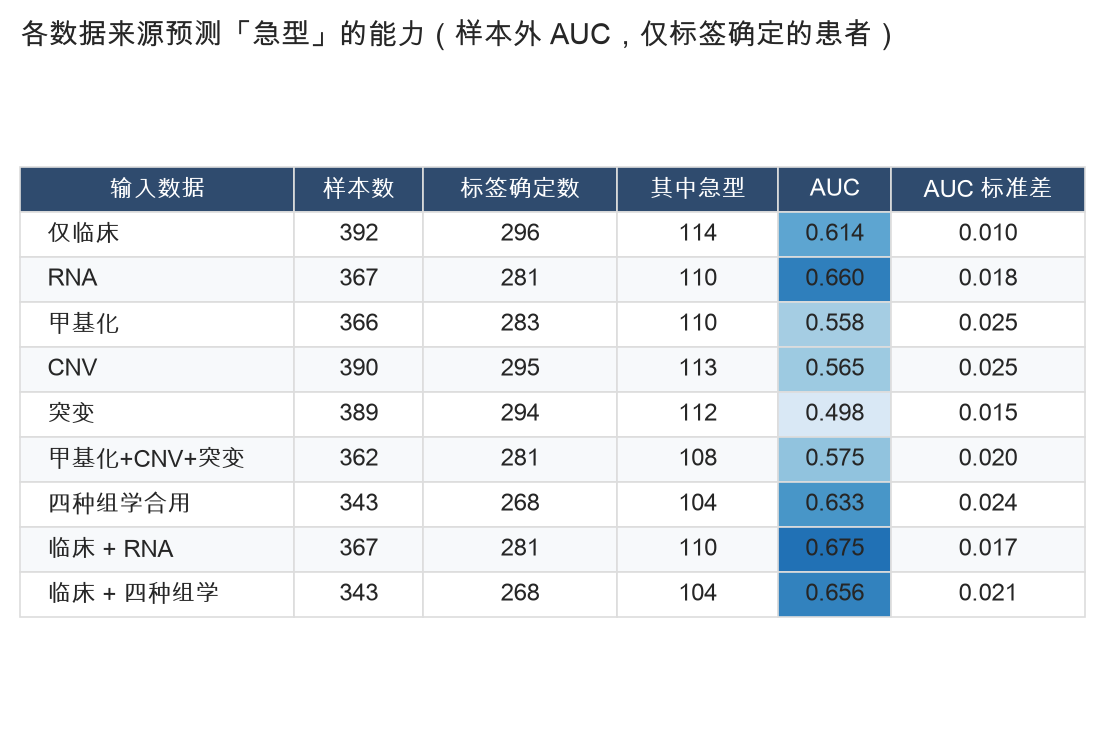

同一批患者(有 RNA，n=367)： {'Clinical only': '0.614', 'RNA': '0.661', 'Clinical + RNA': '0.678'}


In [19]:
from sklearn.model_selection import StratifiedKFold

CLIN_COLS = ["N", "T", "LNR", "Age"]
def clin_matrix(ids):
    c = CLIN.loc[ids].copy()
    for k in CLIN_COLS: c[k] = c[k].fillna(c[k].median())
    c["prox"] = c["Site"].isin(["Cardia", "GEJ"]).astype(float); c["ant"] = (c["Site"] == "Antrum").astype(float)
    return c[CLIN_COLS + ["prox", "ant"]].values.astype(float)

class BlockSelector(BaseEstimator, TransformerMixin):
    """分块特征筛选：Clin 块全部保留；每个组学块用训练折内 ANOVA-F 取前 kk 个；模块内 z-score。"""
    def __init__(self, blocks, kk=20): self.blocks, self.kk = blocks, kk
    def fit(self, X, y):
        self.sel_, self.mu_, self.sd_ = {}, {}, {}
        for m, cols in self.blocks.items():
            if m == "Clin": self.sel_[m] = np.asarray(cols)
            else:
                Fv, _ = f_classif(X[:, cols], y); Fv = np.nan_to_num(Fv); self.sel_[m] = np.asarray(cols)[np.argsort(-Fv)[:min(self.kk, len(cols))]]
            self.mu_[m] = X[:, self.sel_[m]].mean(0); self.sd_[m] = X[:, self.sel_[m]].std(0) + 1e-6
        return self
    def transform(self, X): return np.hstack([(X[:, self.sel_[m]] - self.mu_[m]) / self.sd_[m] for m in self.blocks])
    def selected_indices(self): return np.concatenate([self.sel_[m] for m in self.blocks])

def build_X(mods, ids, clin=False):
    mats, names, bl, pos = [], [], {}, 0
    if clin:
        a = clin_matrix(ids); mats.append(a); names += [f"Clin|{c}" for c in CLIN_COLS + ["prox", "ant"]]; bl["Clin"] = list(range(pos, pos + a.shape[1])); pos += a.shape[1]
    for m in mods:
        x = OM[m].reindex(ids); x = x.fillna(x.mean()).fillna(0)
        mats.append(x.values.astype(float)); names += [f"{m}|{c}" for c in x.columns]; bl[m] = list(range(pos, pos + x.shape[1])); pos += x.shape[1]
    return np.hstack(mats), np.array(names), bl

def make_model(name):
    return {"LR-L2": LogisticRegression(C=0.05, max_iter=3000, class_weight="balanced"),
            "LR-L2 (C=0.2)": LogisticRegression(C=0.2, max_iter=3000, class_weight="balanced"),
            "LR-L1": LogisticRegression(C=0.2, l1_ratio=1, solver="saga", max_iter=4000, class_weight="balanced"),
            "RandomForest": RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=1, random_state=SEED),
            "HistGradBoost": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.08, max_iter=120, l2_regularization=2.0, class_weight="balanced", random_state=SEED)}[name]

def cv_pred(X, y, conf, bl, model="LR-L2", kk=20, reps=5, seed0=0, return_sel=False):
    """5 折 × reps。训练折只用标签确定者；测试折预测全部患者。返回 确定者 AUC 的均值与标准差、全部患者的平均样本外概率。"""
    P = np.zeros((reps, len(y))); aucs = []; sels = []
    strat = np.where(conf, y, 2)
    for r in range(reps):
        skf = StratifiedKFold(5, shuffle=True, random_state=seed0 + r)
        def one(tr, te):
            trc = tr[conf[tr]]; sel = BlockSelector(bl, kk).fit(X[trc], y[trc]); m = make_model(model).fit(sel.transform(X[trc]), y[trc])
            return te, m.predict_proba(sel.transform(X[te]))[:, 1], sel.selected_indices()
        for te, p, si in Parallel(n_jobs=N_JOBS)(delayed(one)(tr, te) for tr, te in skf.split(X, strat)):
            P[r][te] = p; sels.append(si)
        aucs.append(roc_auc_score(y[conf], P[r][conf]))
    out = (np.mean(aucs), np.std(aucs), P.mean(0))
    return out + (sels,) if return_sel else out

# 预测对象：有 RNA 与确诊时临床信息的分型患者（为公平比较，各组合使用各自可得的患者，C1 末尾另给"同一批患者"的比较）
y_all = (post_fast > 0.5).astype(int)
conf_all = CONF.copy()
COMBOS = [("Clinical only", [], True), ("RNA", ["RNA"], False), ("Methylation", ["Methylation"], False), ("CNV", ["CNV"], False), ("Mutation", ["Mutation"], False),
          ("Methylation + CNV + Mutation", ["Methylation", "CNV", "Mutation"], False), ("All 4 omics", MODS_MAIN, False),
          ("Clinical + RNA", ["RNA"], True), ("Clinical + all 4 omics", MODS_MAIN, True)]
rows = []
for nm, mods, clin_ in COMBOS:
    ids_ = [i for i in idsP if all(i in OM[m].index for m in mods)]
    y_ = y_all.loc[ids_].values; c_ = conf_all.loc[ids_].values
    X_, f_, b_ = build_X(mods, ids_, clin_)
    a, sd, _ = cv_pred(X_, y_, c_, b_, "LR-L2", 20, reps=5)
    rows.append(dict(inputs=nm, n=len(ids_), n_confident=int(c_.sum()), n_fast=int(y_[c_].sum()), AUC=a, AUC_sd=sd)); print(f"{nm:34s} n={len(ids_)}  AUC={a:.3f} ± {sd:.3f}")
C1 = pd.DataFrame(rows).set_index("inputs")
ZH = {"Clinical only": "仅临床", "RNA": "RNA", "Methylation": "甲基化", "CNV": "CNV", "Mutation": "突变", "Methylation + CNV + Mutation": "甲基化+CNV+突变",
      "All 4 omics": "四种组学合用", "Clinical + RNA": "临床 + RNA", "Clinical + all 4 omics": "临床 + 四种组学",
      "Clinical + RNA (centre de-meaned)": "临床 + RNA（按中心去均值）", "Clinical + centre dummies": "临床 + 中心哑变量", "Clinical + shuffled RNA (60×, mean)": "临床 + 乱序 RNA（60 次均值）"}
show_table(C1.rename(index=ZH).rename(columns={"n": "样本数", "n_confident": "标签确定数", "n_fast": "其中急型", "AUC": "AUC", "AUC_sd": "AUC 标准差"}).rename_axis("输入数据"),
           "T_C1_data_sources", "各数据来源预测「急型」的能力（样本外 AUC，仅标签确定的患者）", fmt={"样本数": "{:.0f}", "标签确定数": "{:.0f}", "其中急型": "{:.0f}", "AUC": "{:.3f}", "AUC 标准差": "{:.3f}"}, hl=["AUC"])

# 同一批患者(有 RNA)上直接比较 临床 / RNA / 临床+RNA / 全部
ids_rna = [i for i in idsP if i in OM["RNA"].index]
y_r = y_all.loc[ids_rna].values; c_r = conf_all.loc[ids_rna].values
C1b = {}
for nm, mods, clin_ in [("Clinical only", [], True), ("RNA", ["RNA"], False), ("Clinical + RNA", ["RNA"], True)]:
    X_, f_, b_ = build_X(mods, ids_rna, clin_); a, sd, p_ = cv_pred(X_, y_r, c_r, b_, "LR-L2", 20, reps=10); C1b[nm] = (a, sd, p_)
print("同一批患者(有 RNA，n=%d)：" % len(ids_rna), {k: f"{v[0]:.3f}" for k, v in C1b.items()})

## C2 分类器与特征数
在"临床 + RNA"上比较四种分类器与每模态保留的特征数（5 折 × 3 重复）。**这些选择是在同一批数据上做的，会带来轻微乐观偏差**，真实性能应略低于下面选定配置的数字。

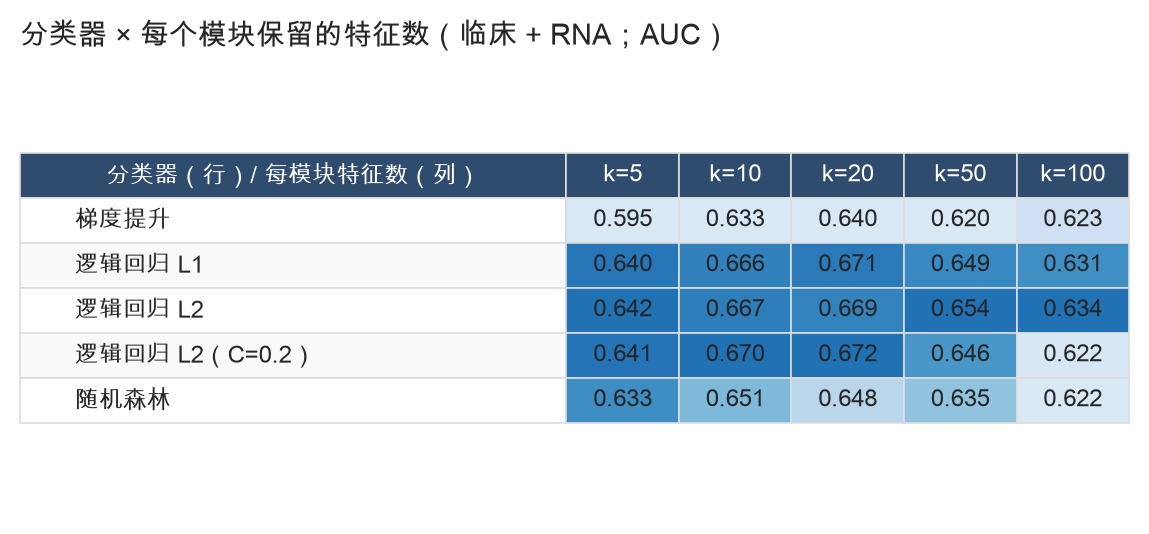

选定：LR-L2 (C=0.2)，每模态 20 个特征（C2 最优）


In [20]:
Xr, fr, br = build_X(["RNA"], ids_rna, True)
rows = []
for mdl in ["LR-L2", "LR-L2 (C=0.2)", "LR-L1", "RandomForest", "HistGradBoost"]:
    for kk in [5, 10, 20, 50, 100]:
        a, sd, _ = cv_pred(Xr, y_r, c_r, br, mdl, kk, reps=3); rows.append(dict(model=mdl, k_per_module=kk, AUC=a))
C2 = pd.DataFrame(rows).pivot(index="model", columns="k_per_module", values="AUC")
C2t = C2.copy(); C2t.columns = [f"k={c}" for c in C2t.columns]
show_table(C2t.rename(index={"LR-L2": "逻辑回归 L2", "LR-L2 (C=0.2)": "逻辑回归 L2（C=0.2）", "LR-L1": "逻辑回归 L1", "RandomForest": "随机森林", "HistGradBoost": "梯度提升"}).rename_axis("分类器（行）/ 每模块特征数（列）"), "T_C2_model_by_features", "分类器 × 每个模块保留的特征数（临床 + RNA；AUC）", fmt={c: "{:.3f}" for c in C2t.columns}, hl=list(C2t.columns))
_bm = C2.stack().idxmax(); MODEL_SEL, KK_SEL = _bm
print(f"选定：{MODEL_SEL}，每模态 {KK_SEL} 个特征（C2 最优）")

## C3 增量是真的吗：置换检验与批次对照

- **置换**：只把 RNA 的行随机打乱（临床变量和标签保持对应），其余流程完全不变，重复 60 次，看"临床 + 乱序 RNA"能达到多高。
- **批次**：把每个 RNA 特征减去其所在录入中心的均值（不使用标签），再重做；并看"临床 + 中心哑变量"能否替代 RNA。

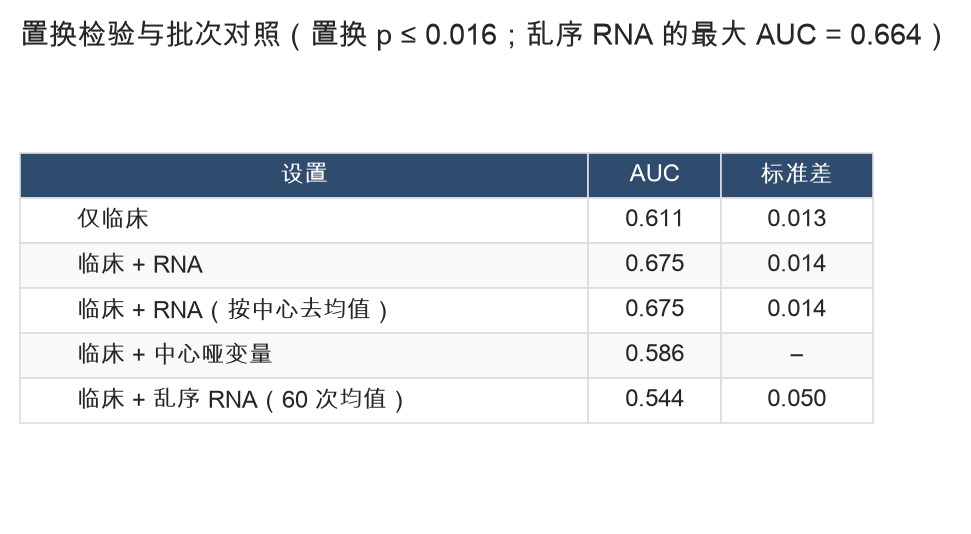

,AUC,标准差
设置,,
仅临床,0.611055,0.012772
临床 + RNA,0.675481,0.014151
临床 + RNA（按中心去均值）,0.675029,0.013887
临床 + 中心哑变量,0.585720,NaN
临床 + 乱序 RNA（60 次均值）,0.544160,0.049705


In [21]:
a_c, sd_c, P_c = cv_pred(*[build_X([], ids_rna, True)[0], y_r, c_r, build_X([], ids_rna, True)[2]], MODEL_SEL, KK_SEL, reps=10)
a_r, sd_r, P_r = cv_pred(Xr, y_r, c_r, br, MODEL_SEL, KK_SEL, reps=10)
nc_ = len(br["Clin"])
rng = np.random.default_rng(SEED); null = []
for i in range(60):
    p = rng.permutation(len(y_r)); Xp = Xr.copy(); Xp[:, nc_:] = Xr[p][:, nc_:]
    null.append(cv_pred(Xp, y_r, c_r, br, MODEL_SEL, KK_SEL, reps=1, seed0=i)[0])
null = np.array(null); p_perm = (np.sum(null >= a_r) + 1) / (len(null) + 1)

tss_ = pd.Series([i.split("-")[1] for i in ids_rna], index=ids_rna); _big = tss_.value_counts(); tss_ = tss_.where(tss_.map(_big) >= 10, "other").values
Xd = Xr.copy()
for g in np.unique(tss_):
    m_ = tss_ == g; Xd[np.ix_(m_, np.arange(nc_, Xr.shape[1]))] = Xr[np.ix_(m_, np.arange(nc_, Xr.shape[1]))] - Xr[np.ix_(m_, np.arange(nc_, Xr.shape[1]))].mean(0, keepdims=True)
a_dm, sd_dm, _ = cv_pred(Xd, y_r, c_r, br, MODEL_SEL, KK_SEL, reps=10)
Xcent = np.hstack([build_X([], ids_rna, True)[0], pd.get_dummies(pd.Series(tss_)).values.astype(float)])
a_ct, _, _ = cv_pred(Xcent, y_r, c_r, {"Clin": list(range(Xcent.shape[1]))}, MODEL_SEL, KK_SEL, reps=5)
C3 = pd.DataFrame({"AUC": [a_c, a_r, a_dm, a_ct, null.mean()], "sd": [sd_c, sd_r, sd_dm, np.nan, null.std()]},
                  index=["Clinical only", "Clinical + RNA", "Clinical + RNA (centre de-meaned)", "Clinical + centre dummies", "Clinical + shuffled RNA (60×, mean)"])
show_table(C3.rename(index=ZH).rename(columns={"sd": "标准差"}).rename_axis("设置"), "T_C3_permutation_batch", f"置换检验与批次对照（置换 p ≤ {p_perm:.3f}；乱序 RNA 的最大 AUC = {null.max():.3f}）", fmt={"AUC": "{:.3f}", "标准差": "{:.3f}"}, wrap=30)

## C4 风险分档：高 / 中 / 低
对**全部分型患者**（含后验不确定者）用样本外预测概率按三分位分档，再看他们实际的无进展与总生存。

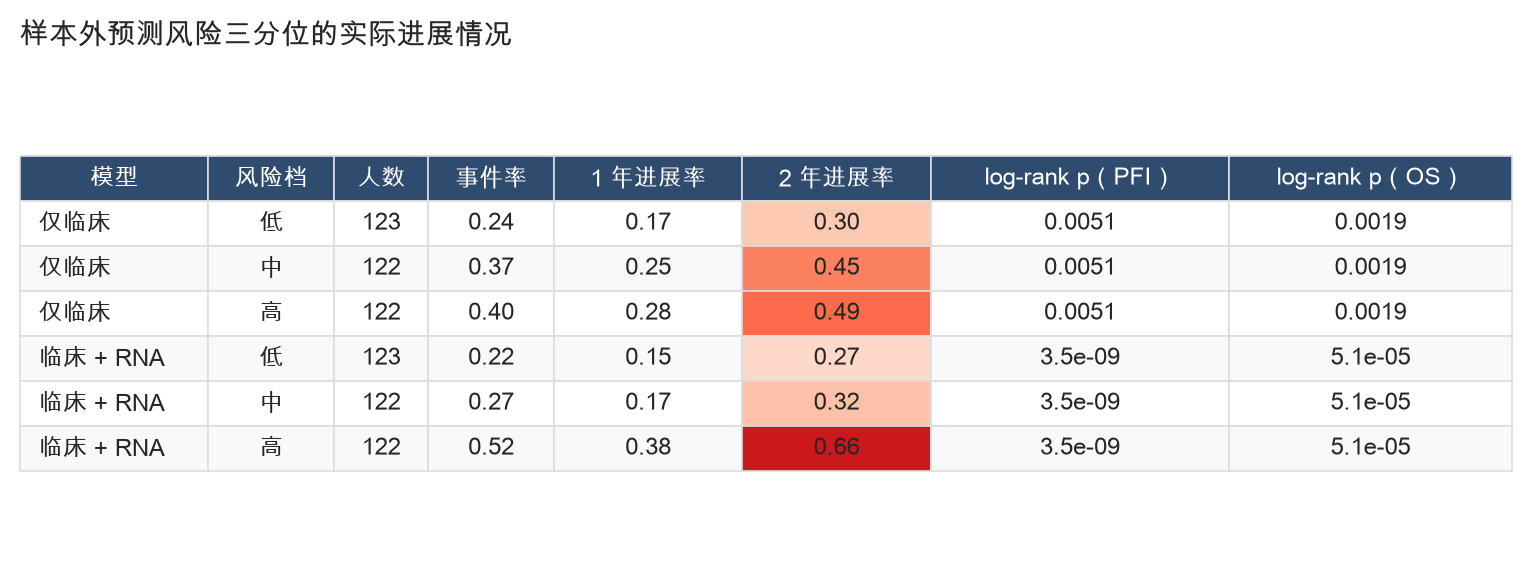

高风险档 vs 其余（临床+RNA）：PFI HR = 2.93 (2.05–4.18)，p = 2.9e-09


In [22]:
dfR = pd.DataFrame({"t": tP[[list(idsP).index(i) for i in ids_rna]] * 12, "e": eP[[list(idsP).index(i) for i in ids_rna]]}, index=ids_rna)
dfR["p_clin"], dfR["p_rna"] = P_c, P_r
dfR["OS_t"] = SURVP.loc[ids_rna, "OS.time"].values / 30.4375; dfR["OS_e"] = SURVP.loc[ids_rna, "OS"].values
GR = ["Low", "Mid", "High"]
for col, nm in [("p_clin", "gr_clin"), ("p_rna", "gr_rna")]:
    dfR[nm] = pd.qcut(dfR[col].rank(method="first"), 3, labels=GR)
rows = []
for nm, gc in [("Clinical only", "gr_clin"), ("Clinical + RNA", "gr_rna")]:
    pp = multivariate_logrank_test(dfR.t, dfR[gc], dfR.e).p_value
    d_ = dfR.dropna(subset=["OS_t", "OS_e"]); d_ = d_[d_.OS_t > 0]; po = multivariate_logrank_test(d_.OS_t, d_[gc].loc[d_.index], d_.OS_e).p_value
    for g in GR:
        s_ = dfR[dfR[gc] == g]; k_ = KaplanMeierFitter().fit(s_.t, s_.e)
        rows.append(dict(model=nm, group=g, n=len(s_), event_rate=s_.e.mean(), PFI_1y=1 - float(k_.predict(12)), PFI_2y=1 - float(k_.predict(24)), logrank_PFI=pp, logrank_OS=po))
C4 = pd.DataFrame(rows).set_index(["model", "group"])
C4_show = C4.rename(index={"Clinical only": "仅临床", "Clinical + RNA": "临床 + RNA", "Low": "低", "Mid": "中", "High": "高"}).rename(columns={"n": "人数", "event_rate": "事件率", "PFI_1y": "1 年进展率", "PFI_2y": "2 年进展率", "logrank_PFI": "log-rank p（PFI）", "logrank_OS": "log-rank p（OS）"}).rename_axis(["模型", "风险档"])
show_table(C4_show, "T_C4_risk_groups", "样本外预测风险三分位的实际进展情况", fmt={"人数": "{:.0f}", "事件率": "{:.2f}", "1 年进展率": "{:.2f}", "2 年进展率": "{:.2f}", "log-rank p（PFI）": "{:.2g}", "log-rank p（OS）": "{:.2g}"}, hl=["2 年进展率"], cmap="Reds")
HI_VS_REST = dfR.assign(hi=(dfR.gr_rna == "High").astype(int))
_c = HI_VS_REST[["t", "e", "hi"]].rename(columns={"t": "T_", "e": "E_"})
hr_hi = CoxPHFitter().fit(_c, "T_", "E_").summary.loc["hi", ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
print(f"高风险档 vs 其余（临床+RNA）：PFI HR = {hr_hi.iloc[0]:.2f} ({hr_hi.iloc[1]:.2f}–{hr_hi.iloc[2]:.2f})，p = {hr_hi.iloc[3]:.2g}")

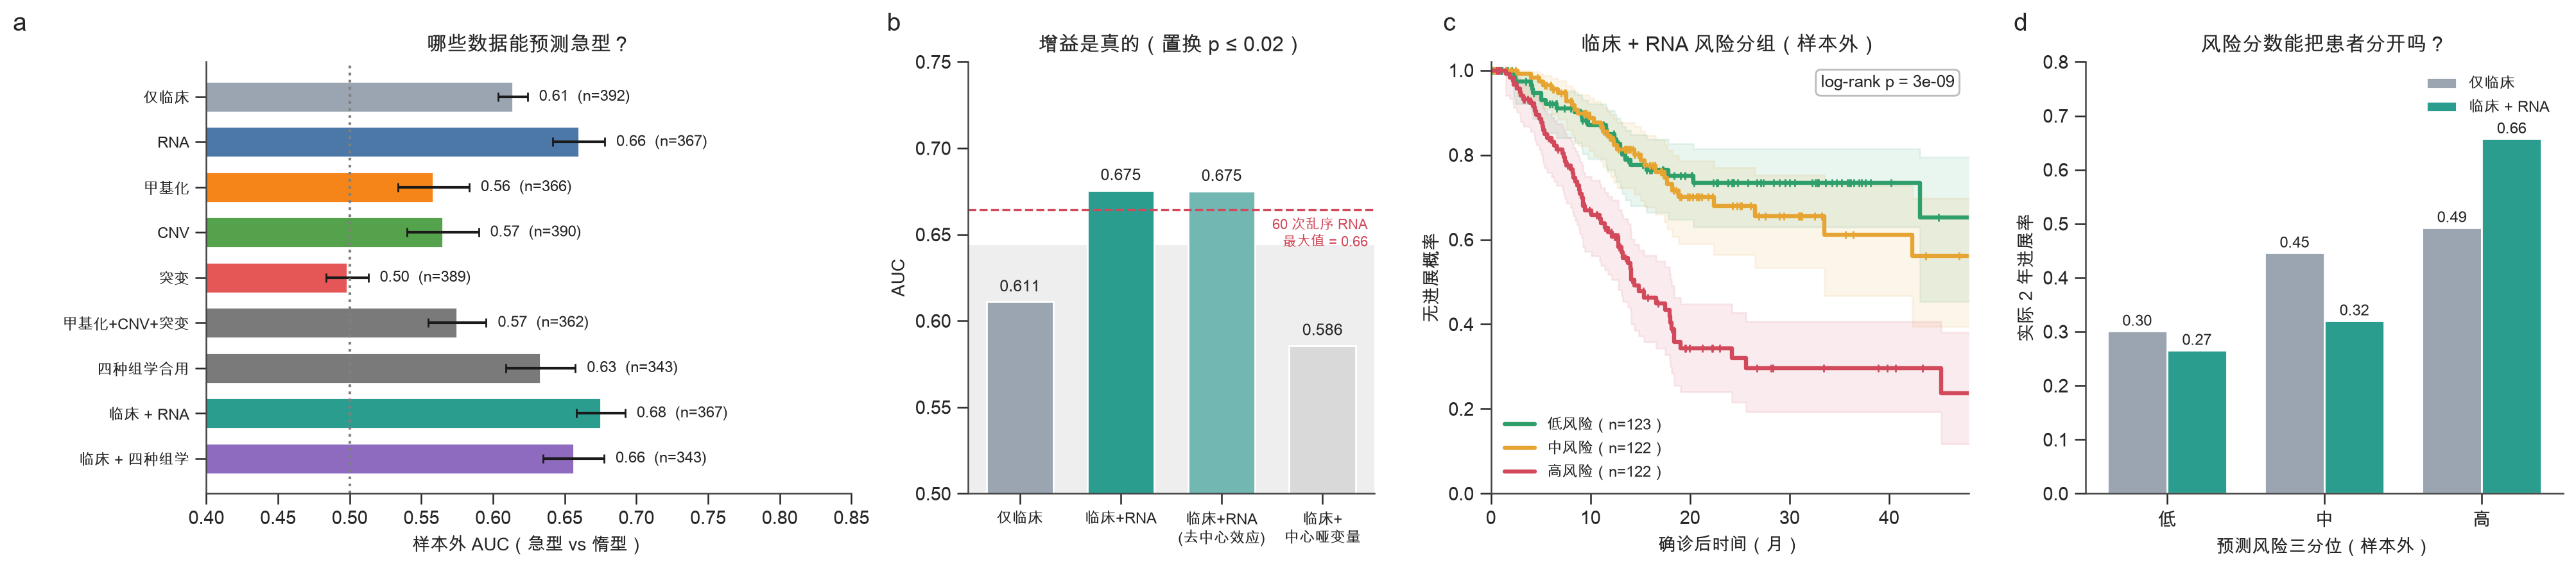

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), gridspec_kw=dict(width_ratios=[1.35, 0.85, 1, 1]))
ax = axes[0]
order_ = ["Clinical only", "RNA", "Methylation", "CNV", "Mutation", "Methylation + CNV + Mutation", "All 4 omics", "Clinical + RNA", "Clinical + all 4 omics"]
cl_ = {"Clinical only": "#9AA5B1", "RNA": MOD_COLORS["RNA"], "Methylation": MOD_COLORS["Methylation"], "CNV": MOD_COLORS["CNV"], "Mutation": MOD_COLORS["Mutation"],
       "Methylation + CNV + Mutation": "#7A7A7A", "All 4 omics": "#7A7A7A", "Clinical + RNA": "#2A9D8F", "Clinical + all 4 omics": "#8E6BBF"}
ax.barh(range(len(order_))[::-1], C1.loc[order_, "AUC"], xerr=C1.loc[order_, "AUC_sd"], color=[cl_[o] for o in order_], height=0.68, edgecolor="white", capsize=2.5)
for y_i, o in zip(range(len(order_))[::-1], order_): ax.text(C1.loc[o, "AUC"] + C1.loc[o, "AUC_sd"] + 0.008, y_i, f"{C1.loc[o,'AUC']:.2f}  (n={int(C1.loc[o,'n'])})", va="center", fontsize=8.5)
ax.axvline(0.5, ls=":", c="grey"); ax.set_yticks(range(len(order_))[::-1]); ax.set_yticklabels([ZH[o] for o in order_], fontsize=8.5); ax.set_xlim(0.4, 0.85)
ax.set(xlabel="样本外 AUC（急型 vs 惰型）", title="哪些数据能预测急型？"); panel_label(ax, "a", -0.3)
ax = axes[1]
vals_ = [a_c, a_r, a_dm, a_ct]; labs_ = ["仅临床", "临床+RNA", "临床+RNA\n(去中心效应)", "临床+\n中心哑变量"]
ax.bar(range(4), vals_, color=["#9AA5B1", "#2A9D8F", "#72B7B2", "#D9D9D9"], edgecolor="white", width=0.66)
ax.axhspan(null.mean() - 2 * null.std(), null.mean() + 2 * null.std(), color="#EEEEEE", zorder=0); ax.axhline(null.max(), ls="--", c="#D1495B", lw=1.2)
ax.text(3.45, null.max() - 0.004, f"60 次乱序 RNA\n最大值 = {null.max():.2f}", color="#D1495B", ha="right", fontsize=8, va="top")
for i_, v_ in enumerate(vals_): ax.text(i_, v_ + 0.006, f"{v_:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(4)); ax.set_xticklabels(labs_, fontsize=8.5); ax.set_ylim(0.5, 0.75); ax.set(ylabel="AUC", title=f"增益是真的（置换 p ≤ {p_perm:.2f}）"); panel_label(ax, "b", -0.2)
ax = axes[2]
gcol = {"Low": "#2E9E6B", "Mid": "#E6A532", "High": "#D1495B"}
for g in GR:
    s_ = dfR[dfR.gr_rna == g]; KaplanMeierFitter().fit(s_.t, s_.e, label=f"{ {'Low': '低风险', 'Mid': '中风险', 'High': '高风险'}[g] }（n={len(s_)}）").plot_survival_function(ax=ax, color=gcol[g], lw=2.3, ci_alpha=0.1, show_censors=True, censor_styles=dict(ms=4, marker="|", mew=1))
ax.set(xlim=(0, 48), ylim=(0, 1.02), xlabel="确诊后时间（月）", ylabel="无进展概率", title="临床 + RNA 风险分组（样本外）")
ax.text(0.97, 0.97, f"log-rank p = {C4.loc[('Clinical + RNA','High'),'logrank_PFI']:.1g}", transform=ax.transAxes, ha="right", va="top", fontsize=9.5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#BBB")); ax.legend(loc="lower left", fontsize=8.5); panel_label(ax, "c", -0.1)
ax = axes[3]
xx_ = np.arange(3); w_ = 0.38
v1 = [C4.loc[("Clinical only", g), "PFI_2y"] for g in GR]; v2 = [C4.loc[("Clinical + RNA", g), "PFI_2y"] for g in GR]
ax.bar(xx_ - w_ / 2, v1, w_, color="#9AA5B1", label="仅临床"); ax.bar(xx_ + w_ / 2, v2, w_, color="#2A9D8F", label="临床 + RNA")
for i_, (a1, a2) in enumerate(zip(v1, v2)): ax.text(i_ - w_ / 2, a1 + 0.01, f"{a1:.2f}", ha="center", fontsize=8.5); ax.text(i_ + w_ / 2, a2 + 0.01, f"{a2:.2f}", ha="center", fontsize=8.5, fontweight="bold")
ax.set_xticks(xx_); ax.set_xticklabels(["低", "中", "高"]); ax.set_ylim(0, 0.8); ax.set(xlabel="预测风险三分位（样本外）", ylabel="实际 2 年进展率", title="风险分数能把患者分开吗？"); ax.legend(fontsize=8.5); panel_label(ax, "d", -0.15)
fig.tight_layout(); savefig(fig, "C1_prediction")

## C5 模型评测曲线：ROC、PR、校准、时间依赖 ROC、决策曲线

前面用 AUC 一个数字比较了各输入；这里把"临床 + RNA"模型的评测完整画出来，并和"仅临床""仅 RNA"并排比较。所有曲线都用**样本外预测**（每个患者的分数来自没有见过他的模型，10 次重复平均）。

| 面板 | 指标 | 回答的问题 | 用哪些患者 |
|---|---|---|---|
| a ROC | AUC + 自举 95% 区间 | 区分急型与惰型的能力 | 标签确定者 |
| b PR | 平均精确率 AP | 在类别不平衡下的查准 / 查全 | 标签确定者 |
| c 校准 | 预测概率 vs 实际比例、Brier | 概率数值可不可信 | 标签确定者 |
| d 时间依赖 ROC | 2 年进展的 AUC | **不依赖混合模型标签**，直接对实际进展评估 | 全部患者（含标签不确定者） |
| e 决策曲线 | 净获益 | 按这个模型决定"是否加强干预"是否优于全治 / 全不治 | 标签确定者 |
| f 得分分布 | 两类得分的重叠程度 | 直观看分得开不开 | 标签确定者 |

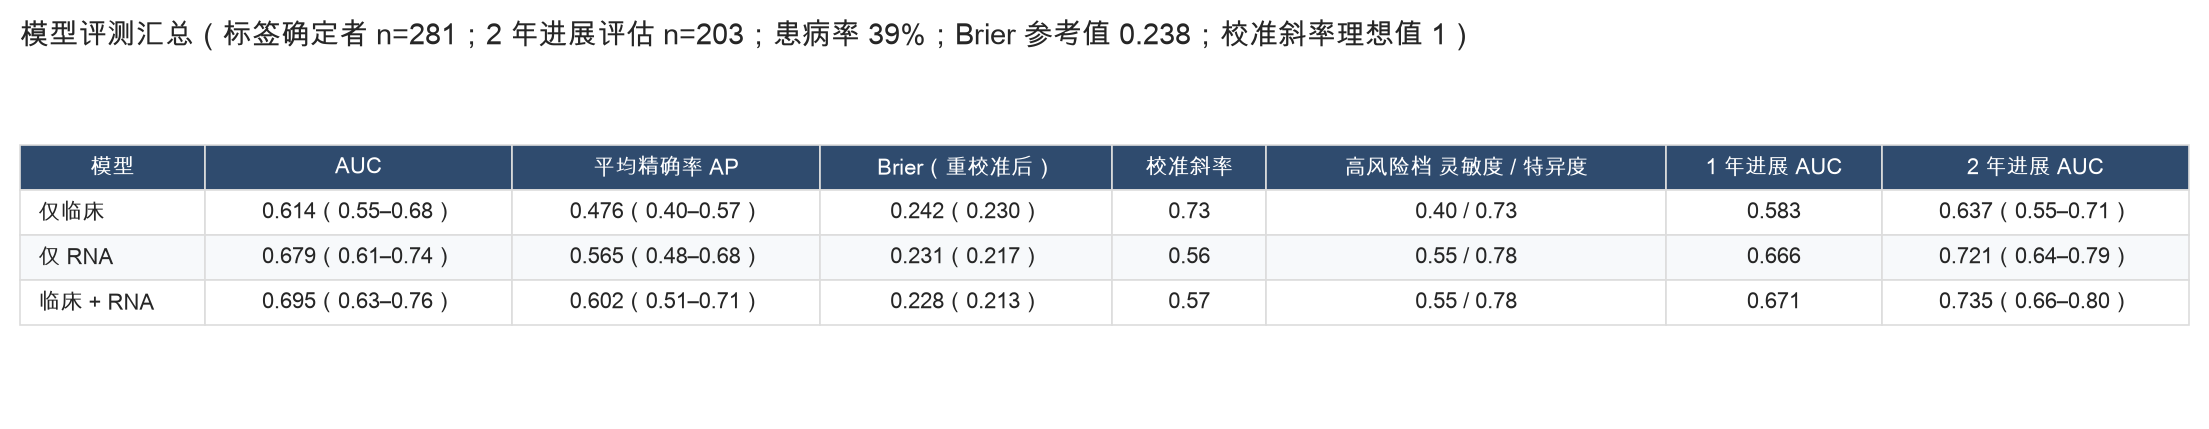

临床+RNA 相对仅临床：标签 AUC 差 +0.082（95% 区间 +0.012 到 +0.152，自举 p=0.022）；2 年进展 AUC 差 +0.098（+0.019 到 +0.176，p=0.018）


In [24]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, brier_score_loss

Xo_, fo_, bo_ = build_X(["RNA"], ids_rna, False)
_, _, P_rna = cv_pred(Xo_, y_r, c_r, bo_, MODEL_SEL, KK_SEL, reps=10)
SC = {"仅临床": P_c, "仅 RNA": P_rna, "临床 + RNA": P_r}
COLM = {"仅临床": "#9AA5B1", "仅 RNA": MOD_COLORS["RNA"], "临床 + RNA": "#2A9D8F"}
yc = y_r[c_r]; prev = yc.mean()
SCc = {k: v[c_r] for k, v in SC.items()}

# ---- 标签依赖的指标：自举 95% 区间 ----
rng = np.random.default_rng(SEED); B = 1000; n_c = len(yc)
boot_auc = {k: [] for k in SC}; boot_ap = {k: [] for k in SC}
for _ in range(B):
    ii = rng.integers(0, n_c, n_c)
    if yc[ii].min() == yc[ii].max(): continue
    for k, v in SCc.items(): boot_auc[k].append(roc_auc_score(yc[ii], v[ii])); boot_ap[k].append(average_precision_score(yc[ii], v[ii]))
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
d_auc = np.array(boot_auc["临床 + RNA"]) - np.array(boot_auc["仅临床"]); p_dauc = min(1.0, 2 * min((d_auc <= 0).mean(), (d_auc >= 0).mean()))

# ---- 时间依赖：2 年 / 1 年进展（不依赖混合模型标签）----
t_m = dfR.t.values; e_m = dfR.e.values
def td_set(Tm):
    case = (e_m == 1) & (t_m <= Tm); ctrl = t_m > Tm; keep = case | ctrl
    return keep, case.astype(int)
TD = {}
for Tm in (12, 24):
    keep, yy = td_set(Tm); TD[Tm] = (keep, yy[keep])
def td_boot(Tm):
    keep, yy = TD[Tm]; n_ = len(yy); out = {k: [] for k in SC}
    r_ = np.random.default_rng(SEED + Tm)
    for _ in range(B):
        ii = r_.integers(0, n_, n_)
        if yy[ii].min() == yy[ii].max(): continue
        for k, v in SC.items(): out[k].append(roc_auc_score(yy[ii], v[keep][ii]))
    return out
TDB = {Tm: td_boot(Tm) for Tm in (12, 24)}
d_td = np.array(TDB[24]["临床 + RNA"]) - np.array(TDB[24]["仅临床"]); p_dtd = min(1.0, 2 * min((d_td <= 0).mean(), (d_td >= 0).mean()))

# ---- 阈值指标：高风险三分位切点（在全部患者的得分上取 2/3 分位）----
def sens_spec(k):
    cut = np.quantile(SC[k], 2 / 3); sc = SC[k][c_r]
    return float((sc[yc == 1] >= cut).mean()), float((sc[yc == 0] < cut).mean())
# ---- 校准：分箱 + Platt 重校准（2 个参数）----
from scipy.special import logit, expit
def platt(k):
    z = logit(np.clip(SC[k], 1e-4, 1 - 1e-4)).reshape(-1, 1)
    m = LogisticRegression(C=1e6, max_iter=1000).fit(z[c_r], yc); return m.predict_proba(z)[:, 1]
SCP = {k: platt(k) for k in SC}
def cal_par(k):
    z = logit(np.clip(SC[k], 1e-4, 1 - 1e-4)).reshape(-1, 1)
    m = LogisticRegression(C=1e6, max_iter=1000).fit(z[c_r], yc); return float(m.coef_[0, 0]), float(m.intercept_[0])
CALP = {k: cal_par(k) for k in SC}      # 斜率 < 1：预测概率比实际更极端（过度自信）；= 1 理想
brier = {k: brier_score_loss(yc, SC[k][c_r]) for k in SC}; brier_p = {k: brier_score_loss(yc, SCP[k][c_r]) for k in SC}
brier_ref = brier_score_loss(yc, np.full_like(yc, prev, dtype=float))

rows = []
for k in SC:
    a_lo, a_hi = ci(boot_auc[k]); p_lo, p_hi = ci(boot_ap[k]); se, sp = sens_spec(k)
    t1 = np.mean(TDB[12][k]); t2 = np.mean(TDB[24][k]); t2lo, t2hi = ci(TDB[24][k])
    rows.append({"模型": k, "AUC": f"{roc_auc_score(yc, SCc[k]):.3f}（{a_lo:.2f}–{a_hi:.2f}）", "平均精确率 AP": f"{average_precision_score(yc, SCc[k]):.3f}（{p_lo:.2f}–{p_hi:.2f}）",
                 "Brier（重校准后）": f"{brier[k]:.3f}（{brier_p[k]:.3f}）", "校准斜率": f"{CALP[k][0]:.2f}", "高风险档 灵敏度 / 特异度": f"{se:.2f} / {sp:.2f}",
                 "1 年进展 AUC": f"{roc_auc_score(TD[12][1], SC[k][TD[12][0]]):.3f}", "2 年进展 AUC": f"{roc_auc_score(TD[24][1], SC[k][TD[24][0]]):.3f}（{t2lo:.2f}–{t2hi:.2f}）"})
C5 = pd.DataFrame(rows).set_index("模型")
show_table(C5, "T_C5_evaluation", f"模型评测汇总（标签确定者 n={n_c}；2 年进展评估 n={len(TD[24][1])}；患病率 {prev:.0%}；Brier 参考值 {brier_ref:.3f}；校准斜率理想值 1）", wrap=20, fs=8)
print(f"临床+RNA 相对仅临床：标签 AUC 差 {np.mean(d_auc):+.3f}（95% 区间 {ci(d_auc)[0]:+.3f} 到 {ci(d_auc)[1]:+.3f}，自举 p={p_dauc:.3f}）；2 年进展 AUC 差 {np.mean(d_td):+.3f}（{ci(d_td)[0]:+.3f} 到 {ci(d_td)[1]:+.3f}，p={p_dtd:.3f}）")

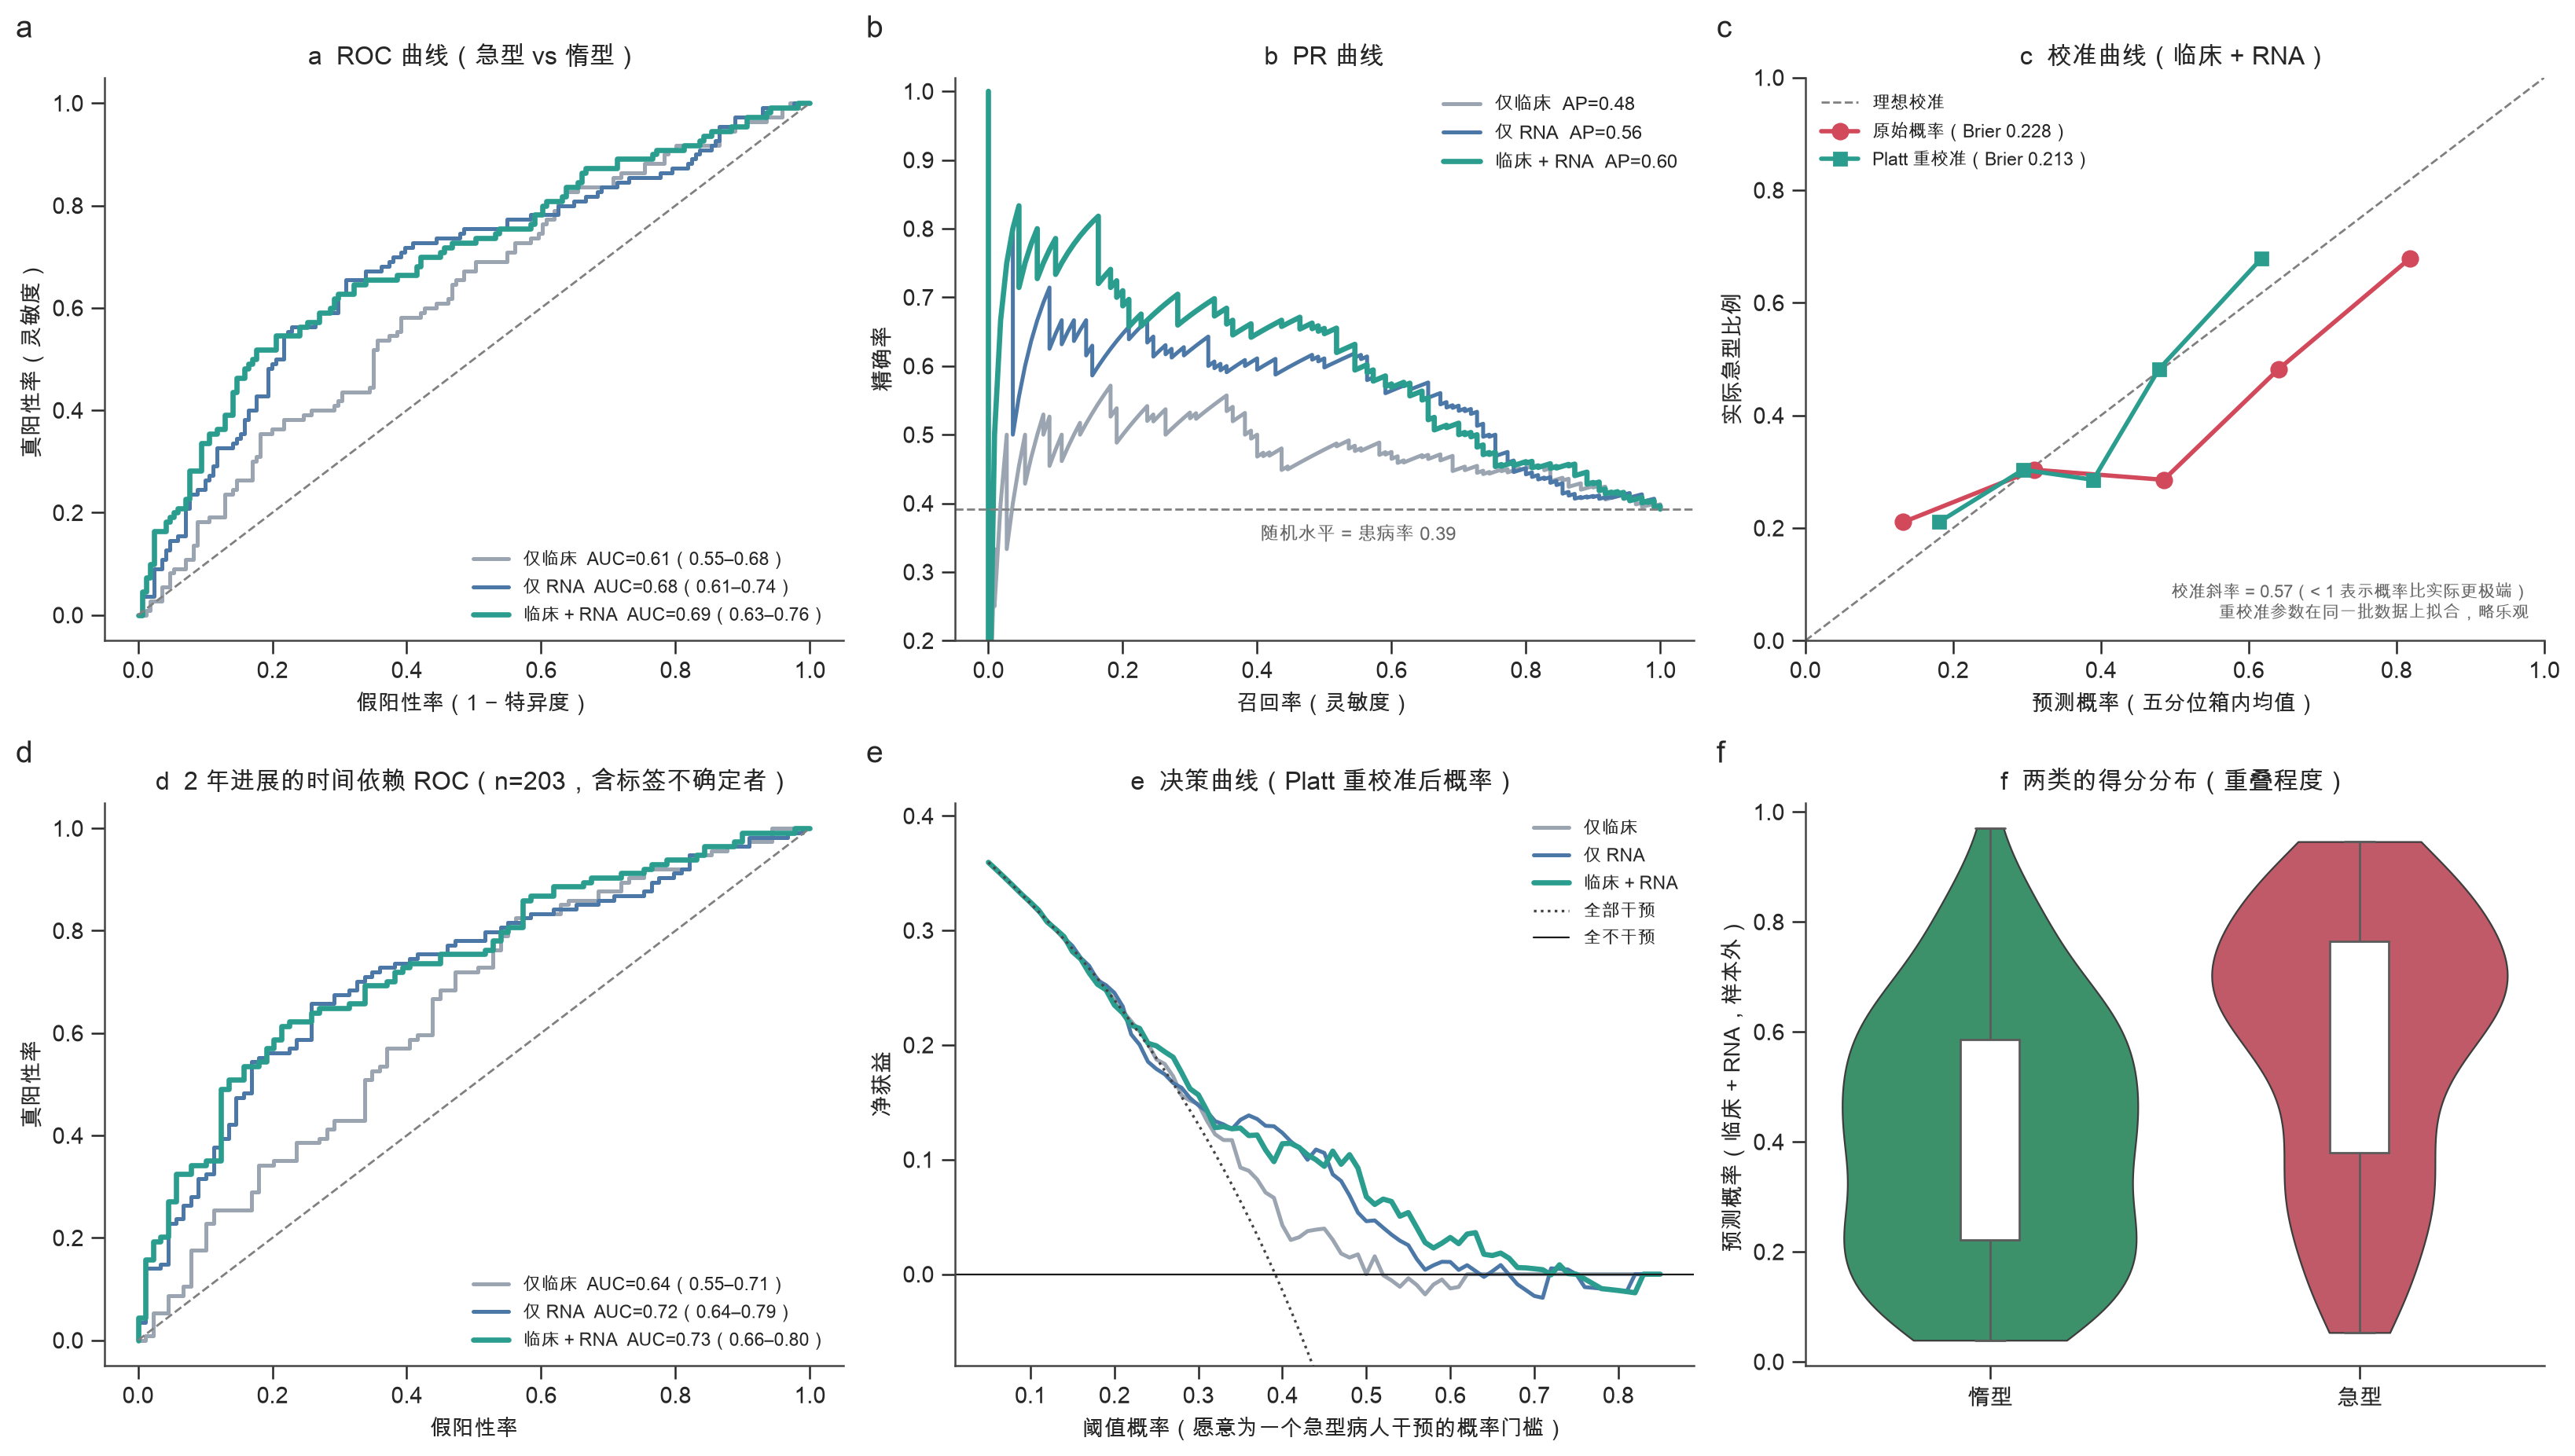

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16.5, 9.4)); axes = axes.ravel()
# a ROC
ax = axes[0]
for k in SC:
    fpr, tpr, _ = roc_curve(yc, SCc[k]); lo, hi = ci(boot_auc[k])
    ax.plot(fpr, tpr, c=COLM[k], lw=2.4 if k == "临床 + RNA" else 1.8, label=f"{k}  AUC={roc_auc_score(yc, SCc[k]):.2f}（{lo:.2f}–{hi:.2f}）")
ax.plot([0, 1], [0, 1], "--", c="grey", lw=1); ax.set(xlabel="假阳性率（1 − 特异度）", ylabel="真阳性率（灵敏度）", title="a  ROC 曲线（急型 vs 惰型）"); ax.legend(fontsize=8.2, loc="lower right"); panel_label(ax, "a", -0.12)
# b PR
ax = axes[1]
for k in SC:
    pr, rc, _ = precision_recall_curve(yc, SCc[k]); ax.plot(rc, pr, c=COLM[k], lw=2.4 if k == "临床 + RNA" else 1.8, label=f"{k}  AP={average_precision_score(yc, SCc[k]):.2f}")
ax.axhline(prev, ls="--", c="grey", lw=1); ax.text(0.55, prev - 0.045, f"随机水平 = 患病率 {prev:.2f}", ha="center", fontsize=8.5, color="#666")
ax.set(xlabel="召回率（灵敏度）", ylabel="精确率", title="b  PR 曲线", ylim=(0.2, 1.02)); ax.legend(fontsize=8.5, loc="upper right"); panel_label(ax, "b", -0.12)
# c 校准
ax = axes[2]
k = "临床 + RNA"; q = pd.qcut(pd.Series(SCc[k]).rank(method="first"), 5, labels=False)
cal = pd.DataFrame({"p": SCc[k], "pp": SCP[k][c_r], "y": yc, "q": q.values}).groupby("q").mean()
ax.plot([0, 1], [0, 1], "--", c="grey", lw=1, label="理想校准")
ax.plot(cal.p, cal.y, "o-", c="#D1495B", lw=2, ms=7, label=f"原始概率（Brier {brier[k]:.3f}）")
ax.plot(cal.pp, cal.y, "s-", c="#2A9D8F", lw=2, ms=6, label=f"Platt 重校准（Brier {brier_p[k]:.3f}）")
ax.set(xlabel="预测概率（五分位箱内均值）", ylabel="实际急型比例", title="c  校准曲线（临床 + RNA）", xlim=(0, 1), ylim=(0, 1)); ax.legend(fontsize=8.3, loc="upper left"); panel_label(ax, "c", -0.12)
ax.text(0.98, 0.04, f"校准斜率 = {CALP['临床 + RNA'][0]:.2f}（< 1 表示概率比实际更极端）\n重校准参数在同一批数据上拟合，略乐观", transform=ax.transAxes, ha="right", fontsize=7.8, color="#666")
# d 时间依赖 ROC
ax = axes[3]
keep2, yy2 = TD[24]
for k in SC:
    fpr, tpr, _ = roc_curve(yy2, SC[k][keep2]); lo, hi = ci(TDB[24][k])
    ax.plot(fpr, tpr, c=COLM[k], lw=2.4 if k == "临床 + RNA" else 1.8, label=f"{k}  AUC={roc_auc_score(yy2, SC[k][keep2]):.2f}（{lo:.2f}–{hi:.2f}）")
ax.plot([0, 1], [0, 1], "--", c="grey", lw=1); ax.set(xlabel="假阳性率", ylabel="真阳性率", title=f"d  2 年进展的时间依赖 ROC（n={len(yy2)}，含标签不确定者）"); ax.legend(fontsize=8.2, loc="lower right"); panel_label(ax, "d", -0.12)
# e 决策曲线
ax = axes[4]; pts = np.linspace(0.05, 0.85, 81)
def nb(prob, y, pt): 
    pos = prob >= pt; return (np.sum(pos & (y == 1)) - np.sum(pos & (y == 0)) * pt / (1 - pt)) / len(y)
for k in SC: ax.plot(pts, [nb(SCP[k][c_r], yc, p) for p in pts], c=COLM[k], lw=2.4 if k == "临床 + RNA" else 1.8, label=k)
ax.plot(pts, [prev - (1 - prev) * p / (1 - p) for p in pts], c="#444", lw=1.2, ls=":", label="全部干预"); ax.axhline(0, c="k", lw=0.8, label="全不干预")
ax.set(xlabel="阈值概率（愿意为一个急型病人干预的概率门槛）", ylabel="净获益", title="e  决策曲线（Platt 重校准后概率）", ylim=(-0.08, max(0.25, prev + 0.02))); ax.legend(fontsize=8.2, loc="upper right"); panel_label(ax, "e", -0.12)
# f 得分分布
ax = axes[5]
dd = pd.DataFrame({"s": SCc["临床 + RNA"], "类": np.where(yc == 1, "急型", "惰型")})
sns.violinplot(data=dd, x="类", y="s", order=["惰型", "急型"], palette={"惰型": "#2E9E6B", "急型": "#D1495B"}, inner=None, cut=0, linewidth=0.8, ax=ax)
sns.boxplot(data=dd, x="类", y="s", order=["惰型", "急型"], width=0.16, showfliers=False, boxprops=dict(facecolor="white", zorder=3), medianprops=dict(color="black"), ax=ax)
ax.set(xlabel="", ylabel="预测概率（临床 + RNA，样本外）", title="f  两类的得分分布（重叠程度）"); panel_label(ax, "f", -0.12)
fig.tight_layout(); savefig(fig, "C2_model_evaluation")

In [26]:
_ca = C1.loc["Clinical only", "AUC"]; _cr = C1.loc["Clinical + RNA", "AUC"]; _ra = C1.loc["RNA", "AUC"]; _all = C1.loc["All 4 omics", "AUC"]; _ca4 = C1.loc["Clinical + all 4 omics", "AUC"]
md(f"""### 阶段 C 结论：能预测，信号几乎全部来自 RNA

**预测对象** 分型"急型"（占 {FAST_SHARE:.0%}）。训练只用标签确定的患者；评估是 5 折 × 重复的样本外 AUC。

**各数据来源（C1）** 纯临床 AUC = {_ca:.3f}；**RNA 单独 = {_ra:.3f}**；甲基化 {C1.loc['Methylation','AUC']:.3f}、CNV {C1.loc['CNV','AUC']:.3f}、突变 {C1.loc['Mutation','AUC']:.3f}；四种组学合用 {_all:.3f}（**比 RNA 单独更低**：额外的三种组学带来的是噪声）；**临床 + RNA = {_cr:.3f}**；临床 + 四种组学 = {_ca4:.3f}。同一批有 RNA 的患者（n={len(ids_rna)}）上：临床 {C1b['Clinical only'][0]:.3f} → 临床 + RNA {C1b['Clinical + RNA'][0]:.3f}。

**模型选择（C2）** {MODEL_SEL}，每模态 {KK_SEL} 个特征；逻辑回归的几种设置差异很小，随机森林和梯度提升不优于逻辑回归；特征数取 100 时性能下降（过拟合）。选择在同一批数据上做，略乐观。

**增量是真的吗（C3）** 只打乱 RNA 行 60 次，"临床 + 乱序 RNA"的 AUC = {null.mean():.3f} ± {null.std():.3f}（最大 {null.max():.3f}），观察 {a_r:.3f}，**置换 p ≤ {p_perm:.3f}**。**批次**：RNA 特征按录入中心去均值后 AUC = {a_dm:.3f}（原 {a_r:.3f}）；"临床 + 中心哑变量" = {a_ct:.3f}（纯临床 {a_c:.3f}），中心本身不能替代 RNA。

**风险分档（C4）** 临床 + RNA 的样本外风险分三分位：高 / 中 / 低档的 2 年累积进展率 = {C4.loc[('Clinical + RNA','High'),'PFI_2y']:.0%} / {C4.loc[('Clinical + RNA','Mid'),'PFI_2y']:.0%} / {C4.loc[('Clinical + RNA','Low'),'PFI_2y']:.0%}（纯临床：{C4.loc[('Clinical only','High'),'PFI_2y']:.0%} / {C4.loc[('Clinical only','Mid'),'PFI_2y']:.0%} / {C4.loc[('Clinical only','Low'),'PFI_2y']:.0%}）；PFI log-rank p = {C4.loc[('Clinical + RNA','High'),'logrank_PFI']:.1g}（纯临床 {C4.loc[('Clinical only','High'),'logrank_PFI']:.1g}），OS log-rank p = {C4.loc[('Clinical + RNA','High'),'logrank_OS']:.1g}。高风险档 vs 其余 PFI HR = {hr_hi.iloc[0]:.2f}（{hr_hi.iloc[1]:.2f}–{hr_hi.iloc[2]:.2f}）。**真正分开的是"高风险"与其余两档**；低档与中档差别不大。

**评测曲线（C5）** 标签确定者上，临床 + RNA 的 AUC = {roc_auc_score(yc, SCc['临床 + RNA']):.3f}（自举 95% 区间 {ci(boot_auc['临床 + RNA'])[0]:.2f}–{ci(boot_auc['临床 + RNA'])[1]:.2f}），仅临床 {roc_auc_score(yc, SCc['仅临床']):.3f}，仅 RNA {roc_auc_score(yc, SCc['仅 RNA']):.3f}；相对仅临床的 AUC 增量 {np.mean(d_auc):+.3f}（区间 {ci(d_auc)[0]:+.3f} 到 {ci(d_auc)[1]:+.3f}，自举 p = {p_dauc:.3f}）。平均精确率 AP = {average_precision_score(yc, SCc['临床 + RNA']):.2f}（随机水平 {prev:.2f}）。**不依赖混合模型标签**、直接对实际 2 年进展评估（n={len(TD[24][1])}，含标签不确定者）：临床 + RNA 的时间依赖 AUC = {roc_auc_score(TD[24][1], SC['临床 + RNA'][TD[24][0]]):.3f}，仅临床 {roc_auc_score(TD[24][1], SC['仅临床'][TD[24][0]]):.3f}（差 {np.mean(d_td):+.3f}，p = {p_dtd:.3f}）。校准：原始概率的 Brier = {brier['临床 + RNA']:.3f}，略优于"全部预测患病率"的参考值 {brier_ref:.3f}（仅临床 {brier['仅临床']:.3f}，反而**差于**参考）；校准斜率 = {CALP['临床 + RNA'][0]:.2f}（理想为 1，< 1 表示预测概率比实际更极端，即过度自信），Platt 重校准后 Brier {brier_p['临床 + RNA']:.3f}（重校准参数在同一批数据上拟合，略乐观）。**概率的绝对值不能直接当风险用，排序（AUC）不受影响。** 口径提醒：C5 的 AUC 用 10 次重复的**平均概率**计算，集成平均会让 AUC 略高于 C1/C3 逐次平均的数字（0.695 对 0.675），所以 +0.08 与前面的 +0.06 不矛盾，只是口径不同。高风险档灵敏度 / 特异度 = {sens_spec('临床 + RNA')[0]:.2f} / {sens_spec('临床 + RNA')[1]:.2f}。

**如实评价** AUC 约 {_cr:.2f} 属于中等水平，不是个体诊断工具；增量 +{_cr-_ca:.2f} 经置换检验成立；多组学整合在本数据上没有额外收益，应表述为"临床 + RNA"。没有外部队列验证，超参数选择略乐观。
""")

### 阶段 C 结论：能预测，信号几乎全部来自 RNA

**预测对象** 分型"急型"（占 37%）。训练只用标签确定的患者；评估是 5 折 × 重复的样本外 AUC。

**各数据来源（C1）** 纯临床 AUC = 0.614；**RNA 单独 = 0.660**；甲基化 0.558、CNV 0.565、突变 0.498；四种组学合用 0.633（**比 RNA 单独更低**：额外的三种组学带来的是噪声）；**临床 + RNA = 0.675**；临床 + 四种组学 = 0.656。同一批有 RNA 的患者（n=367）上：临床 0.614 → 临床 + RNA 0.678。

**模型选择（C2）** LR-L2 (C=0.2)，每模态 20 个特征；逻辑回归的几种设置差异很小，随机森林和梯度提升不优于逻辑回归；特征数取 100 时性能下降（过拟合）。选择在同一批数据上做，略乐观。

**增量是真的吗（C3）** 只打乱 RNA 行 60 次，"临床 + 乱序 RNA"的 AUC = 0.544 ± 0.050（最大 0.664），观察 0.675，**置换 p ≤ 0.016**。**批次**：RNA 特征按录入中心去均值后 AUC = 0.675（原 0.675）；"临床 + 中心哑变量" = 0.586（纯临床 0.611），中心本身不能替代 RNA。

**风险分档（C4）** 临床 + RNA 的样本外风险分三分位：高 / 中 / 低档的 2 年累积进展率 = 66% / 32% / 27%（纯临床：49% / 45% / 30%）；PFI log-rank p = 3e-09（纯临床 0.005），OS log-rank p = 5e-05。高风险档 vs 其余 PFI HR = 2.93（2.05–4.18）。**真正分开的是"高风险"与其余两档**；低档与中档差别不大。

**评测曲线（C5）** 标签确定者上，临床 + RNA 的 AUC = 0.695（自举 95% 区间 0.63–0.76），仅临床 0.614，仅 RNA 0.679；相对仅临床的 AUC 增量 +0.082（区间 +0.012 到 +0.152，自举 p = 0.022）。平均精确率 AP = 0.60（随机水平 0.39）。**不依赖混合模型标签**、直接对实际 2 年进展评估（n=203，含标签不确定者）：临床 + RNA 的时间依赖 AUC = 0.735，仅临床 0.637（差 +0.098，p = 0.018）。校准：原始概率的 Brier = 0.228，略优于"全部预测患病率"的参考值 0.238（仅临床 0.242，反而**差于**参考）；校准斜率 = 0.57（理想为 1，< 1 表示预测概率比实际更极端，即过度自信），Platt 重校准后 Brier 0.213（重校准参数在同一批数据上拟合，略乐观）。**概率的绝对值不能直接当风险用，排序（AUC）不受影响。** 口径提醒：C5 的 AUC 用 10 次重复的**平均概率**计算，集成平均会让 AUC 略高于 C1/C3 逐次平均的数字（0.695 对 0.675），所以 +0.08 与前面的 +0.06 不矛盾，只是口径不同。高风险档灵敏度 / 特异度 = 0.55 / 0.78。

**如实评价** AUC 约 0.68 属于中等水平，不是个体诊断工具；增量 +0.06 经置换检验成立；多组学整合在本数据上没有额外收益，应表述为"临床 + RNA"。没有外部队列验证，超参数选择略乐观。


---
# 阶段 D：RNA 对预测的贡献

阶段 C 表明信号几乎全部来自 RNA。这里回答：**RNA 的贡献有多大、集中在哪些基因、方向是什么**。

| 步骤 | 内容 |
|---|---|
| D1 | 稳定入选的基因：5 折 × 20 重复共 100 个模型，每个基因被选中的频率与系数方向 |
| D2 | 贡献曲线：每折内选 k 个基因（+ 临床）的预测能力随 k 变化（无偏），与"全数据排序取前 k 个"（偏乐观）对照 |
| D3 | 与临床变量的贡献比较；稳定基因在急型 / 惰型中的表达 |

## D1 稳定入选基因

100 个模型；入选过的基因 189 个；频率 ≥ 0.5 的 11 个；≥ 0.8 的 3 个（每次只选 20 个，若无信号则几乎没有基因会反复入选）


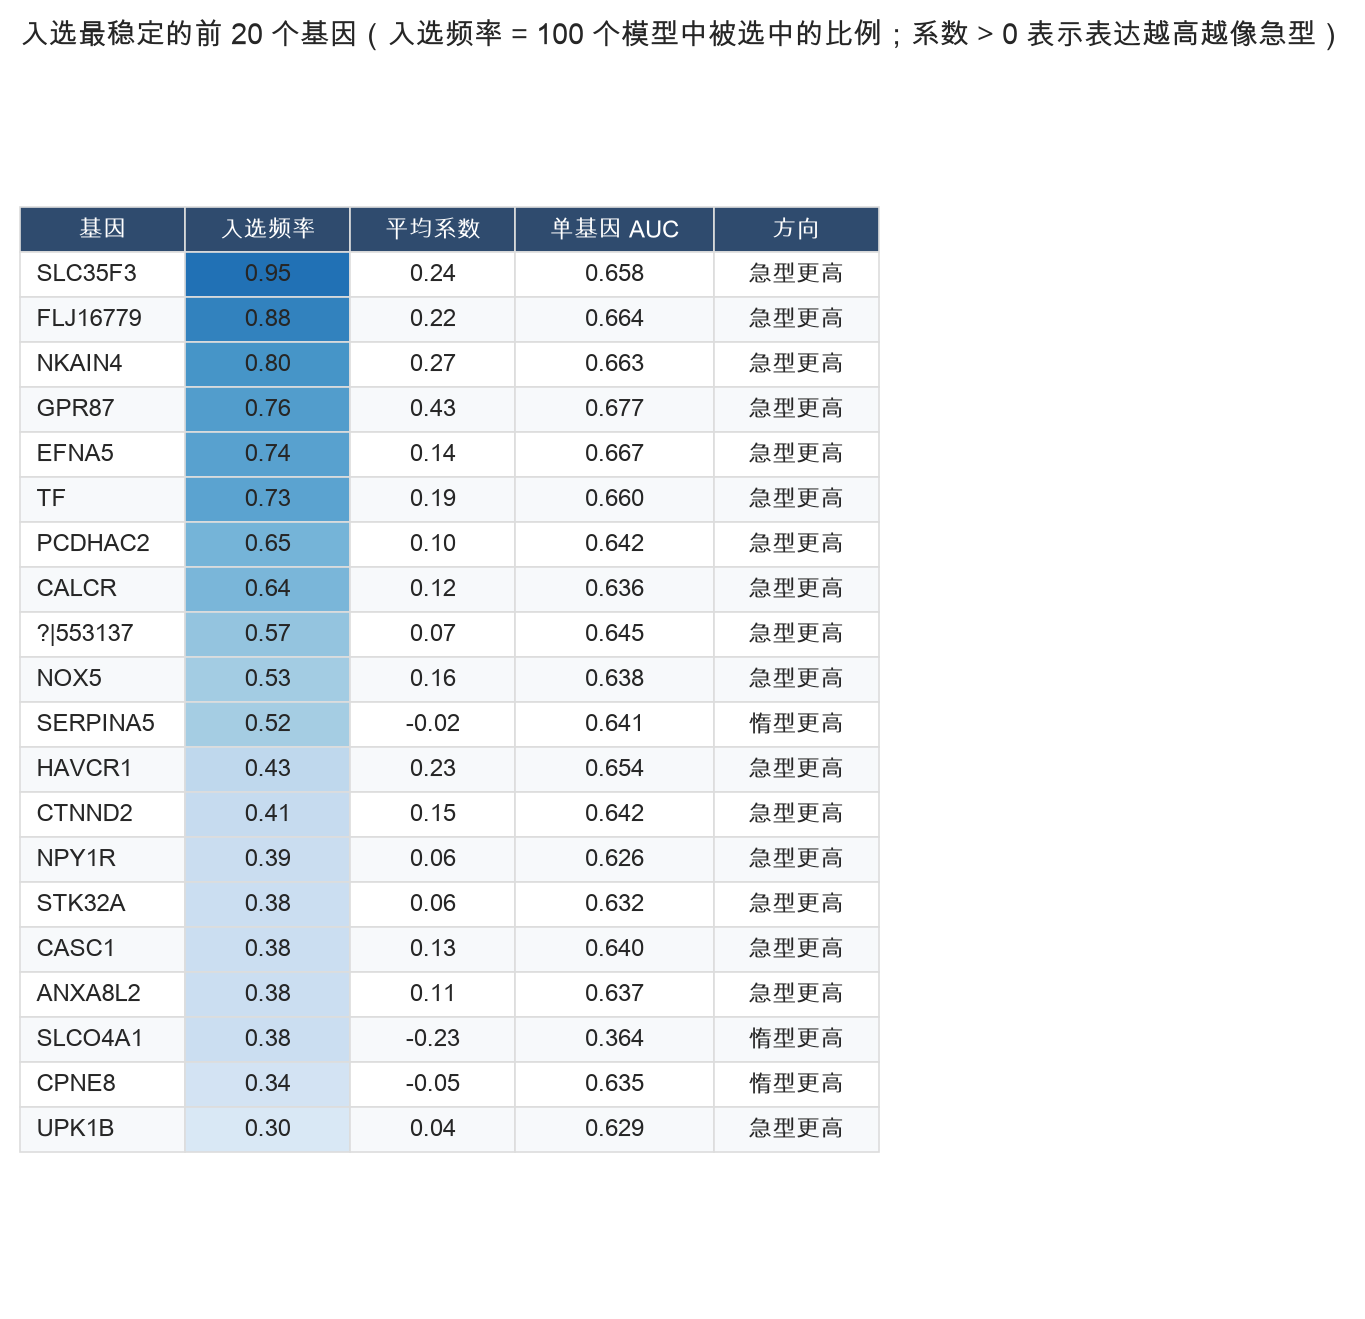

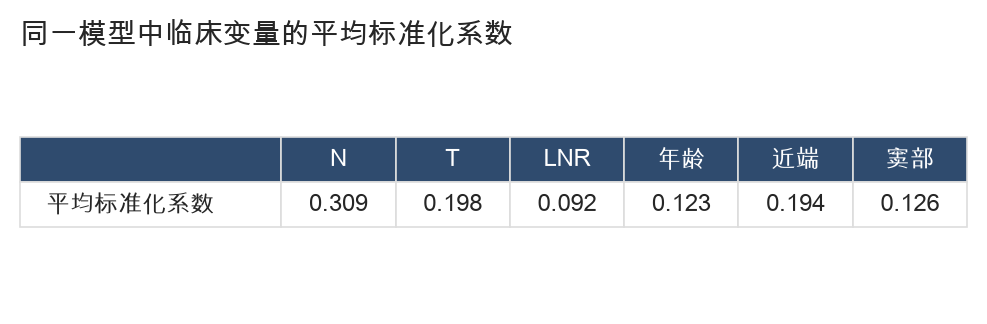

In [27]:
Xr, fr, br = build_X(["RNA"], ids_rna, True)
ncl_ = len(br["Clin"]); genes_rna = np.array([f.split("|", 1)[1] for f in fr[ncl_:]])
CLIN_NAMES = ["N", "T", "LNR", "Age", "Proximal", "Antrum"]
strat_ = np.where(c_r, y_r, 2)
def _stab_fold(tr, te):
    trc = tr[c_r[tr]]; sel = BlockSelector(br, KK_SEL).fit(Xr[trc], y_r[trc]); m = make_model(MODEL_SEL).fit(sel.transform(Xr[trc]), y_r[trc])
    return sel.selected_indices(), m.coef_[0]
jobs = [(tr, te) for r in range(20) for tr, te in StratifiedKFold(5, shuffle=True, random_state=r).split(Xr, strat_)]
res_ = Parallel(n_jobs=N_JOBS)(delayed(_stab_fold)(tr, te) for tr, te in jobs)
cnt = pd.Series(0.0, index=genes_rna); csum = pd.Series(0.0, index=genes_rna); ccoef = np.zeros(ncl_)
for idx, cf_ in res_:
    rn = [i - ncl_ for i in idx if i >= ncl_]
    for gi, cc in zip(rn, cf_[ncl_:]): cnt.iloc[gi] += 1; csum.iloc[gi] += cc
    ccoef += cf_[:ncl_]
nfit = len(res_)
STAB_G = pd.DataFrame({"freq": cnt / nfit, "mean_coef": csum / np.maximum(cnt, 1)}).sort_values("freq", ascending=False)
Xg_ = OM["RNA"].reindex(ids_rna).fillna(0)
STAB_G["AUC_single"] = [roc_auc_score(y_r[c_r], Xg_[g].values[c_r]) for g in STAB_G.index]
STAB_G["direction"] = np.where(STAB_G.mean_coef > 0, "higher in FAST", "higher in SLOW")
CLIN_COEF = pd.Series(ccoef / nfit, index=CLIN_NAMES)
n_any, n50, n80 = int((STAB_G.freq > 0).sum()), int((STAB_G.freq >= .5).sum()), int((STAB_G.freq >= .8).sum())
print(f"{nfit} 个模型；入选过的基因 {n_any} 个；频率 ≥ 0.5 的 {n50} 个；≥ 0.8 的 {n80} 个（每次只选 {KK_SEL} 个，若无信号则几乎没有基因会反复入选）")
show_table(STAB_G.head(20)[["freq", "mean_coef", "AUC_single", "direction"]].assign(direction=lambda d: np.where(d.mean_coef > 0, "急型更高", "惰型更高")).rename(columns={"freq": "入选频率", "mean_coef": "平均系数", "AUC_single": "单基因 AUC", "direction": "方向"}).rename_axis("基因"), "T_D1_stable_genes", "入选最稳定的前 20 个基因（入选频率 = 100 个模型中被选中的比例；系数 > 0 表示表达越高越像急型）", fmt={"入选频率": "{:.2f}", "平均系数": "{:.2f}", "单基因 AUC": "{:.3f}"}, hl=["入选频率"])
show_table(CLIN_COEF.round(3).to_frame("平均标准化系数").T.rename(columns={"Age": "年龄", "Proximal": "近端", "Antrum": "窦部"}), "T_D1_clinical_coefficients", "同一模型中临床变量的平均标准化系数", fmt={c: "{:.3f}" for c in ["N", "T", "LNR", "年龄", "近端", "窦部"]})
STABLE = STAB_G.index[STAB_G.freq >= 0.5].tolist()

## D2 贡献曲线：需要多少个基因

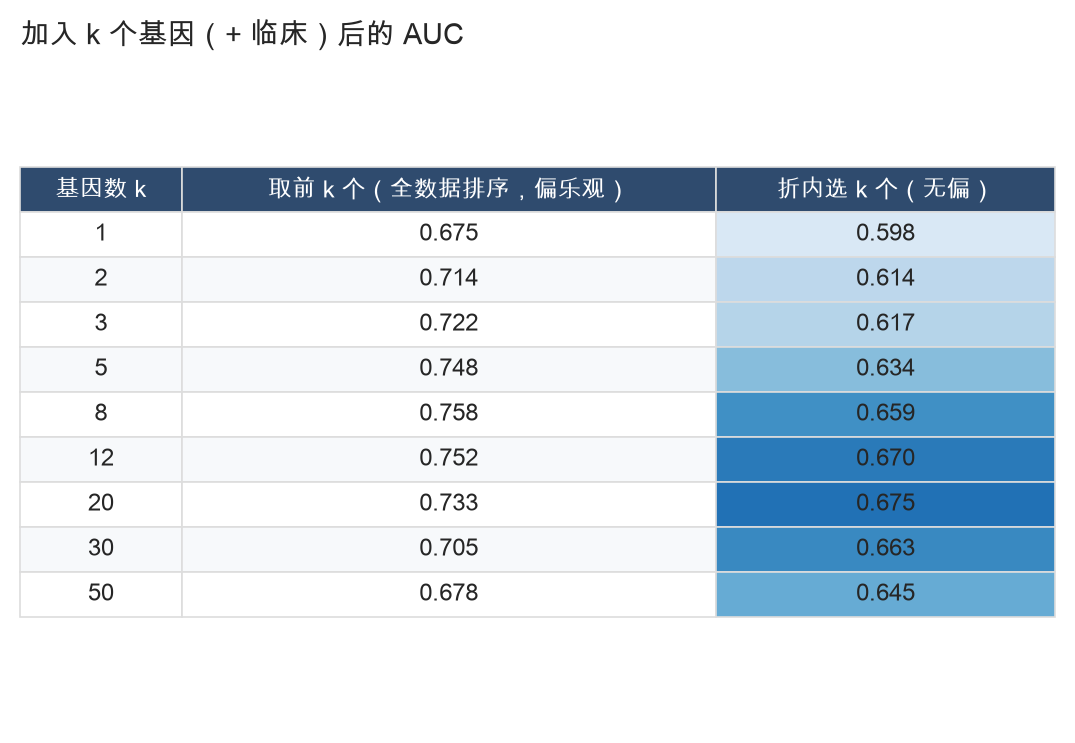

,取前 k 个（全数据排序，偏乐观）,折内选 k 个（无偏）
基因数 k,,
1,0.675279,0.597629
2,0.714195,0.614460
3,0.721659,0.617076
5,0.748421,0.634003
8,0.758394,0.659468
12,0.751579,0.670303
20,0.732600,0.674769
30,0.705348,0.663020
50,0.677544,0.644572


In [28]:
def eval_topk(genes_k, clin_=True, reps=5):
    cols = genes_k
    mats, bl, pos = [], {}, 0
    if clin_: a = clin_matrix(ids_rna); mats.append(a); bl["Clin"] = list(range(a.shape[1])); pos = a.shape[1]
    x = OM["RNA"].reindex(ids_rna)[cols].fillna(0).values; mats.append(x); bl["RNA"] = list(range(pos, pos + len(cols)))
    X_ = np.hstack(mats)
    return cv_pred(X_, y_r, c_r, bl, MODEL_SEL, len(cols), reps=reps)[0]
KS = [1, 2, 3, 5, 8, 12, 20, 30, 50]
# 注意：基因排序用的是全部数据上的稳定性，评估里再做一次折内重选会更严格——这里同时给出"折内重选"的结果作为无偏对照
rows = []
for k in KS:
    a_fixed = eval_topk(STAB_G.index[:k].tolist(), True, reps=5)
    a_nested = cv_pred(Xr, y_r, c_r, br, MODEL_SEL, k, reps=5)[0]
    rows.append(dict(k=k, AUC_top_k_fixed=a_fixed, AUC_nested_selection=a_nested))
D2 = pd.DataFrame(rows).set_index("k")
show_table(D2.rename(columns={"AUC_top_k_fixed": "取前 k 个（全数据排序，偏乐观）", "AUC_nested_selection": "折内选 k 个（无偏）"}).rename_axis("基因数 k"), "T_D2_genes_needed", "加入 k 个基因（+ 临床）后的 AUC", fmt={"取前 k 个（全数据排序，偏乐观）": "{:.3f}", "折内选 k 个（无偏）": "{:.3f}"}, hl=["折内选 k 个（无偏）"], wrap=18)

# 说明：曾尝试"去掉最稳定的前 j 个基因后重训"来判断信号是否集中，但这些基因是用**全部数据**挑出来的，
# 去掉它们等于同时剔除了在这批样本里偶然最强的特征，剩下的候选池会比随机池更差（AUC 甚至跌破 0.5），
# 这是选择偏差，不能解读为"信号集中"。因此该检验已删除；"需要多少基因"只看上面的 nested 曲线。

## D3 与临床变量比较；稳定基因的表达模式

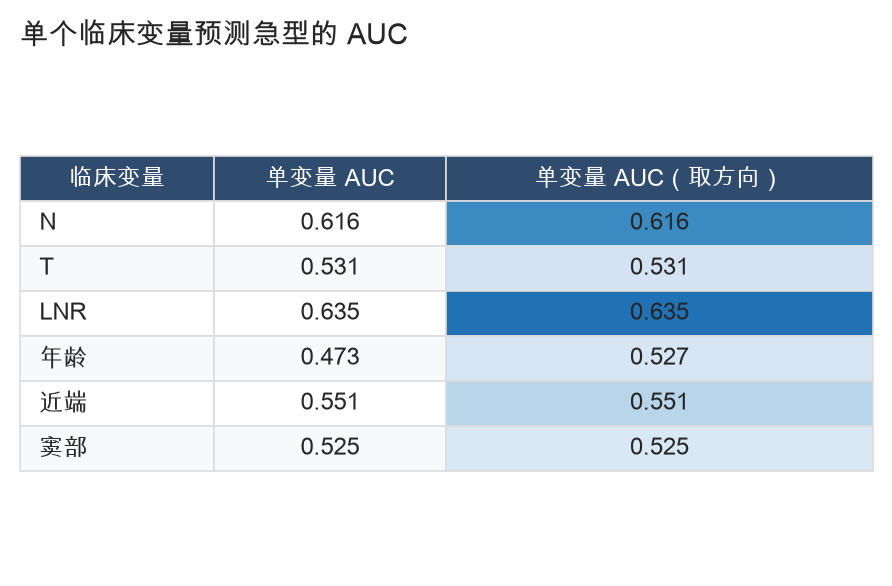

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


稳定基因（频率 ≥ 0.5）共 11 个；热图按它们的等权平均分排序（仅用于展示，不报告 AUC）


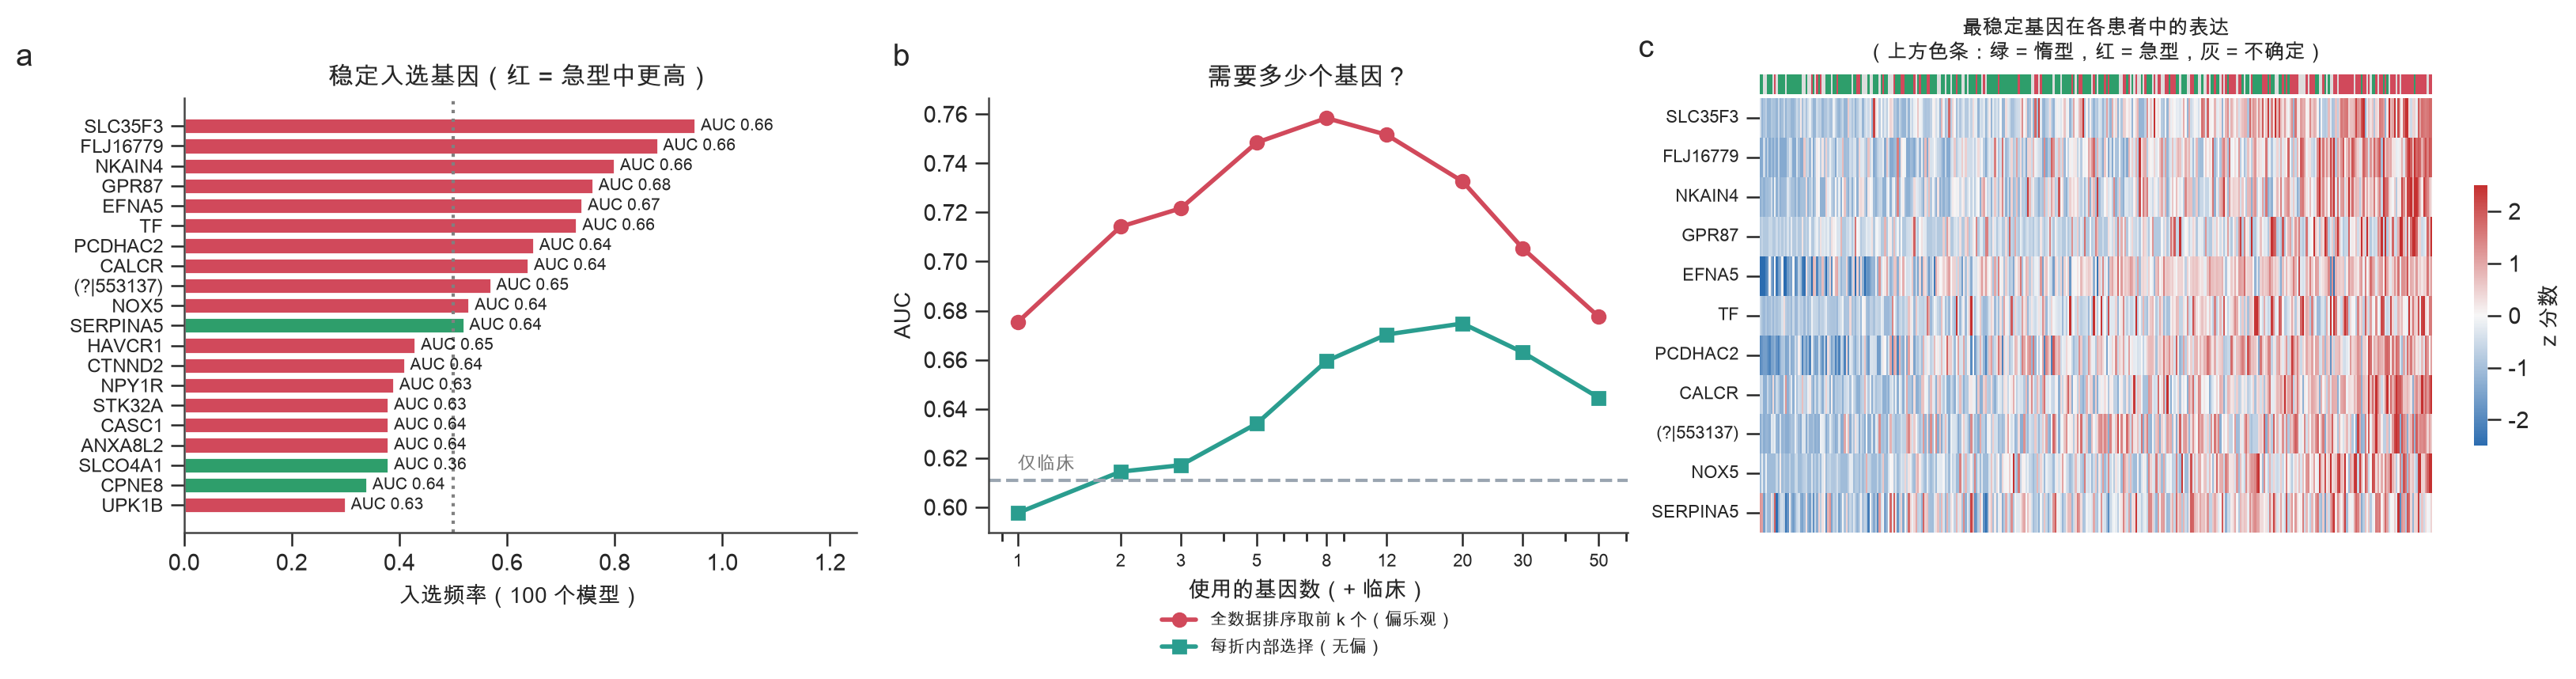

In [29]:
# 临床单变量的 AUC
cm_ = clin_matrix(ids_rna); rows = []
for j, nm in enumerate(CLIN_NAMES): rows.append(dict(variable=nm, AUC_single=roc_auc_score(y_r[c_r], cm_[c_r, j])))
D3c = pd.DataFrame(rows).set_index("variable"); D3c["AUC_single_oriented"] = np.maximum(D3c.AUC_single, 1 - D3c.AUC_single)
show_table(D3c.rename(index={"Age": "年龄", "Proximal": "近端", "Antrum": "窦部"}).rename(columns={"AUC_single": "单变量 AUC", "AUC_single_oriented": "单变量 AUC（取方向）"}).rename_axis("临床变量"), "T_D3_clinical_single_AUC", "单个临床变量预测急型的 AUC", fmt={"单变量 AUC": "{:.3f}", "单变量 AUC（取方向）": "{:.3f}"}, hl=["单变量 AUC（取方向）"])
# 稳定基因总体
z_ = (Xg_[STABLE] - Xg_[STABLE].mean()) / Xg_[STABLE].std() if STABLE else pd.DataFrame(index=ids_rna)
score_ = (z_ * np.sign(STAB_G.loc[STABLE, "mean_coef"].values)).mean(axis=1) if STABLE else pd.Series(0, index=ids_rna)
auc_sig = roc_auc_score(y_r[c_r], score_.values[c_r]) if STABLE else np.nan
print(f"稳定基因（频率 ≥ 0.5）共 {len(STABLE)} 个；热图按它们的等权平均分排序（仅用于展示，不报告 AUC）")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.0), gridspec_kw=dict(width_ratios=[1.0, 0.95, 1.25]))
ax = axes[0]
tp_ = STAB_G.head(20).iloc[::-1]
ax.barh(range(len(tp_)), tp_.freq, color=["#D1495B" if c > 0 else "#2E9E6B" for c in tp_.mean_coef], edgecolor="white")
ax.set_yticks(range(len(tp_))); ax.set_yticklabels([g if g[0].isalpha() else f"({g})" for g in tp_.index], fontsize=8.5)
for i_, (f_, a_) in enumerate(zip(tp_.freq, tp_.AUC_single)): ax.text(f_ + 0.01, i_, f"AUC {a_:.2f}", va="center", fontsize=7.5)
ax.set_xlim(0, 1.25); ax.axvline(0.5, ls=":", c="grey")
ax.set(xlabel=f"入选频率（{nfit} 个模型）", title="稳定入选基因（红 = 急型中更高）"); panel_label(ax, "a", -0.25)
ax = axes[1]
ax.plot(D2.index, D2.AUC_top_k_fixed, "o-", c="#D1495B", lw=2, ms=6, label="全数据排序取前 k 个（偏乐观）")
ax.plot(D2.index, D2.AUC_nested_selection, "s-", c="#2A9D8F", lw=2, ms=6, label="每折内部选择（无偏）")
ax.axhline(a_c, ls="--", c="#9AA5B1"); ax.text(D2.index.min(), a_c + 0.004, "仅临床", ha="left", color="#7A7A7A", fontsize=8.5)
ax.set_xscale("log"); ax.set_xticks(KS); ax.set_xticklabels(KS, fontsize=8)
ax.set(xlabel="使用的基因数（+ 临床）", ylabel="AUC", title="需要多少个基因？"); ax.legend(fontsize=7.8, loc="lower center", bbox_to_anchor=(0.5, -0.32)); panel_label(ax, "b", -0.15)
ax = axes[2]
if STABLE:
    show = STAB_G.head(min(15, max(len(STABLE), 8))).index.tolist()
    zz = Xg_[show].copy(); zz = (zz - zz.mean()) / zz.std()
    order_pat = np.argsort(score_.values)
    zz = zz.iloc[order_pat]; cls_ = np.where(y_r[order_pat] == 1, 1, 0); cf_o = c_r[order_pat]
    zz.columns = [g if g[0].isalpha() else f"({g})" for g in zz.columns]
    sns.heatmap(zz.T, cmap=DIV_CMAP, center=0, vmin=-2.5, vmax=2.5, ax=ax, cbar_kws=dict(label="z 分数", shrink=0.6), xticklabels=False, yticklabels=True)
    ax.tick_params(axis="y", labelsize=8)
    bar = ax.inset_axes([0, 1.01, 1, 0.045]); bar.imshow(np.array([np.where(cf_o, cls_, 2)]), aspect="auto", cmap=ListedColormap(["#2E9E6B", "#D1495B", "#DDDDDD"]), vmin=0, vmax=2, interpolation="nearest"); bar.set_axis_off()
    ax.set_title("最稳定基因在各患者中的表达\n（上方色条：绿 = 惰型，红 = 急型，灰 = 不确定）", fontsize=9.5, pad=18)
panel_label(ax, "c", -0.18, 1.08)
fig.tight_layout(); savefig(fig, "D1_RNA_contribution")

In [30]:
_top5 = ", ".join(f"{g} ({'+' if STAB_G.loc[g,'mean_coef']>0 else '−'})" for g in STAB_G.index[:8])
_a1 = D2.loc[1, "AUC_nested_selection"]; _a5 = D2.loc[5, "AUC_nested_selection"]; _a20 = D2.loc[20, "AUC_nested_selection"]; _a50 = D2.loc[50, "AUC_nested_selection"]
_nf8 = D2.loc[8, "AUC_top_k_fixed"]
md(f"""### 阶段 D 结论：RNA 的贡献

**哪些基因反复被选中** {nfit} 个模型中，入选过的基因共 {n_any} 个（来自 5000 个候选），频率 ≥ 0.5 的 **{n50}** 个，≥ 0.8 的 {n80} 个。稳定性最高的 8 个（+ = 表达越高越像急型）：{_top5}。单个基因的 AUC 最高也只有 {STAB_G.AUC_single.max():.2f}；也就是说没有"一个基因就能分开"的明星基因，每个基因只贡献一小部分。

**需要多少基因（D2，折内选择，无偏）** 临床单独 AUC = {a_c:.3f}；再加 1 / 5 / 20 / 50 个 RNA 基因：{_a1:.3f} / {_a5:.3f} / {_a20:.3f} / {_a50:.3f}。**加 1 个基因甚至低于临床单独**；到 20 个附近最好，超过后下降（过拟合）。对照：用全数据排序后取前 k 个，k = 8 时 AUC 可达 {_nf8:.2f}，这是**用了全部数据挑基因造成的虚高**，不是真实性能。

**与临床变量比较（D3）** 单变量 AUC（取朝向）：{', '.join(f'{k} {v:.2f}' for k, v in D3c['AUC_single_oriented'].items())}。单个 RNA 基因（最高 {STAB_G.AUC_single.max():.2f}）比任何单个临床变量（最高 {D3c['AUC_single_oriented'].max():.2f}）都强一些，但差距不大。

**说明** ① "稳定"指在不同训练折里反复被选中，不等于因果驱动。② 这里没有给"稳定基因集的整体 AUC"，因为基因集是用全部数据确定的，再用同一批数据评价会偏乐观（本图 b 的红线就是这种偏差）。③ 基因名为 `?|数字` 的是数据中未注释的探针。
""")

### 阶段 D 结论：RNA 的贡献

**哪些基因反复被选中** 100 个模型中，入选过的基因共 189 个（来自 5000 个候选），频率 ≥ 0.5 的 **11** 个，≥ 0.8 的 3 个。稳定性最高的 8 个（+ = 表达越高越像急型）：SLC35F3 (+), FLJ16779 (+), NKAIN4 (+), GPR87 (+), EFNA5 (+), TF (+), PCDHAC2 (+), CALCR (+)。单个基因的 AUC 最高也只有 0.68；也就是说没有"一个基因就能分开"的明星基因，每个基因只贡献一小部分。

**需要多少基因（D2，折内选择，无偏）** 临床单独 AUC = 0.611；再加 1 / 5 / 20 / 50 个 RNA 基因：0.598 / 0.634 / 0.675 / 0.645。**加 1 个基因甚至低于临床单独**；到 20 个附近最好，超过后下降（过拟合）。对照：用全数据排序后取前 k 个，k = 8 时 AUC 可达 0.76，这是**用了全部数据挑基因造成的虚高**，不是真实性能。

**与临床变量比较（D3）** 单变量 AUC（取朝向）：N 0.62, T 0.53, LNR 0.63, Age 0.53, Proximal 0.55, Antrum 0.52。单个 RNA 基因（最高 0.68）比任何单个临床变量（最高 0.63）都强一些，但差距不大。

**说明** ① "稳定"指在不同训练折里反复被选中，不等于因果驱动。② 这里没有给"稳定基因集的整体 AUC"，因为基因集是用全部数据确定的，再用同一批数据评价会偏乐观（本图 b 的红线就是这种偏差）。③ 基因名为 `?|数字` 的是数据中未注释的探针。


## D4 SHAP：模型到底怎么用这些特征

最终模型是（带 L2 惩罚的）逻辑回归，所以用 `LinearExplainer` 得到的 SHAP 值是**精确**的，不是近似；每个病人的 SHAP 值之和加基线值等于模型输出的 log-odds。

做法（避免"用训练数据解释自己"）：
1. 5 折 × 重复共 100 个折内模型，每折只在训练折里选特征、拟合；
2. 对**该折没见过的病人**计算 SHAP 值；
3. 每折选中的基因不同，把没入选该折的基因记 0，再对所有重复取平均，得到"每个病人 × 每个特征"的样本外 SHAP 矩阵。

SHAP 解释的是**模型**用了什么，不是因果。

SHAP 矩阵：(367, 5006)（患者 × 特征），每位患者被 10–10 个未见过他的模型解释；基线 log-odds 均值 -0.19
临床变量 6 个，占总 |SHAP| 的 26%；RNA 基因占 74%
SHAP 重要性与 D1 入选频率的 Spearman 相关（入选过的基因）= 0.80（p = 7.8e-44）
临床变量：特征值与 SHAP 值的 Spearman（> 0 表示取值越大越推向急型）: {np.str_('N'): np.float64(0.95), np.str_('T'): np.float64(0.9), np.str_('LNR'): np.float64(0.94), np.str_('Age'): np.float64(0.99), np.str_('Proximal'): np.float64(0.58), np.str_('Antrum'): np.float64(0.72)}
前 10 个 RNA 基因：特征值与 SHAP 的 Spearman: {'GPR87': np.float64(1.0), 'SLC35F3': np.float64(1.0), 'NKAIN4': np.float64(1.0), 'FLJ16779': np.float64(1.0), 'TF': np.float64(0.99), 'EFNA5': np.float64(0.98), 'HAVCR1': np.float64(0.99), 'NOX5': np.float64(0.99), 'CALCR': np.float64(0.99), 'ASCL2': np.float64(-0.99)}


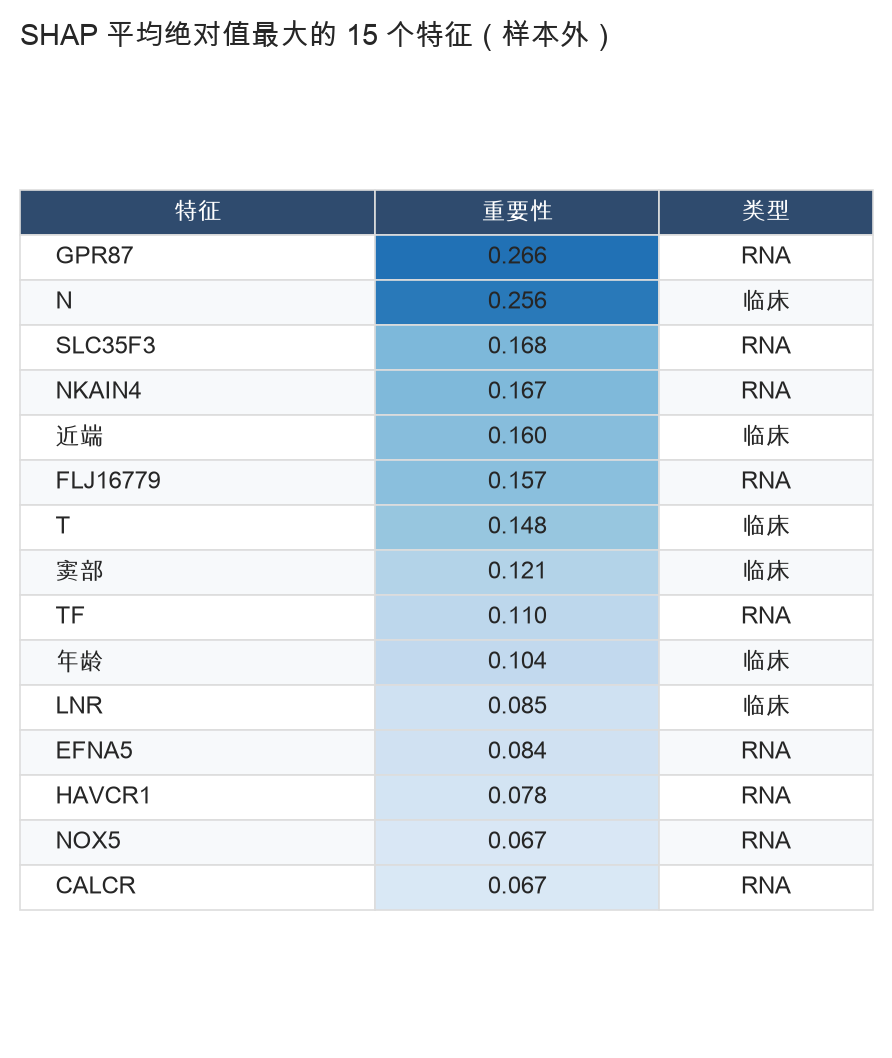

,重要性,类型
特征,,
GPR87,0.265909,RNA
N,0.256211,临床
SLC35F3,0.167571,RNA
NKAIN4,0.166825,RNA
近端,0.160372,临床
FLJ16779,0.157320,RNA
T,0.147700,临床
窦部,0.120515,临床
TF,0.109624,RNA


In [31]:
import shap
shap.initjs = lambda: None
Xr, fr, br = build_X(["RNA"], ids_rna, True)
ncl_ = len(br["Clin"]); feat_names = np.array(CLIN_NAMES + [f.split("|", 1)[1] for f in fr[ncl_:]])
n_pat, n_feat = Xr.shape[0], Xr.shape[1]
SHAP_SUM = np.zeros((n_pat, n_feat)); SHAP_CNT = np.zeros(n_pat); EXP_VAL = []
TEST_Z = np.zeros((n_pat, n_feat)); TEST_RAW = np.zeros((n_pat, n_feat))        # 标准化后的特征值（用于着色）
strat_ = np.where(c_r, y_r, 2)
def _shap_fold(tr, te):
    trc = tr[c_r[tr]]; sel = BlockSelector(br, KK_SEL).fit(Xr[trc], y_r[trc])
    m = make_model(MODEL_SEL).fit(sel.transform(Xr[trc]), y_r[trc])
    Ztr, Zte = sel.transform(Xr[trc]), sel.transform(Xr[te])
    ex = shap.explainers.Linear(m, shap.maskers.Independent(Ztr, max_samples=len(Ztr))); sv = ex.shap_values(Zte)
    full = np.zeros((len(te), n_feat)); zfull = np.zeros((len(te), n_feat))
    idx = sel.selected_indices(); full[:, idx] = sv; zfull[:, idx] = Zte
    return te, full, zfull, float(np.ravel(ex.expected_value)[0])
_N_REP = 10
_jobs = [(tr, te) for r in range(_N_REP) for tr, te in StratifiedKFold(5, shuffle=True, random_state=100 + r).split(Xr, strat_)]
for te, full, zfull, ev in Parallel(n_jobs=N_JOBS)(delayed(_shap_fold)(tr, te) for tr, te in _jobs):
    SHAP_SUM[te] += full; TEST_Z[te] += zfull; SHAP_CNT[te] += 1; EXP_VAL.append(ev)
SHAP_V = SHAP_SUM / SHAP_CNT[:, None]; TEST_Z = TEST_Z / SHAP_CNT[:, None]
print(f"SHAP 矩阵：{SHAP_V.shape}（患者 × 特征），每位患者被 {int(SHAP_CNT.min())}–{int(SHAP_CNT.max())} 个未见过他的模型解释；基线 log-odds 均值 {np.mean(EXP_VAL):.2f}")

imp = pd.Series(np.abs(SHAP_V).mean(0), index=feat_names).sort_values(ascending=False)
is_clin = np.array([n in CLIN_NAMES for n in feat_names])
tot = np.abs(SHAP_V).sum()
SH_CLIN = np.abs(SHAP_V[:, is_clin]).sum() / tot; SH_RNA = 1 - SH_CLIN
print(f"临床变量 {is_clin.sum()} 个，占总 |SHAP| 的 {SH_CLIN:.0%}；RNA 基因占 {SH_RNA:.0%}")
sv_rank = pd.DataFrame({"mean_abs_shap": imp, "freq": STAB_G["freq"].reindex(imp.index).fillna(0)})
rho = stats.spearmanr(sv_rank.mean_abs_shap[sv_rank.freq > 0], sv_rank.freq[sv_rank.freq > 0])
print(f"SHAP 重要性与 D1 入选频率的 Spearman 相关（入选过的基因）= {rho.correlation:.2f}（p = {rho.pvalue:.2g}）")
DIR = {}
for n in feat_names[is_clin]:
    j = int(np.where(feat_names == n)[0][0]); DIR[n] = stats.spearmanr(TEST_Z[:, j], SHAP_V[:, j]).correlation
print("临床变量：特征值与 SHAP 值的 Spearman（> 0 表示取值越大越推向急型）:", {k: round(v, 2) for k, v in DIR.items()})
_rna_top = [n for n in imp.index if n not in CLIN_NAMES][:10]
_rna_dir = {n: stats.spearmanr(TEST_Z[np.abs(TEST_Z[:, int(np.where(feat_names == n)[0][0])]) > 0, int(np.where(feat_names == n)[0][0])], SHAP_V[np.abs(TEST_Z[:, int(np.where(feat_names == n)[0][0])]) > 0, int(np.where(feat_names == n)[0][0])]).correlation for n in _rna_top}
print("前 10 个 RNA 基因：特征值与 SHAP 的 Spearman:", {k: round(v, 2) for k, v in _rna_dir.items()})
TOPF = imp.index[:15].tolist()
dfS_ = pd.DataFrame({"重要性": imp.head(15).values, "类型": ["临床" if n in CLIN_NAMES else "RNA" for n in TOPF]}, index=[{"Age": "年龄", "Proximal": "近端", "Antrum": "窦部"}.get(n, n if n[0].isalpha() else f"({n})") for n in TOPF])
dfS_.index.name = "特征"
show_table(dfS_, "T_D4_shap_top", "SHAP 平均绝对值最大的 15 个特征（样本外）", fmt={"重要性": "{:.3f}"}, hl=["重要性"])

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


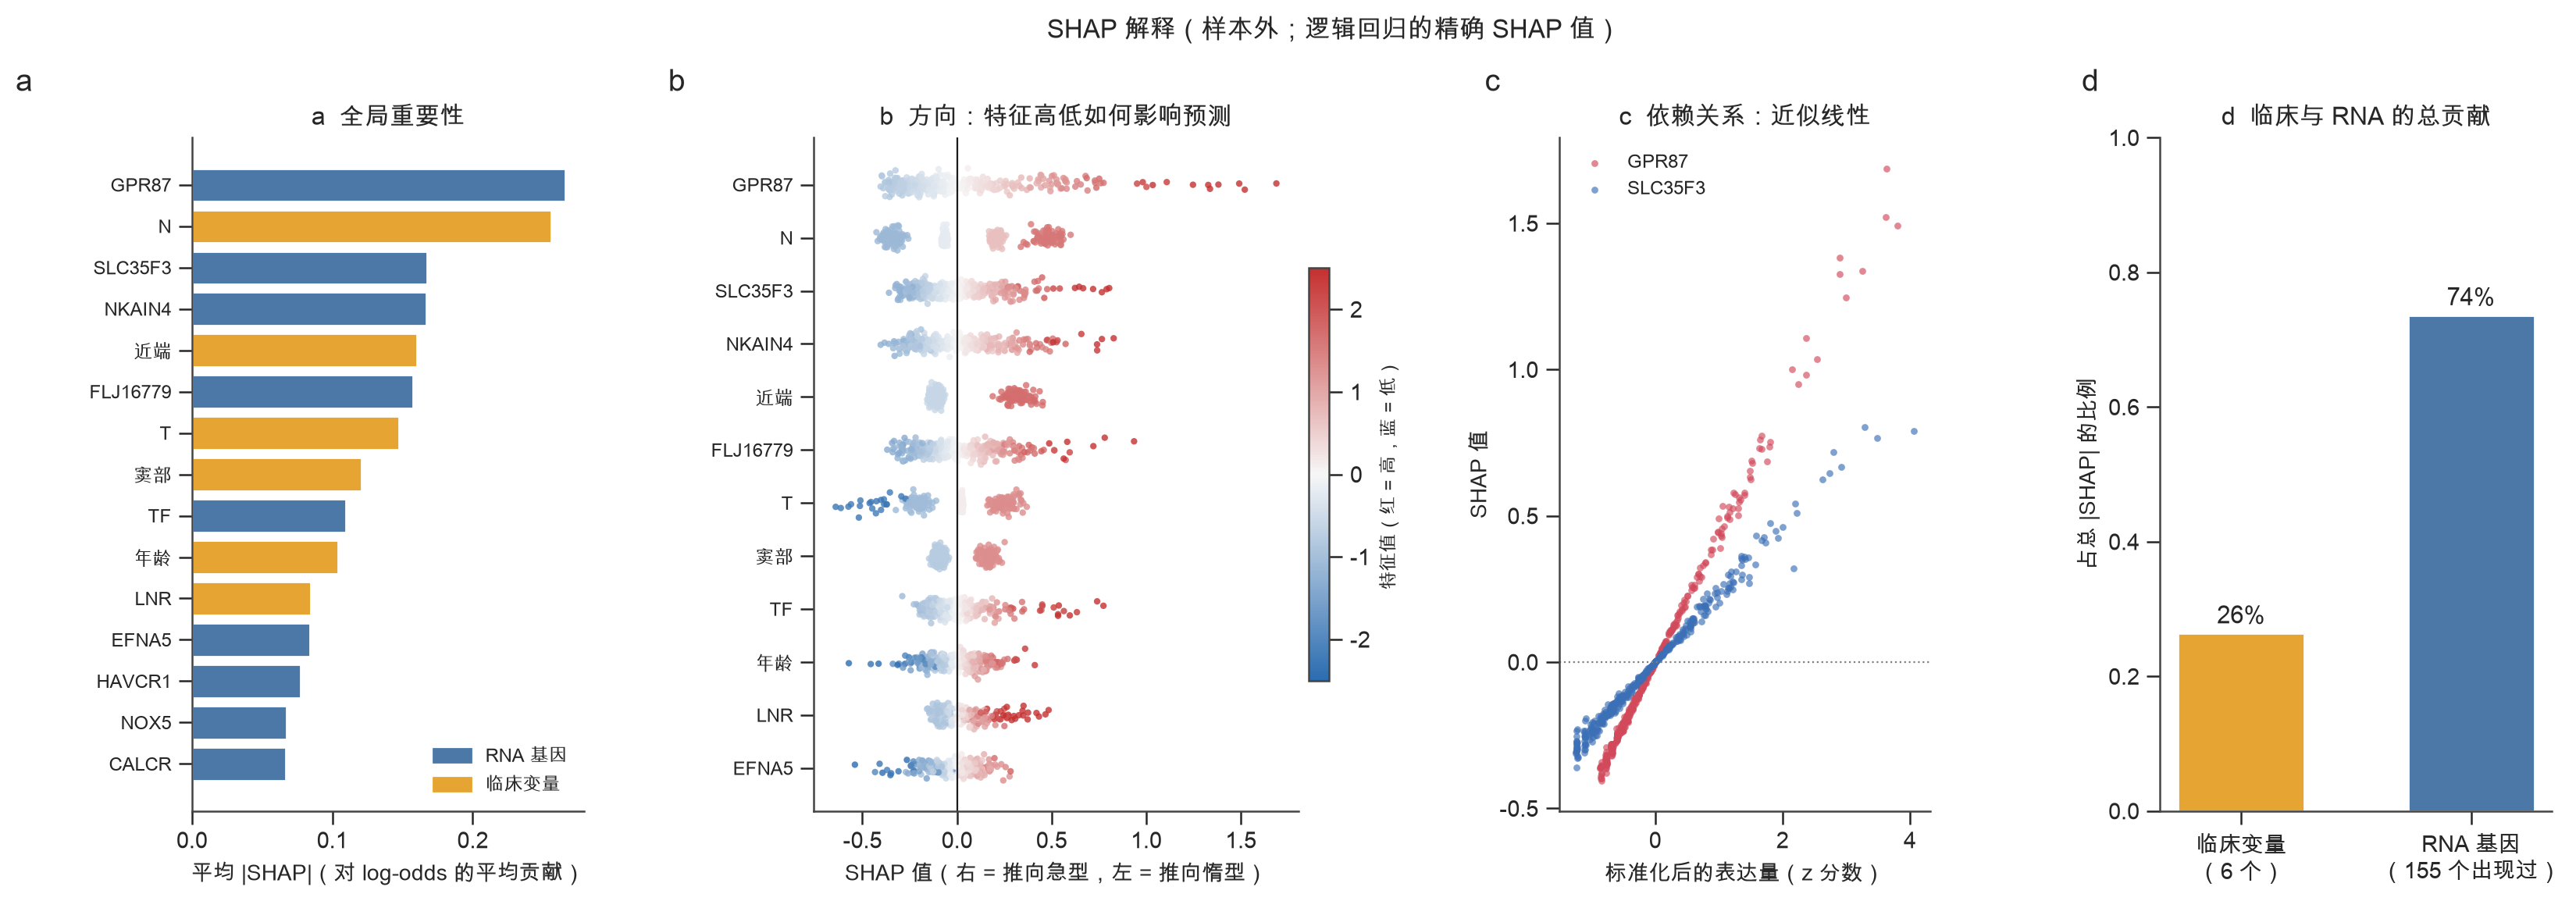

In [32]:
def _lab(n): return n if (n[0].isalpha() or n in CLIN_NAMES) else f"({n})"
_ZH = {"Age": "年龄", "Proximal": "近端", "Antrum": "窦部"}
def _disp(n): return _ZH.get(n, _lab(n))
fig = plt.figure(figsize=(19.5, 5.6))
gs_ = fig.add_gridspec(1, 4, width_ratios=[0.95, 1.25, 0.9, 0.95], wspace=0.55)
# a. 全局重要性
ax = fig.add_subplot(gs_[0])
top = imp.head(15).iloc[::-1]
ax.barh(range(len(top)), top.values, color=["#E6A532" if n in CLIN_NAMES else "#4C78A8" for n in top.index], edgecolor="white")
ax.set_yticks(range(len(top))); ax.set_yticklabels([_disp(n) for n in top.index], fontsize=8.5)
ax.legend(handles=[Patch(color="#4C78A8", label="RNA 基因"), Patch(color="#E6A532", label="临床变量")], loc="lower right", fontsize=8.5)
ax.set(xlabel="平均 |SHAP|（对 log-odds 的平均贡献）", title="a  全局重要性"); panel_label(ax, "a", -0.45)
# b. 蜂群图
ax = fig.add_subplot(gs_[1])
order = imp.head(12).index[::-1]
rng_ = np.random.default_rng(SEED)
for yi, n in enumerate(order):
    j = int(np.where(feat_names == n)[0][0]); s_ = SHAP_V[:, j]; z_ = TEST_Z[:, j]
    keep = np.abs(z_) > 0
    jit = rng_.normal(0, 0.09, len(s_))
    ax.scatter(s_[keep], yi + jit[keep], c=np.clip(z_[keep], -2.5, 2.5), cmap=DIV_CMAP, vmin=-2.5, vmax=2.5, s=9, alpha=0.8, linewidths=0)
ax.axvline(0, c="k", lw=0.8); ax.set_yticks(range(len(order))); ax.set_yticklabels([_disp(n) for n in order], fontsize=8.5)
sm = plt.cm.ScalarMappable(cmap=DIV_CMAP, norm=plt.Normalize(-2.5, 2.5)); cb = fig.colorbar(sm, ax=ax, fraction=0.04, pad=0.02); cb.set_label("特征值（红 = 高，蓝 = 低）", fontsize=8.5)
ax.set(xlabel="SHAP 值（右 = 推向急型，左 = 推向惰型）", title="b  方向：特征高低如何影响预测"); panel_label(ax, "b", -0.3)
# c. 依赖图：最重要的 RNA 基因
rna_top = [n for n in imp.index if n not in CLIN_NAMES][:2]
ax = fig.add_subplot(gs_[2])
for k_, n in enumerate(rna_top):
    j = int(np.where(feat_names == n)[0][0]); keep = np.abs(TEST_Z[:, j]) > 0
    ax.scatter(TEST_Z[keep, j], SHAP_V[keep, j], s=10, alpha=0.65, c=["#D1495B", "#3B6FB6"][k_], label=_lab(n), linewidths=0)
ax.axhline(0, c="grey", lw=0.8, ls=":"); ax.legend(fontsize=8.5)
ax.set(xlabel="标准化后的表达量（z 分数）", ylabel="SHAP 值", title="c  依赖关系：近似线性"); panel_label(ax, "c", -0.2)
# d. 临床 vs RNA 的总贡献
ax = fig.add_subplot(gs_[3])
ax.bar(["临床变量\n（6 个）", f"RNA 基因\n（{int((~is_clin & (np.abs(SHAP_V).sum(0) > 0)).sum())} 个出现过）"], [SH_CLIN, SH_RNA], color=["#E6A532", "#4C78A8"], edgecolor="white", width=0.55)
for i_, v_ in enumerate([SH_CLIN, SH_RNA]): ax.text(i_, v_ + 0.015, f"{v_:.0%}", ha="center", fontweight="bold", fontsize=11)
ax.set(ylabel="占总 |SHAP| 的比例", title="d  临床与 RNA 的总贡献", ylim=(0, 1)); panel_label(ax, "d", -0.2)
fig.suptitle("SHAP 解释（样本外；逻辑回归的精确 SHAP 值）", fontsize=12, fontweight="bold", y=1.02)
savefig(fig, "D2_SHAP")

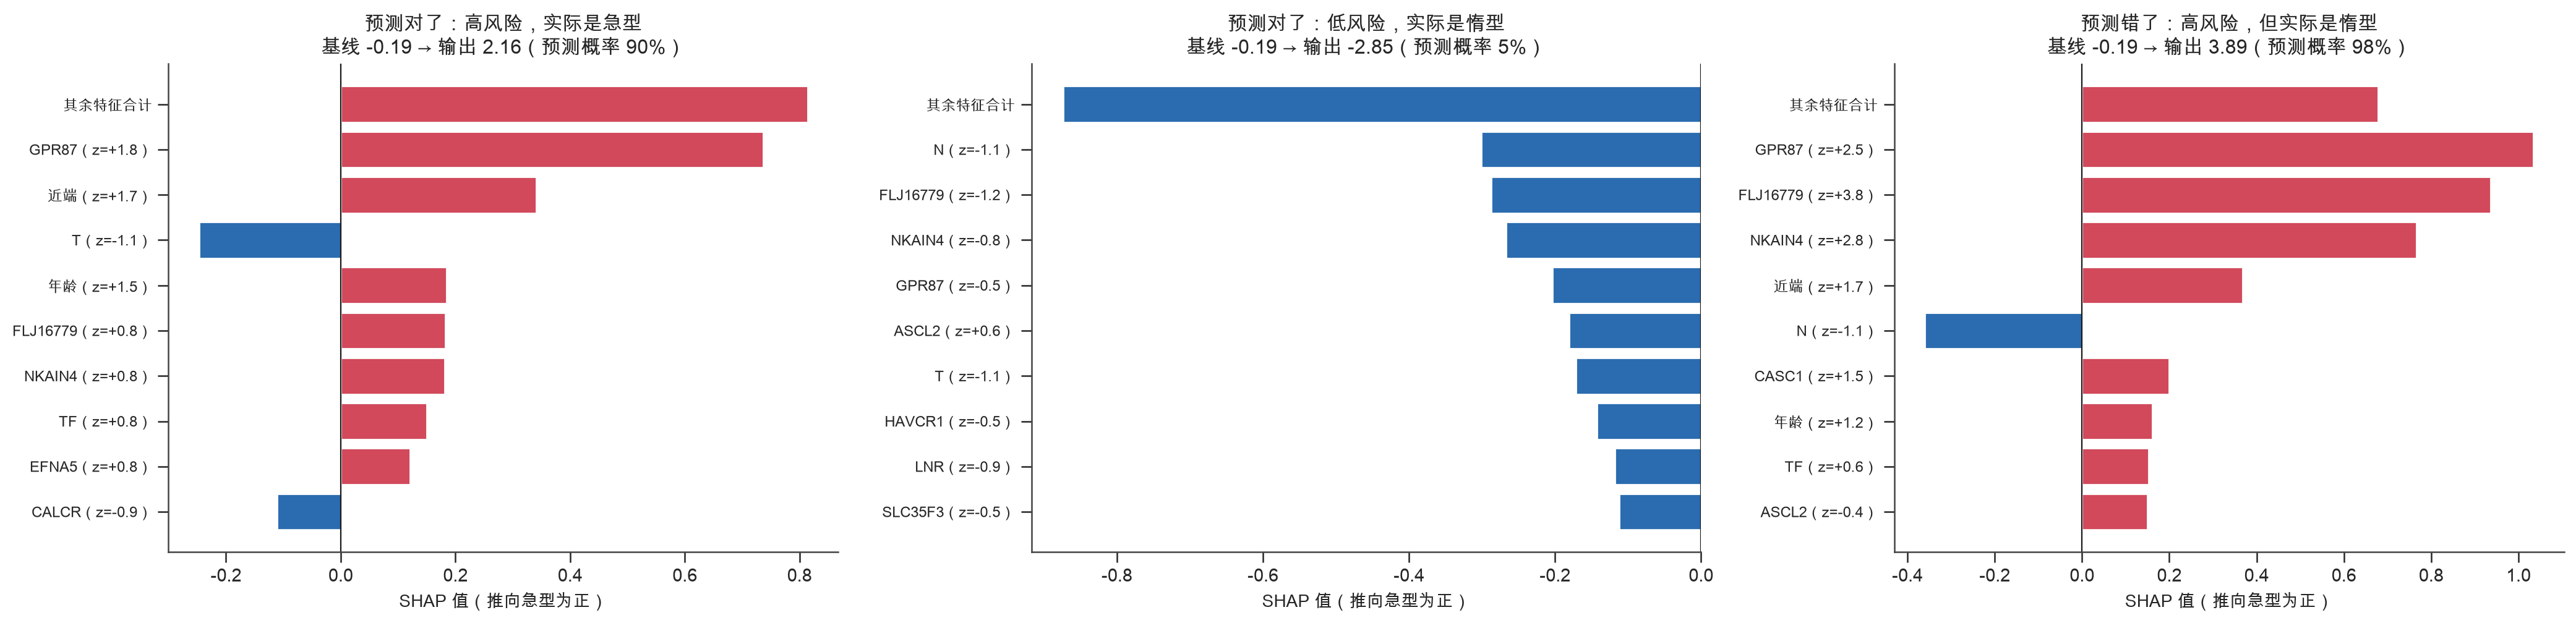

In [33]:
# 单个病人的"瀑布图"：三类代表——预测对的高风险、预测对的低风险、以及预测错的高风险（如实展示模型会出错）
P_show = pd.Series(P_r, index=ids_rna); lab_ = pd.Series(y_r, index=ids_rna)
ok_ = pd.Series(c_r, index=ids_rna)
case_hi = P_show[ok_ & (lab_ == 1)].idxmax()            # 高风险且真的是急型
case_lo = P_show[ok_ & (lab_ == 0)].idxmin()            # 低风险且真的是惰型
case_bad = P_show[ok_ & (lab_ == 0)].idxmax()           # 预测最高风险但实际是惰型（错得最离谱）
CASES = [(case_hi, "预测对了：高风险，实际是急型"), (case_lo, "预测对了：低风险，实际是惰型"), (case_bad, "预测错了：高风险，但实际是惰型")]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.2))
for ax, (case, ttl) in zip(axes, CASES):
    i = ids_rna.index(case); sv_i = SHAP_V[i]
    order_i = np.argsort(-np.abs(sv_i))[:9][::-1]; rest = sv_i.sum() - sv_i[order_i].sum()
    vals = list(sv_i[order_i]) + [rest]; labs = [f"{_disp(feat_names[k])}（z={TEST_Z[i, k]:+.1f}）" for k in order_i] + ["其余特征合计"]
    ax.barh(range(len(vals)), vals, color=["#D1495B" if v > 0 else "#2B6CB0" for v in vals], edgecolor="white")
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(labs, fontsize=8.5); ax.axvline(0, c="k", lw=0.8)
    base = np.mean(EXP_VAL); out = base + sv_i.sum()
    ax.set(xlabel="SHAP 值（推向急型为正）", title=f"{ttl}\n基线 {base:.2f} → 输出 {out:.2f}（预测概率 {1/(1+np.exp(-out)):.0%}）")
fig.tight_layout(); savefig(fig, "D3_SHAP_cases")
_ib = ids_rna.index(case_bad); _bad_prob = float(1 / (1 + np.exp(-(np.mean(EXP_VAL) + SHAP_V[_ib].sum()))))      # 与图中标题同一算法

In [34]:
_top_rna = [n for n in imp.index if n not in CLIN_NAMES][:5]
_top_clin = [n for n in imp.index if n in CLIN_NAMES][:3]
md(f"""### D4 结论：SHAP 解释

**怎么算的** 对 {_N_REP} 次 × 5 折共 {len(_jobs)} 个折内模型，只对"该模型没见过的病人"计算精确的线性 SHAP 值，把每折没入选的特征记 0 后取平均。

**临床 vs RNA 的总贡献** 6 个临床变量占总 |SHAP| 的 **{SH_CLIN:.0%}**，RNA 基因合计 **{SH_RNA:.0%}**（共 {int((~is_clin & (np.abs(SHAP_V).sum(0) > 0)).sum())} 个基因在至少一折里被选中）。平均每个临床变量的贡献 = {SH_CLIN/6:.1%}，每个入选基因的平均贡献 = {SH_RNA/max(int((~is_clin & (np.abs(SHAP_V).sum(0) > 0)).sum()),1):.2%}：**单个临床变量的作用比单个基因大得多，但基因数量多，合起来占多数。**

**最重要的特征** RNA：{', '.join(_lab(n) for n in _top_rna)}；临床：{', '.join(_disp(n) for n in _top_clin)}。

**方向与形状** 蜂群图（b）里排在前面的基因都是"表达越高越推向急型"（红点在右）；依赖图（c）显示 SHAP 值随表达量近似线性上升——这是线性模型的预期，不代表真实的生物学剂量反应一定是线性的。

**与 D1 的一致性** SHAP 重要性与"入选频率"的 Spearman 相关 = {rho.correlation:.2f}（p = {rho.pvalue:.2g}）：{'两种稳定性度量互相印证' if rho.correlation > 0.5 else '一致性一般，需谨慎解读'}。

**单个患者**（D3 图）：预测对的高风险患者主要由几个高表达的基因（如 GPR87、FLJ16779、NKAIN4）推高；预测对的低风险患者由这些基因的低表达和较轻的临床指标压低。第三张是**预测错了**的例子（预测概率 {_bad_prob:.0%}，实际是惰型）：同样几个基因的高表达把预测推高了，但这个患者实际并没有急型进展——这类错误在 AUC 约 0.68 的模型里必然存在。**这是对模型的解释，不是对该患者生物学的解释。**

**限制** SHAP 只回答"模型用了什么"；基因间相关会让贡献在相关基因之间被任意分摊；样本外 AUC 只有约 0.68，所以单个患者的解释也同样不确定。
""")

### D4 结论：SHAP 解释

**怎么算的** 对 10 次 × 5 折共 50 个折内模型，只对"该模型没见过的病人"计算精确的线性 SHAP 值，把每折没入选的特征记 0 后取平均。

**临床 vs RNA 的总贡献** 6 个临床变量占总 |SHAP| 的 **26%**，RNA 基因合计 **74%**（共 155 个基因在至少一折里被选中）。平均每个临床变量的贡献 = 4.4%，每个入选基因的平均贡献 = 0.47%：**单个临床变量的作用比单个基因大得多，但基因数量多，合起来占多数。**

**最重要的特征** RNA：GPR87, SLC35F3, NKAIN4, FLJ16779, TF；临床：N, 近端, T。

**方向与形状** 蜂群图（b）里排在前面的基因都是"表达越高越推向急型"（红点在右）；依赖图（c）显示 SHAP 值随表达量近似线性上升——这是线性模型的预期，不代表真实的生物学剂量反应一定是线性的。

**与 D1 的一致性** SHAP 重要性与"入选频率"的 Spearman 相关 = 0.80（p = 7.8e-44）：两种稳定性度量互相印证。

**单个患者**（D3 图）：预测对的高风险患者主要由几个高表达的基因（如 GPR87、FLJ16779、NKAIN4）推高；预测对的低风险患者由这些基因的低表达和较轻的临床指标压低。第三张是**预测错了**的例子（预测概率 98%，实际是惰型）：同样几个基因的高表达把预测推高了，但这个患者实际并没有急型进展——这类错误在 AUC 约 0.68 的模型里必然存在。**这是对模型的解释，不是对该患者生物学的解释。**

**限制** SHAP 只回答"模型用了什么"；基因间相关会让贡献在相关基因之间被任意分摊；样本外 AUC 只有约 0.68，所以单个患者的解释也同样不确定。


---
# 阶段 E：机制（简要）——这些基因在做什么

只做三件事，避免过度解读：
1. **用同一患者的癌旁正常组织做检验**：风险基因是在肿瘤里真的改变了，还是只是组织本来就表达（上一版被指出的问题）。
2. **通路富集**（Enrichr，MSigDB Hallmark）。
3. **看基因对应的生物学过程是否与"急型进展"在医学上说得通**；全部为相关性，不说因果。

## E1 风险基因在肿瘤里是否真的改变（配对：肿瘤 − 同一患者癌旁正常）

配对患者 32 例（肿瘤-01 与癌旁正常-11 同一患者）


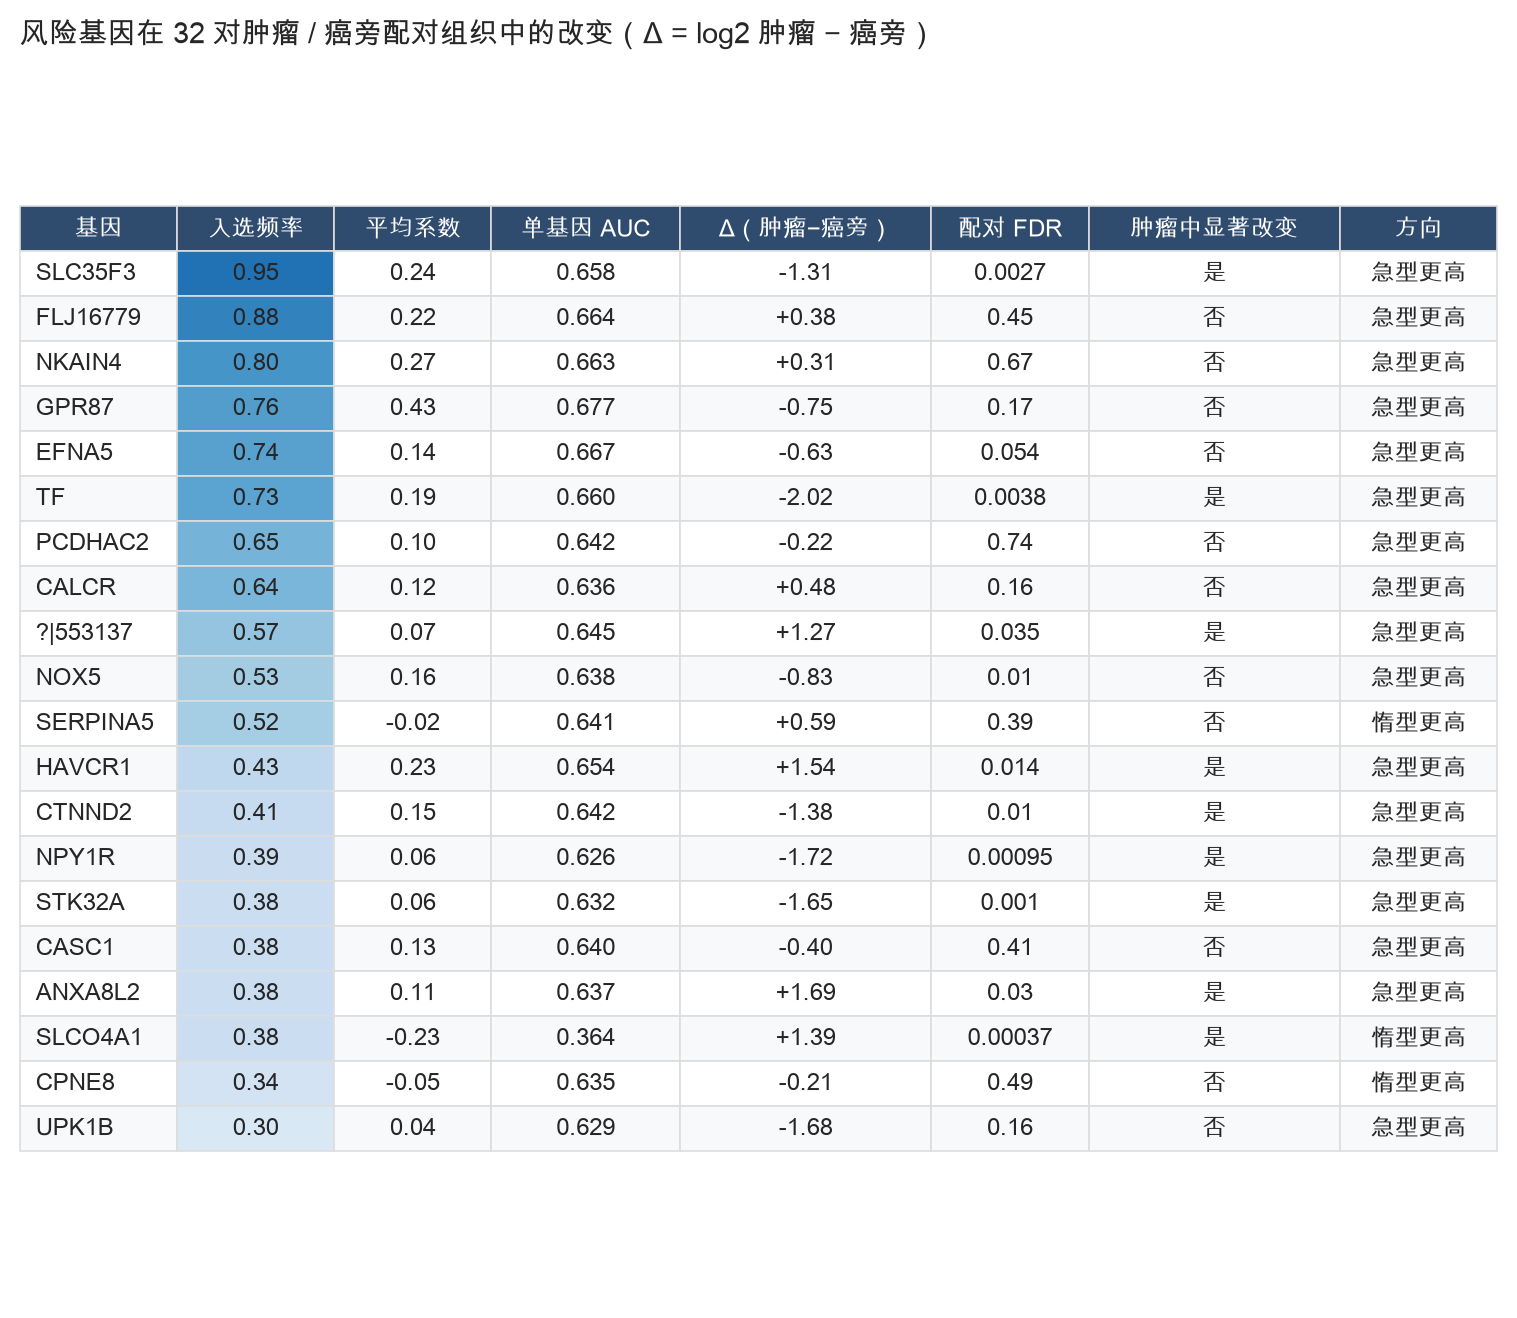

20 个风险基因中 9 个在肿瘤里显著改变（FDR<0.05 且 |Δ|>1）= 45%；全部基因的背景比例 17%；二项检验 p = 0.0031
方向分布（改变的风险基因里）: {'high in fast': 8, 'high in slow': 1}


In [35]:
Efull = pd.read_csv(DATA / "TCGA.STAD.sampleMap_HiSeqV2", sep="\t", index_col=0).astype(np.float32)
norm_cols = [c for c in Efull.columns if c.endswith("-11")]
PAIR = [(n_[:12] + "-01", n_) for n_ in norm_cols if (n_[:12] + "-01") in Efull.columns]
print(f"配对患者 {len(PAIR)} 例（肿瘤-01 与癌旁正常-11 同一患者）")
dpair = Efull[[t_ for t_, _ in PAIR]].values - Efull[[n_ for _, n_ in PAIR]].values
DELTA = pd.DataFrame({"delta": dpair.mean(1), "p": stats.ttest_1samp(dpair, 0, axis=1).pvalue}, index=Efull.index).dropna()
DELTA["FDR"] = multipletests(DELTA.p, method="fdr_bh")[1]
cand = STAB_G[STAB_G.freq >= 0.3].copy()
cand["delta_tumour_minus_normal"] = DELTA.reindex(cand.index)["delta"]; cand["FDR_paired"] = DELTA.reindex(cand.index)["FDR"]
cand["changed_in_tumour"] = (cand.FDR_paired < 0.05) & (cand.delta_tumour_minus_normal.abs() > 1)
cand["pattern"] = np.where(cand.mean_coef > 0, "high in fast", "high in slow")
n_c = len(cand); n_chg = int(cand.changed_in_tumour.sum())
# 对照：在全部可检测基因中，肿瘤-正常显著改变（|Δ|>1, FDR<0.05）的比例
bg = ((DELTA.FDR < .05) & (DELTA.delta.abs() > 1)).mean()
p_enr = stats.binomtest(n_chg, n_c, bg, alternative="greater").pvalue if n_c else np.nan
_cz = cand.head(20)[["freq", "mean_coef", "AUC_single", "delta_tumour_minus_normal", "FDR_paired", "changed_in_tumour", "pattern"]].copy()
_cz["pattern"] = _cz["pattern"].map({"high in fast": "急型更高", "high in slow": "惰型更高"}); _cz["changed_in_tumour"] = _cz["changed_in_tumour"].map({True: "是", False: "否"})
_cz = _cz.rename(columns={"freq": "入选频率", "mean_coef": "平均系数", "AUC_single": "单基因 AUC", "delta_tumour_minus_normal": "Δ（肿瘤−癌旁）", "FDR_paired": "配对 FDR", "changed_in_tumour": "肿瘤中显著改变", "pattern": "方向"}).rename_axis("基因")
show_table(_cz, "T_E1_risk_genes_paired", f"风险基因在 {len(PAIR)} 对肿瘤 / 癌旁配对组织中的改变（Δ = log2 肿瘤 − 癌旁）", fmt={"入选频率": "{:.2f}", "平均系数": "{:.2f}", "单基因 AUC": "{:.3f}", "Δ（肿瘤−癌旁）": "{:+.2f}", "配对 FDR": "{:.2g}"}, hl=["入选频率"])
print(f"{n_c} 个风险基因中 {n_chg} 个在肿瘤里显著改变（FDR<0.05 且 |Δ|>1）= {n_chg/max(n_c,1):.0%}；全部基因的背景比例 {bg:.0%}；二项检验 p = {p_enr:.2g}")
sub_dir = cand[cand.changed_in_tumour].groupby("pattern").size().to_dict()
print("方向分布（改变的风险基因里）:", sub_dir)

## E2 通路富集

In [36]:
import gseapy as gp
HALL_ZH = {"Estrogen Response Early": "雌激素应答（早期）", "Estrogen Response Late": "雌激素应答（晚期）", "Angiogenesis": "血管生成", "Apical Surface": "顶端表面",
           "Apical Junction": "顶端连接", "Epithelial Mesenchymal Transition": "上皮-间质转化", "Inflammatory Response": "炎症反应", "KRAS Signaling Up": "KRAS 信号上调",
           "KRAS Signaling Dn": "KRAS 信号下调", "E2F Targets": "E2F 靶基因", "G2-M Checkpoint": "G2-M 检查点", "Mitotic Spindle": "有丝分裂纺锤体",
           "Myogenesis": "肌生成", "Hypoxia": "缺氧", "TNF-alpha Signaling via NF-kB": "TNF-α/NF-κB 信号", "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 信号",
           "Interferon Gamma Response": "干扰素 γ 应答", "Interferon Alpha Response": "干扰素 α 应答", "Complement": "补体", "Coagulation": "凝血",
           "Xenobiotic Metabolism": "外源物代谢", "Fatty Acid Metabolism": "脂肪酸代谢", "Bile Acid Metabolism": "胆汁酸代谢", "Glycolysis": "糖酵解",
           "P53 Pathway": "p53 通路", "Apoptosis": "细胞凋亡", "UV Response Dn": "紫外应答下调", "UV Response Up": "紫外应答上调", "Allograft Rejection": "同种异体排斥",
           "IL-2/STAT5 Signaling": "IL-2/STAT5 信号", "Pancreas Beta Cells": "胰岛 β 细胞", "Cholesterol Homeostasis": "胆固醇稳态", "Oxidative Phosphorylation": "氧化磷酸化",
           "mTORC1 Signaling": "mTORC1 信号", "MYC Targets V1": "MYC 靶基因 V1", "MYC Targets V2": "MYC 靶基因 V2", "Androgen Response": "雄激素应答", "Adipogenesis": "脂肪生成",
           "Spermatogenesis": "精子发生", "Peroxisome": "过氧化物酶体", "Heme Metabolism": "血红素代谢", "TGF-beta Signaling": "TGF-β 信号", "Wnt-beta Catenin Signaling": "Wnt/β-catenin 信号",
           "Notch Signaling": "Notch 信号", "Hedgehog Signaling": "Hedgehog 信号", "PI3K/AKT/mTOR  Signaling": "PI3K/AKT/mTOR 信号", "Unfolded Protein Response": "未折叠蛋白应答",
           "Reactive Oxygen Species Pathway": "活性氧通路", "DNA Repair": "DNA 修复", "Protein Secretion": "蛋白分泌", "Pperoxisome": "过氧化物酶体"}
def clean_term(t):
    t = re.sub(r"\s*\(GO:\d+\)", "", t); t = re.sub(r"^HALLMARK_", "", t); t = t.replace("_", " ")
    return HALL_ZH.get(t, t)
CACHE_E = CACHE / "enrichr_risk.pkl"
ENR = {}
sets_ = {"UP in fast (higher in fast class)": STAB_G[(STAB_G.freq >= 0.2) & (STAB_G.mean_coef > 0)].index.tolist(),
         "UP in slow (higher in slow class)": STAB_G[(STAB_G.freq >= 0.2) & (STAB_G.mean_coef < 0)].index.tolist()}
if CACHE_E.exists():
    ENR = pickle.load(open(CACHE_E, "rb"))
else:
    ok_ = True
    for nm, gl in sets_.items():
        if len(gl) < 5: continue
        try: ENR[nm] = gp.enrichr(gene_list=gl, gene_sets="MSigDB_Hallmark_2020", organism="human", outdir=None).results[["Term", "Overlap", "Adjusted P-value", "Genes"]]
        except Exception as ex: ok_ = False; print("Enrichr 失败", nm, type(ex).__name__)
    if ok_ and ENR: pickle.dump(ENR, open(CACHE_E, "wb"))
for nm, gl in sets_.items(): print(f"{nm}: {len(gl)} 个基因（频率 ≥ 0.2）")
for nm, r_ in ENR.items():
    t_ = r_[r_["Adjusted P-value"] < .1].head(5)
    print(f"[{nm}]", "; ".join(f"{clean_term(a)} ({b:.1e})" for a, b in zip(t_.Term, t_["Adjusted P-value"])) or "无显著富集")

UP in fast (higher in fast class): 20 个基因（频率 ≥ 0.2）
UP in slow (higher in slow class): 9 个基因（频率 ≥ 0.2）
[UP in fast (higher in fast class)] 雌激素应答（早期） (6.7e-02); 雌激素应答（晚期） (6.7e-02); 血管生成 (8.6e-02); 顶端表面 (8.6e-02)
[UP in slow (higher in slow class)] 血管生成 (4.8e-02); 顶端连接 (8.6e-02); 雌激素应答（晚期） (8.6e-02)


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


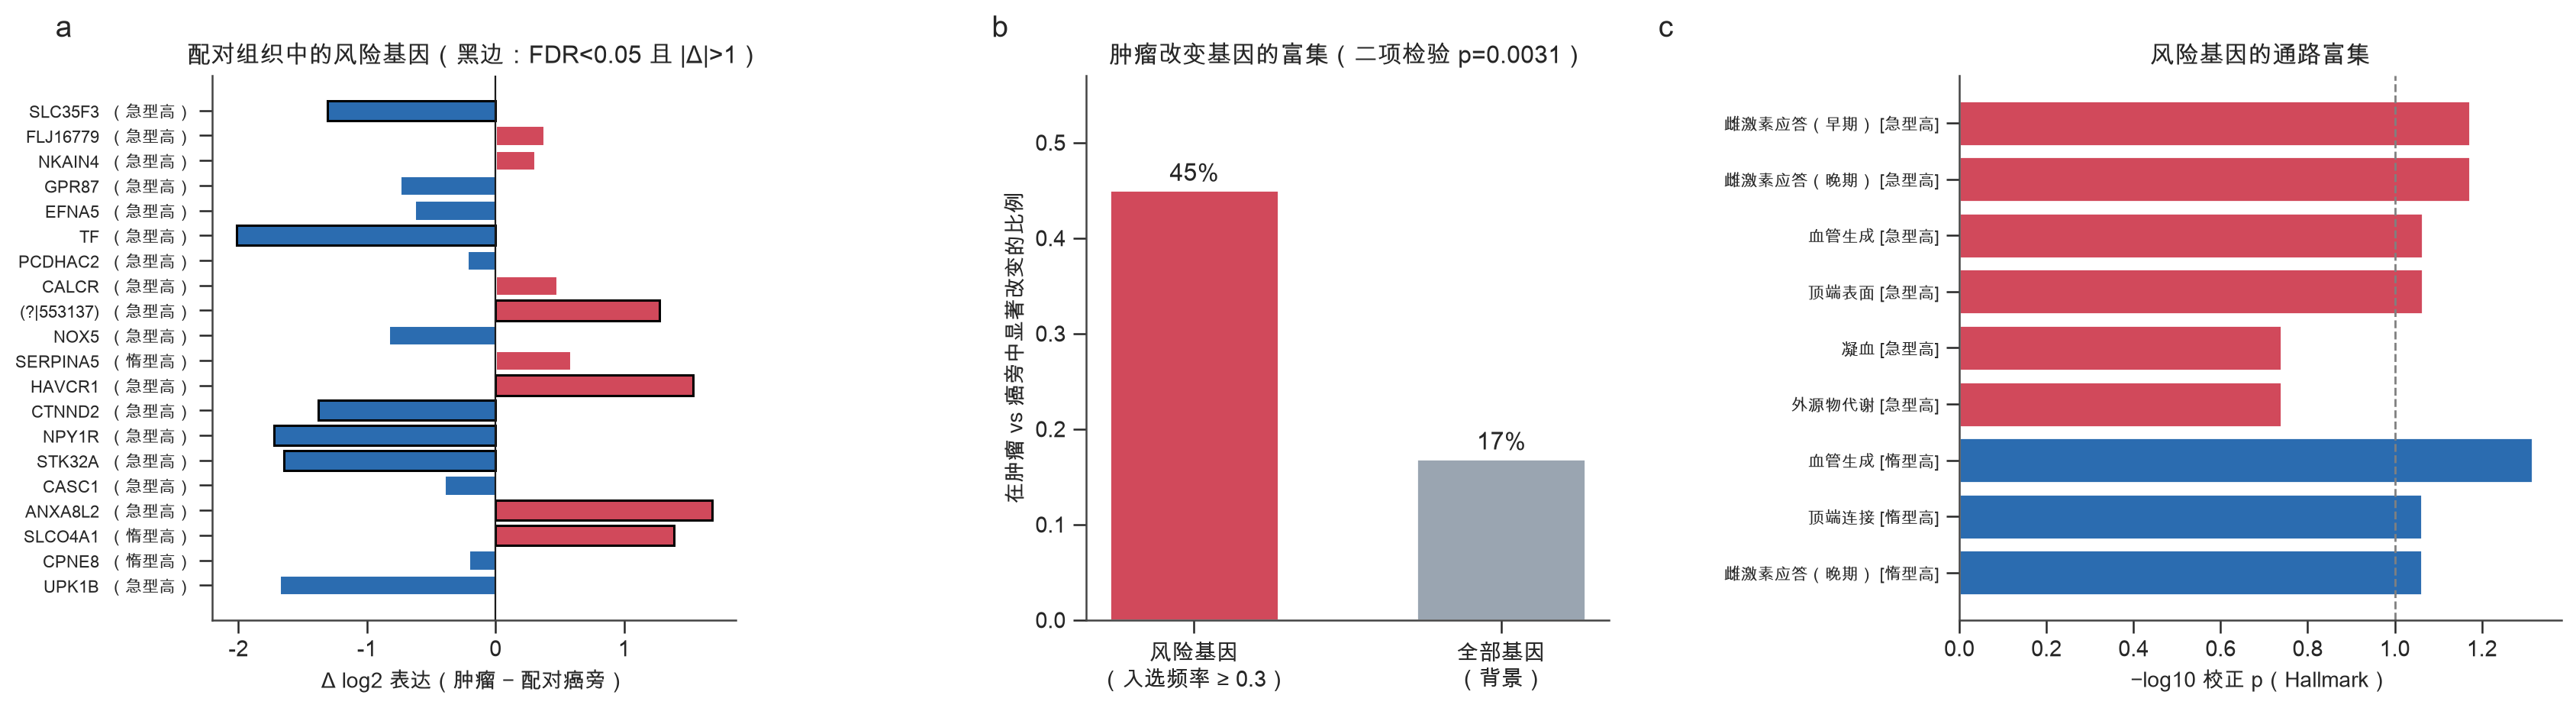

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1.0, 1.0, 1.15]))
ax = axes[0]
cc_ = cand.head(24).iloc[::-1]
ax.barh(range(len(cc_)), cc_.delta_tumour_minus_normal, color=["#D1495B" if v > 0 else "#2B6CB0" for v in cc_.delta_tumour_minus_normal], edgecolor=["black" if c else "white" for c in cc_.changed_in_tumour], lw=1.1)
ax.set_yticks(range(len(cc_))); ax.set_yticklabels([f"{g if g[0].isalpha() else '('+g+')'}  （{ {'high in fast': '急型高', 'high in slow': '惰型高'}[p] }）" for g, p in zip(cc_.index, cc_.pattern)], fontsize=8)
ax.axvline(0, c="k", lw=0.8); ax.set(xlabel="Δ log2 表达（肿瘤 − 配对癌旁）", title="配对组织中的风险基因（黑边：FDR<0.05 且 |Δ|>1）"); panel_label(ax, "a", -0.3)
ax = axes[1]
vals_ = [n_chg / max(n_c, 1), bg]
ax.bar(["风险基因\n（入选频率 ≥ 0.3）", "全部基因\n（背景）"], vals_, color=["#D1495B", "#9AA5B1"], edgecolor="white", width=0.55)
for i_, v_ in enumerate(vals_): ax.text(i_, v_ + 0.01, f"{v_:.0%}", ha="center", fontweight="bold")
ax.set(ylabel="在肿瘤 vs 癌旁中显著改变的比例", title=f"肿瘤改变基因的富集（二项检验 p={p_enr:.2g}）"); ax.set_ylim(0, max(vals_) + 0.12); panel_label(ax, "b", -0.18)
ax = axes[2]
rows_ = []
for nm, r_ in ENR.items():
    for _, rr in r_.head(6).iterrows(): rows_.append(("急型高" if nm.startswith("UP in fast") else "惰型高", clean_term(rr.Term), -np.log10(max(rr["Adjusted P-value"], 1e-30))))
if rows_:
    dd_ = pd.DataFrame(rows_, columns=["set", "term", "nlogp"]).iloc[::-1]
    ax.barh(range(len(dd_)), dd_.nlogp, color=["#D1495B" if s == "急型高" else "#2B6CB0" for s in dd_.set], edgecolor="white")
    ax.set_yticks(range(len(dd_))); ax.set_yticklabels([f"{t_} [{s}]" for t_, s in zip(dd_.term, dd_.set)], fontsize=7.8)
    ax.axvline(-np.log10(0.1), ls="--", c="grey", lw=1); ax.set(xlabel="−log10 校正 p（Hallmark）", title="风险基因的通路富集")
panel_label(ax, "c", -0.5)
fig.tight_layout(); savefig(fig, "E1_mechanism")

In [38]:
_en_txt = []
for nm, r_ in ENR.items():
    t_ = r_[r_["Adjusted P-value"] < .1].head(4)
    _en_txt.append(f"**{nm}**：" + ("；".join(f"{clean_term(a)}（FDR {b:.1e}）" for a, b in zip(t_.Term, t_["Adjusted P-value"])) if len(t_) else "无显著富集"))
_top_alt = cand[cand.changed_in_tumour].head(6)
md(f"""### 阶段 E 结论：机制（简要）

**肿瘤里真的改变了吗（E1）** 入选频率 ≥ 0.3 的 {n_c} 个风险基因里，{n_chg} 个在 {len(PAIR)} 对肿瘤–癌旁配对组织中显著改变（FDR < 0.05 且 |Δ| > 1），占 {n_chg/max(n_c,1):.0%}；全部基因的背景比例是 {bg:.0%}（二项检验 p = {p_enr:.2g}）。{'改变幅度最大的包括：' + '、'.join(f"{g}（Δ={r.delta_tumour_minus_normal:+.1f}，{r.pattern}）" for g, r in _top_alt.iterrows()) + '。' if len(_top_alt) else ''}

**通路（E2）** {' '.join(_en_txt) if _en_txt else '（富集未能运行，需联网）'}

**读法与限制** ① 风险基因是预测模型反复选中的基因，与"急型进展"相关，**不证明它们驱动进展**；② 配对组织只有 {len(PAIR)} 对，用来回答"在肿瘤里是否真的改变"，不用于定义风险基因；③ 肿瘤与癌旁的细胞组成不同（间质、免疫细胞占比），EMT、炎症类通路的变化有一部分来自组成差异；④ 没有外部队列验证这些基因。
""")

### 阶段 E 结论：机制（简要）

**肿瘤里真的改变了吗（E1）** 入选频率 ≥ 0.3 的 20 个风险基因里，9 个在 32 对肿瘤–癌旁配对组织中显著改变（FDR < 0.05 且 |Δ| > 1），占 45%；全部基因的背景比例是 17%（二项检验 p = 0.0031）。改变幅度最大的包括：SLC35F3（Δ=-1.3，high in fast）、TF（Δ=-2.0，high in fast）、?|553137（Δ=+1.3，high in fast）、HAVCR1（Δ=+1.5，high in fast）、CTNND2（Δ=-1.4，high in fast）、NPY1R（Δ=-1.7，high in fast）。

**通路（E2）** **UP in fast (higher in fast class)**：雌激素应答（早期）（FDR 6.7e-02）；雌激素应答（晚期）（FDR 6.7e-02）；血管生成（FDR 8.6e-02）；顶端表面（FDR 8.6e-02） **UP in slow (higher in slow class)**：血管生成（FDR 4.8e-02）；顶端连接（FDR 8.6e-02）；雌激素应答（晚期）（FDR 8.6e-02）

**读法与限制** ① 风险基因是预测模型反复选中的基因，与"急型进展"相关，**不证明它们驱动进展**；② 配对组织只有 32 对，用来回答"在肿瘤里是否真的改变"，不用于定义风险基因；③ 肿瘤与癌旁的细胞组成不同（间质、免疫细胞占比），EMT、炎症类通路的变化有一部分来自组成差异；④ 没有外部队列验证这些基因。


---
# 总结

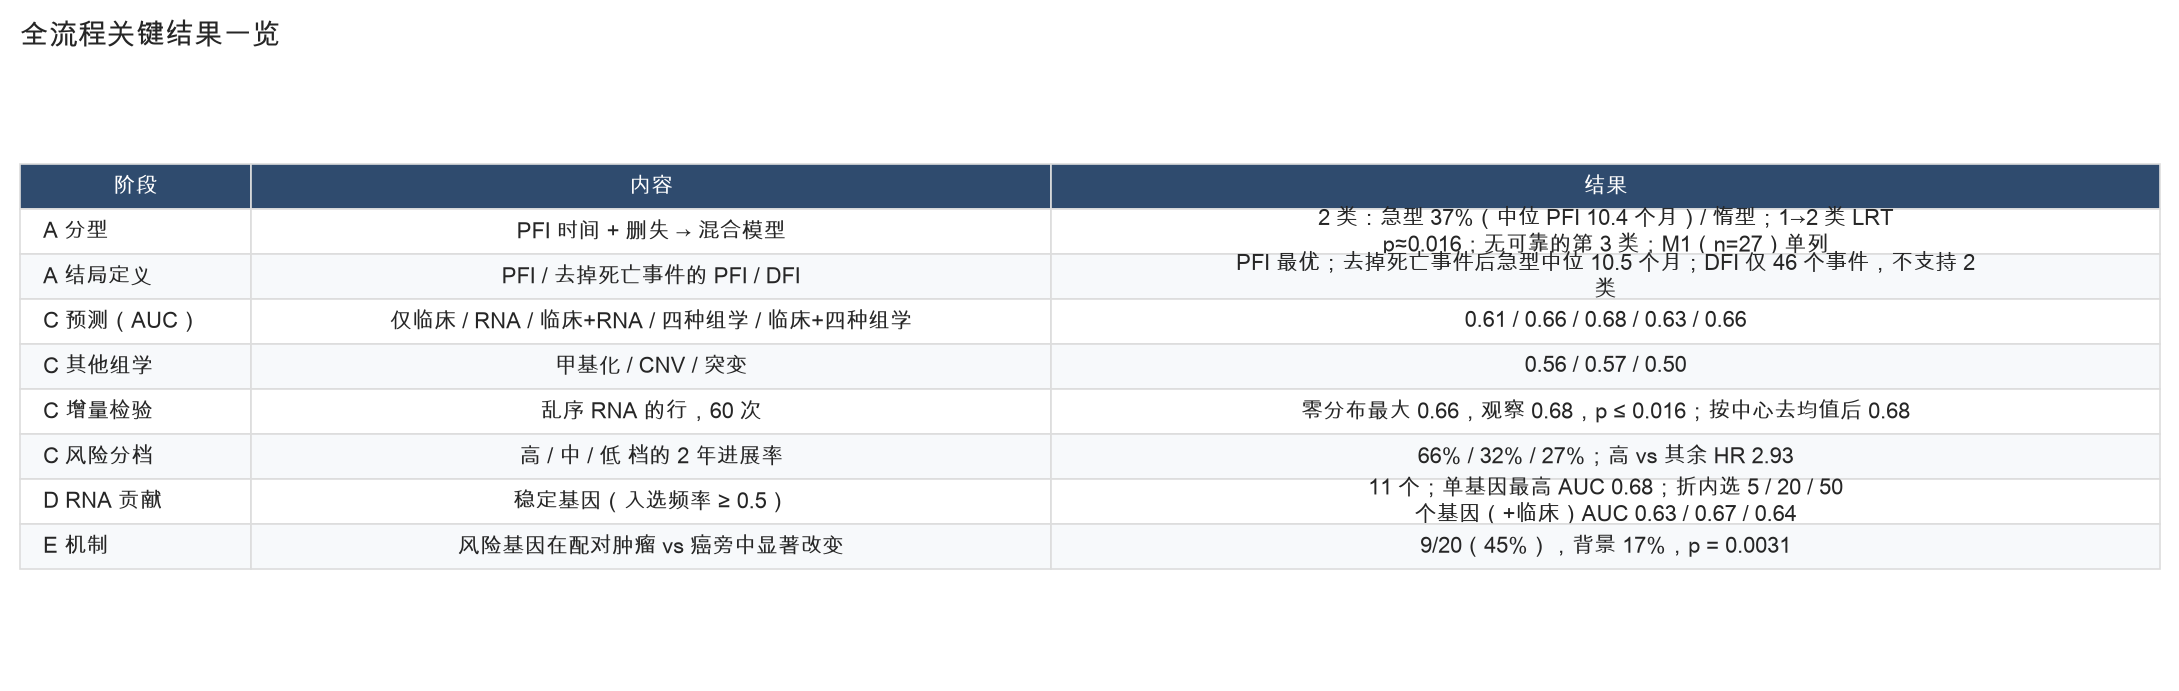

,内容,结果
阶段,,
A 分型,PFI 时间 + 删失 → 混合模型,2 类：急型 37%（中位 PFI 10.4 个月）/ 惰型；1→2 类 LRT p≈0.0...
A 结局定义,PFI / 去掉死亡事件的 PFI / DFI,PFI 最优；去掉死亡事件后急型中位 10.5 个月；DFI 仅 46 个事件，不支持 2 类
C 预测（AUC）,仅临床 / RNA / 临床+RNA / 四种组学 / 临床+四种组学,0.61 / 0.66 / 0.68 / 0.63 / 0.66
C 其他组学,甲基化 / CNV / 突变,0.56 / 0.57 / 0.50
C 增量检验,乱序 RNA 的行，60 次,零分布最大 0.66，观察 0.68，p ≤ 0.016；按中心去均值后 0.68
C 风险分档,高 / 中 / 低 档的 2 年进展率,66% / 32% / 27%；高 vs 其余 HR 2.93
D RNA 贡献,稳定基因（入选频率 ≥ 0.5）,11 个；单基因最高 AUC 0.68；折内选 5 / 20 / 50 个基因（+临床）AU...
E 机制,风险基因在配对肿瘤 vs 癌旁中显著改变,9/20（45%），背景 17%，p = 0.0031


In [39]:
_pf = lambda x: f"{x:.2f}"
tbl = pd.DataFrame([
    ("A 分型", "PFI 时间 + 删失 → 混合模型", f"2 类：急型 {FAST_SHARE:.0%}（中位 PFI {FAST_MED:.1f} 个月）/ 惰型；1→2 类 LRT p≈{_lrt12.p:.3f}；无可靠的第 3 类；M1（n={len(m1_ids)}）单列"),
    ("A 结局定义", "PFI / 去掉死亡事件的 PFI / DFI", f"PFI 最优；去掉死亡事件后急型中位 {A5.loc['PFI (deaths censored)','fast_median_months']:.1f} 个月；DFI 仅 {int(A5.loc['DFI','events'])} 个事件，不支持 2 类"),
    ("C 预测（AUC）", "仅临床 / RNA / 临床+RNA / 四种组学 / 临床+四种组学", f"{_ca:.2f} / {_ra:.2f} / {_cr:.2f} / {_all:.2f} / {_ca4:.2f}"),
    ("C 其他组学", "甲基化 / CNV / 突变", f"{C1.loc['Methylation','AUC']:.2f} / {C1.loc['CNV','AUC']:.2f} / {C1.loc['Mutation','AUC']:.2f}"),
    ("C 增量检验", "乱序 RNA 的行，60 次", f"零分布最大 {null.max():.2f}，观察 {a_r:.2f}，p ≤ {p_perm:.3f}；按中心去均值后 {a_dm:.2f}"),
    ("C 风险分档", "高 / 中 / 低 档的 2 年进展率", f"{C4.loc[('Clinical + RNA','High'),'PFI_2y']:.0%} / {C4.loc[('Clinical + RNA','Mid'),'PFI_2y']:.0%} / {C4.loc[('Clinical + RNA','Low'),'PFI_2y']:.0%}；高 vs 其余 HR {hr_hi.iloc[0]:.2f}"),
    ("D RNA 贡献", "稳定基因（入选频率 ≥ 0.5）", f"{n50} 个；单基因最高 AUC {STAB_G.AUC_single.max():.2f}；折内选 5 / 20 / 50 个基因（+临床）AUC {_a5:.2f} / {_a20:.2f} / {_a50:.2f}"),
    ("E 机制", "风险基因在配对肿瘤 vs 癌旁中显著改变", f"{n_chg}/{n_c}（{n_chg/max(n_c,1):.0%}），背景 {bg:.0%}，p = {p_enr:.2g}"),
], columns=["阶段", "内容", "结果"]).set_index("阶段")
show_table(tbl, "T_S1_summary_table", "全流程关键结果一览", wrap=46, fs=8)

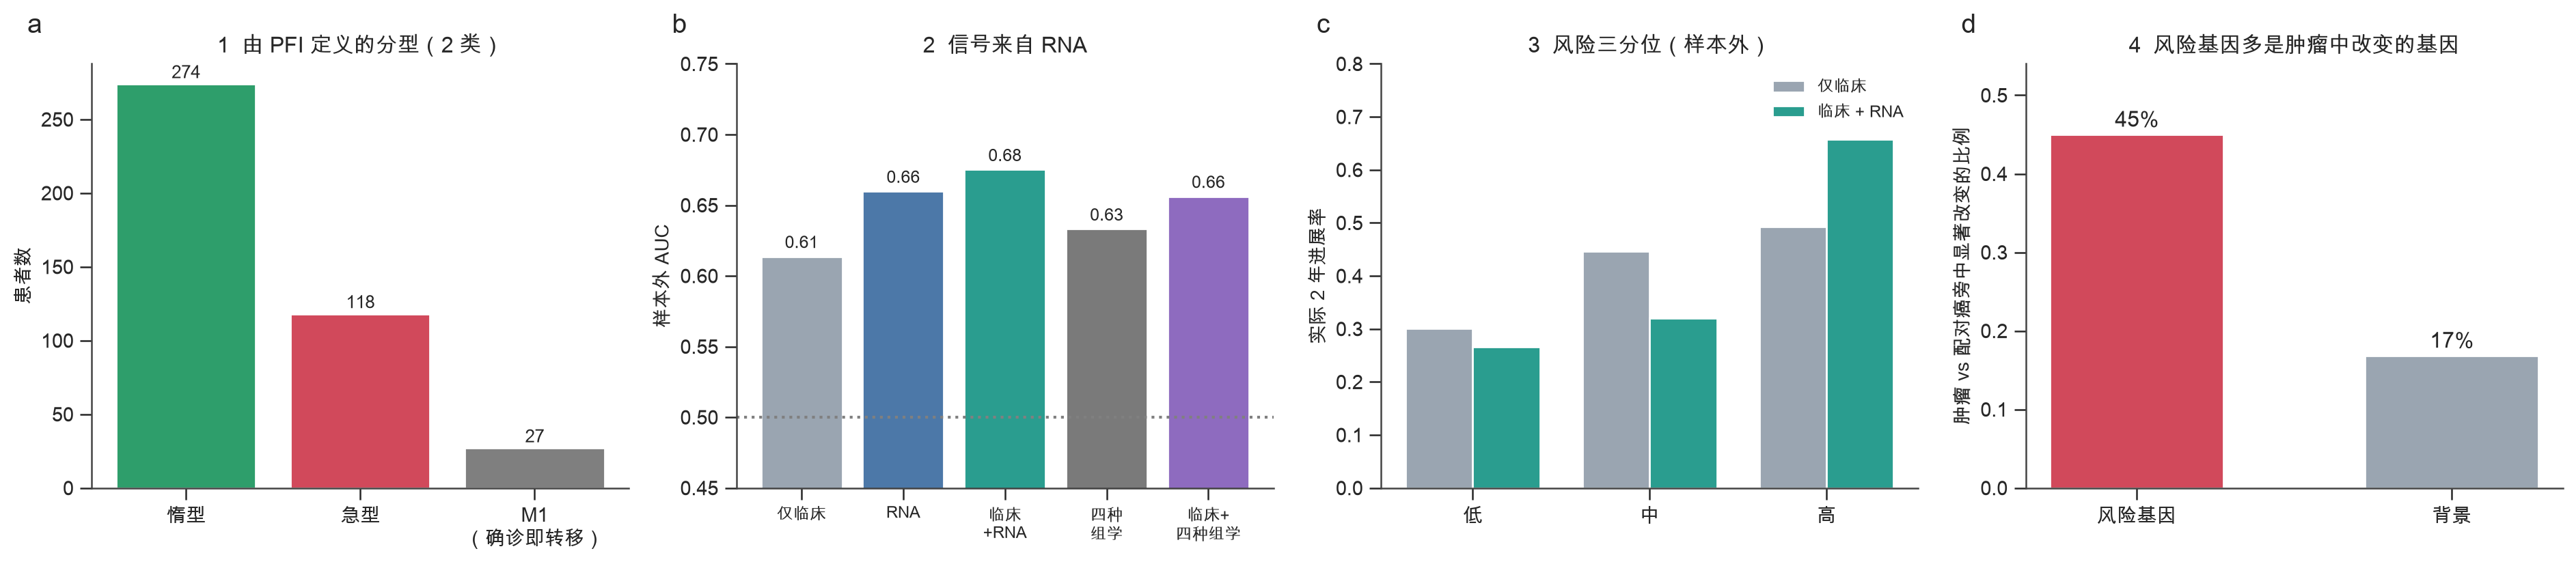

In [40]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
ax = axes[0]
ax.bar(["惰型", "急型", "M1\n（确诊即转移）"], [int((SUBTYPE == "Slow").sum()), int((SUBTYPE == "Fast").sum()), len(m1_ids)], color=["#2E9E6B", "#D1495B", "#7F7F7F"], edgecolor="white")
for i_, v_ in enumerate([int((SUBTYPE == "Slow").sum()), int((SUBTYPE == "Fast").sum()), len(m1_ids)]): ax.text(i_, v_ + 4, str(v_), ha="center", fontsize=9.5, fontweight="bold")
ax.set(ylabel="患者数", title="1  由 PFI 定义的分型（2 类）"); panel_label(ax, "a")
ax = axes[1]
nm_ = ["仅临床", "RNA", "临床\n+RNA", "四种\n组学", "临床+\n四种组学"]; v_ = [_ca, _ra, _cr, _all, _ca4]
ax.bar(range(5), v_, color=["#9AA5B1", MOD_COLORS["RNA"], "#2A9D8F", "#7A7A7A", "#8E6BBF"], edgecolor="white")
for i_, x_ in enumerate(v_): ax.text(i_, x_ + 0.006, f"{x_:.2f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(0.5, ls=":", c="grey"); ax.set_xticks(range(5)); ax.set_xticklabels(nm_, fontsize=8.5); ax.set_ylim(0.45, 0.75); ax.set(ylabel="样本外 AUC", title="2  信号来自 RNA"); panel_label(ax, "b")
ax = axes[2]
v1 = [C4.loc[("Clinical only", g), "PFI_2y"] for g in GR]; v2 = [C4.loc[("Clinical + RNA", g), "PFI_2y"] for g in GR]
xx_ = np.arange(3); w_ = 0.38
ax.bar(xx_ - w_ / 2, v1, w_, color="#9AA5B1", label="仅临床"); ax.bar(xx_ + w_ / 2, v2, w_, color="#2A9D8F", label="临床 + RNA")
ax.set_xticks(xx_); ax.set_xticklabels(["低", "中", "高"]); ax.set_ylim(0, 0.8); ax.legend(fontsize=8.5); ax.set(ylabel="实际 2 年进展率", title="3  风险三分位（样本外）"); panel_label(ax, "c")
ax = axes[3]
ax.bar(["风险基因", "背景"], [n_chg / max(n_c, 1), bg], color=["#D1495B", "#9AA5B1"], edgecolor="white", width=0.55)
for i_, x_ in enumerate([n_chg / max(n_c, 1), bg]): ax.text(i_, x_ + 0.01, f"{x_:.0%}", ha="center", fontweight="bold")
ax.set(ylabel="肿瘤 vs 配对癌旁中显著改变的比例", title="4  风险基因多是肿瘤中改变的基因", ylim=(0, max(n_chg / max(n_c, 1), bg) * 1.2)); panel_label(ax, "d")
fig.tight_layout(); savefig(fig, "S1_summary")

## 对原始设想的逐环回答

**设想**：① 分出临床上有意义的分型 → ② 用多组学预测该分型（带特征选择）→ ③ 从特征解释背后的原理。

| 环节 | 结论 | 证据 |
|---|---|---|
| ① 分型 | **成立**。数据自己分出"急型进展 / 惰型进展"两类（M1 单列）；第三类（晚发）没有证据 | 阶段 A |
| ② 预测 | **成立，中等水平**。临床 + RNA 的 AUC 约 0.68；信号几乎全部来自 RNA；其余三种组学没有增量，四种合用反而更差 | 阶段 C |
| ③ 解释 | RNA 的信号来自很多个单基因 AUC ≈ 0.65 的基因累加，没有明星基因；风险基因在肿瘤中确实改变；通路见阶段 E | 阶段 D、E |

## 从数据得出的临床意义

1. **进展时间有"急型（约 10 个月）"与"惰型"两个亚群**，占比约 37% / 63%；急型的总生存也更差。
2. **确诊时的临床信息只能弱预测它；加入 RNA 后明显改善**，高风险档的 2 年进展率约为其余档的 2 倍。这是分期之外可能的补充信息。
3. **多组学整合在本数据上没有收益**：RNA 之外的甲基化、CNV、突变几乎不提供额外信息。

## 局限与如何在报告里表述

- **随访短**（中位约 1.1 年）：所以只能分出 2 类；"惰型"与"永不进展"分不开；"晚发"类无法检验。
- **分型含结局**：新病人需靠预测模型归类，AUC 约 0.68，不是个体诊断工具。
- **标签不确定者**：约 1/4 的患者后验不确定（多是随访不足的无事件者），训练时被排除。
- **乐观偏差**：分类器与特征数在同一批数据上选择；没有外部队列验证。
- **批次**：录入中心已做去均值对照，结果稳定，但无法完全排除。
- **因果**：全部为相关性；配对肿瘤–癌旁仅 32 对，且肿瘤与癌旁的细胞组成不同。

## 输出文件
- `figures/*.png|pdf`：全部图表（300 dpi + 矢量）。

---
# 补充分析 F：RNA 的增量在更强的基线上还在吗

**为什么要做**：阶段 C 的"仅临床"基线只有 6 个变量。RNA 的增益可能只是替代了尚未放进基线的已知信息：TCGA 官方分子亚型（EBV / MSI / GS / CIN）、病理分级、切缘（R0 与否）、放疗 / 靶向药等。这里把它们都加进基线，再看 RNA 是否还有增量。

**做法**
- 新增的基线变量：组织学分级（G3 vs G1–2）、切缘（非 R0）、放疗、靶向治疗、TCGA 官方分子亚型（4 类独热）。缺失按众数 / 0 补。
- **同一批患者**上比较所有组合（有 RNA 且有官方分子亚型的患者），交叉验证流程与阶段 C 完全相同。
- 单侧 p = 重抽样中差值 ≤ 0 的比例（<0.001 表示 2000 次里几乎没有）。
- AUC 差值用**患者重抽样 2000 次**给 95% 区间；另给时间依赖信息更完整的 **C 指数**（用样本外风险分与 PFI 的时间 + 事件算，包含标签不确定的患者）。

**注意**：治疗变量在确诊时不一定已知（辅助治疗发生在手术之后），官方分子亚型本身就是多组学聚类的结果。它们是**强基线**，不是确诊当日必然拿得到的输入，这里只用来检验 RNA 的增量是否被它们吞掉。

同一批患者：有 RNA 且有官方分子亚型 n = 241（标签确定 176，其中急型 59）
A 仅临床（6 变量）                          AUC=0.506 ± 0.020   C 指数=0.532


B 临床 + 分级 / 切缘 / 治疗                  AUC=0.534 ± 0.018   C 指数=0.527
C 临床 + 官方分子亚型                        AUC=0.495 ± 0.024   C 指数=0.512


D 临床 + 分级 / 切缘 / 治疗 + 分子亚型           AUC=0.527 ± 0.028   C 指数=0.520


E A + RNA                            AUC=0.660 ± 0.030   C 指数=0.657


F B + RNA                            AUC=0.656 ± 0.029   C 指数=0.653


G C + RNA                            AUC=0.652 ± 0.029   C 指数=0.644


H D + RNA                            AUC=0.645 ± 0.031   C 指数=0.638


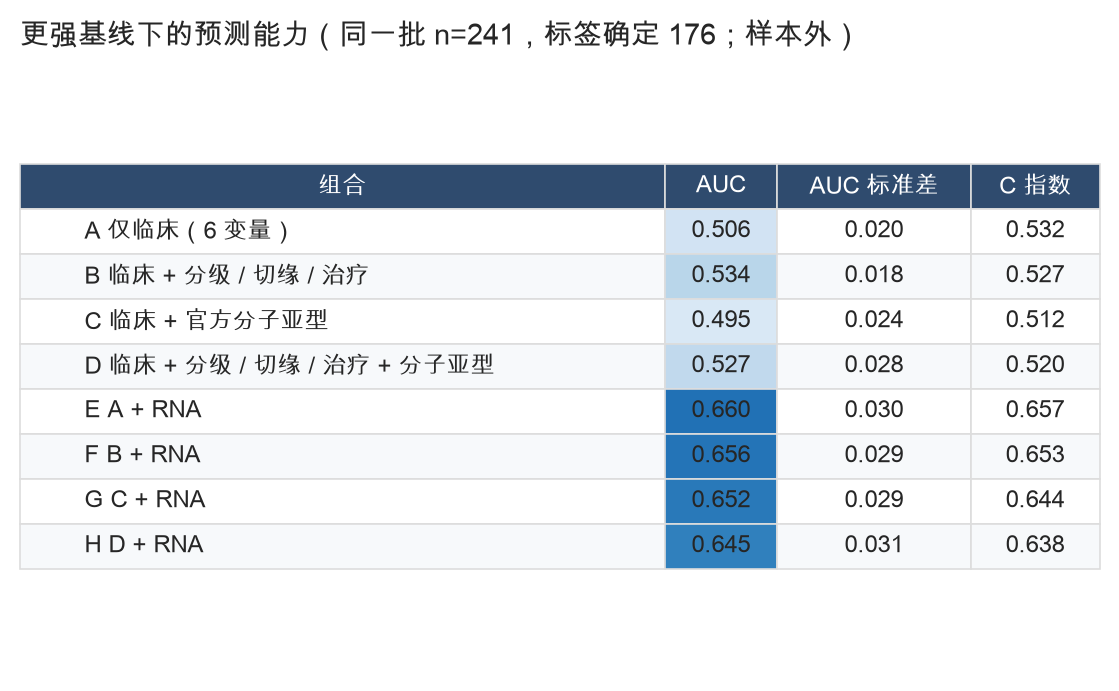

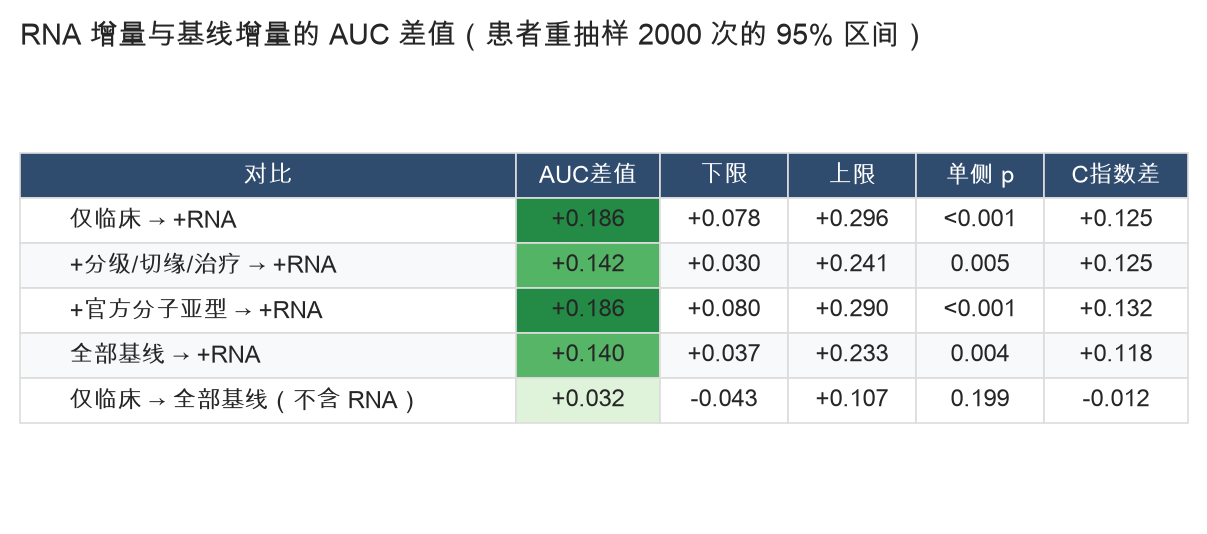

,AUC差值,下限,上限,单侧 p,C指数差
对比,,,,,
仅临床 → +RNA,0.185858,0.077812,0.296297,0.000,0.124504
+分级/切缘/治疗 → +RNA,0.142088,0.029944,0.241072,0.005,0.125318
+官方分子亚型 → +RNA,0.185718,0.080304,0.290316,0.000,0.132133
全部基线 → +RNA,0.140058,0.036915,0.233058,0.004,0.118198
仅临床 → 全部基线（不含 RNA）,0.031900,-0.043272,0.106546,0.199,-0.012410


In [41]:
def _extra(ids):
    c = clin.loc[ids]; X = pd.DataFrame(index=ids)
    g = c["neoplasm_histologic_grade"].map({"G1": 0, "G2": 0, "G3": 1}); X["G3"] = g.fillna(g.mode()[0])
    X["nonR0"] = c["residual_tumor"].map({"R0": 0, "R1": 1, "R2": 1, "RX": 1}).fillna(0)
    X["Radio"] = c["radiation_therapy"].map({"YES": 1, "NO": 0}).fillna(0)
    t_ = c["targeted_molecular_therapy"].map({"YES": 1, "NO": 0}); X["Drug"] = t_.fillna(t_.mode()[0])
    return X.values.astype(float)

def _subt(ids):
    return pd.get_dummies(official.loc[ids, "Molecular Subtype"]).reindex(columns=["CIN", "EBV", "GS", "MSI"]).astype(float).values

def _ext_X(ids, tx=False, st=False, rna=False):
    parts = [clin_matrix(ids)]
    if tx: parts.append(_extra(ids))
    if st: parts.append(_subt(ids))
    nc = sum(p.shape[1] for p in parts); bl = {"Clin": list(range(nc))}
    if rna:
        r = OM["RNA"].reindex(ids); r = r.fillna(r.mean()).fillna(0); parts.append(r.values.astype(float)); bl["RNA"] = list(range(nc, nc + r.shape[1]))
    return np.hstack(parts), bl

def _boot_diff(P1, P2, y, c, B=2000, seed=0):
    rng = np.random.default_rng(seed); idx = np.where(c)[0]; d = []
    for _ in range(B):
        b = rng.choice(idx, len(idx))
        if y[b].min() == y[b].max(): continue
        d.append(roc_auc_score(y[b], P2[b]) - roc_auc_score(y[b], P1[b]))
    d = np.array(d); return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), (d <= 0).mean()

_tP = pd.Series(tP, index=idsP); _eP = pd.Series(eP, index=idsP)
SCEN = [("A", "仅临床（6 变量）", dict()),
        ("B", "临床 + 分级 / 切缘 / 治疗", dict(tx=True)),
        ("C", "临床 + 官方分子亚型", dict(st=True)),
        ("D", "临床 + 分级 / 切缘 / 治疗 + 分子亚型", dict(tx=True, st=True)),
        ("E", "A + RNA", dict(rna=True)),
        ("F", "B + RNA", dict(tx=True, rna=True)),
        ("G", "C + RNA", dict(st=True, rna=True)),
        ("H", "D + RNA", dict(tx=True, st=True, rna=True))]
ids_s = [i for i in ids_rna if i in official.index]
y_s = y_all.loc[ids_s].values; c_s = conf_all.loc[ids_s].values
print(f"同一批患者：有 RNA 且有官方分子亚型 n = {len(ids_s)}（标签确定 {int(c_s.sum())}，其中急型 {int(y_s[c_s].sum())}）")
FR = {}
for k, nm, kw in SCEN:
    X_, bl_ = _ext_X(ids_s, **kw); a_, sd_, P_ = cv_pred(X_, y_s, c_s, bl_, MODEL_SEL, KK_SEL, reps=10)
    ci_ = concordance_index(_tP.loc[ids_s], -P_, _eP.loc[ids_s])
    FR[k] = dict(name=nm, AUC=a_, sd=sd_, Cindex=ci_, P=P_); print(f"{k} {nm:34s} AUC={a_:.3f} ± {sd_:.3f}   C 指数={ci_:.3f}")

PAIRS = [("A", "E", "仅临床 → +RNA"), ("B", "F", "+分级/切缘/治疗 → +RNA"), ("C", "G", "+官方分子亚型 → +RNA"), ("D", "H", "全部基线 → +RNA"), ("A", "D", "仅临床 → 全部基线（不含 RNA）")]
rows = []
for a_, b_, nm in PAIRS:
    m_, lo_, hi_, p_ = _boot_diff(FR[a_]["P"], FR[b_]["P"], y_s, c_s)
    rows.append(dict(对比=nm, AUC差值=m_, 下限=lo_, 上限=hi_, p=p_, C指数差=FR[b_]["Cindex"] - FR[a_]["Cindex"]))
F1 = pd.DataFrame(rows).set_index("对比").rename(columns={"p": "单侧 p"})
F0 = pd.DataFrame({"组合": [f"{k} {FR[k]['name']}" for k in FR], "AUC": [FR[k]["AUC"] for k in FR], "AUC 标准差": [FR[k]["sd"] for k in FR], "C 指数": [FR[k]["Cindex"] for k in FR]}).set_index("组合")
show_table(F0, "T_F1_strong_baseline", f"更强基线下的预测能力（同一批 n={len(ids_s)}，标签确定 {int(c_s.sum())}；样本外）", fmt={"AUC": "{:.3f}", "AUC 标准差": "{:.3f}", "C 指数": "{:.3f}"}, hl=["AUC"], wrap=34)
show_table(F1, "T_F2_rna_increment", "RNA 增量与基线增量的 AUC 差值（患者重抽样 2000 次的 95% 区间）", fmt={"AUC差值": "{:+.3f}", "下限": "{:+.3f}", "上限": "{:+.3f}", "单侧 p": lambda v: "<0.001" if v < 0.001 else f"{v:.3f}", "C指数差": "{:+.3f}"}, hl=["AUC差值"], cmap="Greens", wrap=30)

## F2 原样本上的置信区间
阶段 C 里"仅临床 0.614 → 临床 + RNA 0.675"没有区间。这里在**原来的 367 名**患者上补做（同一流程），并加入病理 / 治疗变量作基线。

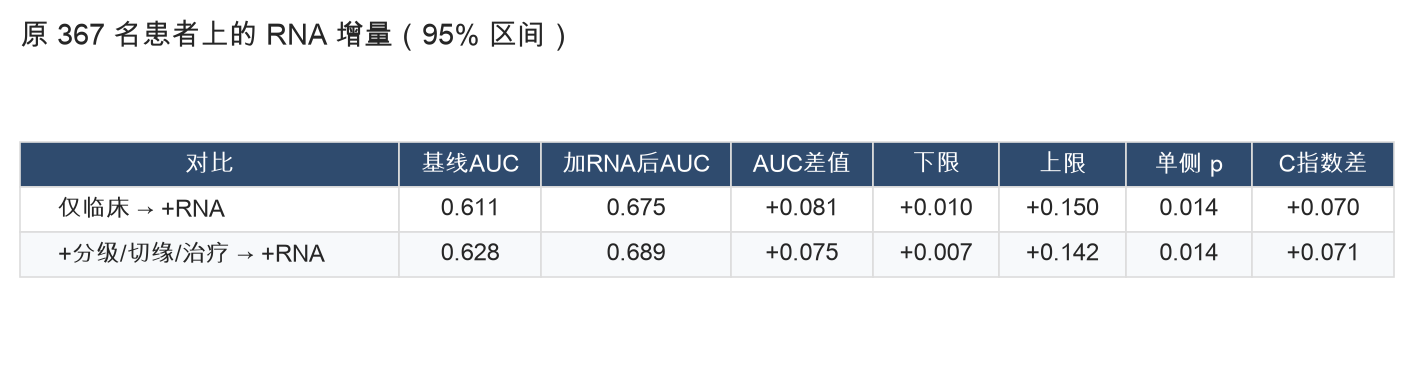

,基线AUC,加RNA后AUC,AUC差值,下限,上限,单侧 p,C指数差
对比,,,,,,,
仅临床 → +RNA,0.611055,0.675481,0.081347,0.009673,0.150349,0.014,0.069771
+分级/切缘/治疗 → +RNA,0.628285,0.689431,0.074591,0.006735,0.141670,0.014,0.071036


In [42]:
y_f = y_r; c_f = c_r
G = {}
for k, nm, kw in [("A", "仅临床", dict()), ("B", "临床 + 分级 / 切缘 / 治疗", dict(tx=True)), ("E", "A + RNA", dict(rna=True)), ("F", "B + RNA", dict(tx=True, rna=True))]:
    X_, bl_ = _ext_X(ids_rna, **kw); a_, sd_, P_ = cv_pred(X_, y_f, c_f, bl_, MODEL_SEL, KK_SEL, reps=10)
    G[k] = dict(name=nm, AUC=a_, sd=sd_, Cindex=concordance_index(_tP.loc[ids_rna], -P_, _eP.loc[ids_rna]), P=P_)
rows = []
for a_, b_, nm in [("A", "E", "仅临床 → +RNA"), ("B", "F", "+分级/切缘/治疗 → +RNA")]:
    m_, lo_, hi_, p_ = _boot_diff(G[a_]["P"], G[b_]["P"], y_f, c_f)
    rows.append(dict(对比=nm, 基线AUC=G[a_]["AUC"], 加RNA后AUC=G[b_]["AUC"], AUC差值=m_, 下限=lo_, 上限=hi_, p=p_, C指数差=G[b_]["Cindex"] - G[a_]["Cindex"]))
F3 = pd.DataFrame(rows).set_index("对比").rename(columns={"p": "单侧 p"})
show_table(F3, "T_F3_full_cohort_ci", f"原 {len(ids_rna)} 名患者上的 RNA 增量（95% 区间）", fmt={"基线AUC": "{:.3f}", "加RNA后AUC": "{:.3f}", "AUC差值": "{:+.3f}", "下限": "{:+.3f}", "上限": "{:+.3f}", "单侧 p": lambda v: "<0.001" if v < 0.001 else f"{v:.3f}", "C指数差": "{:+.3f}"}, wrap=30)

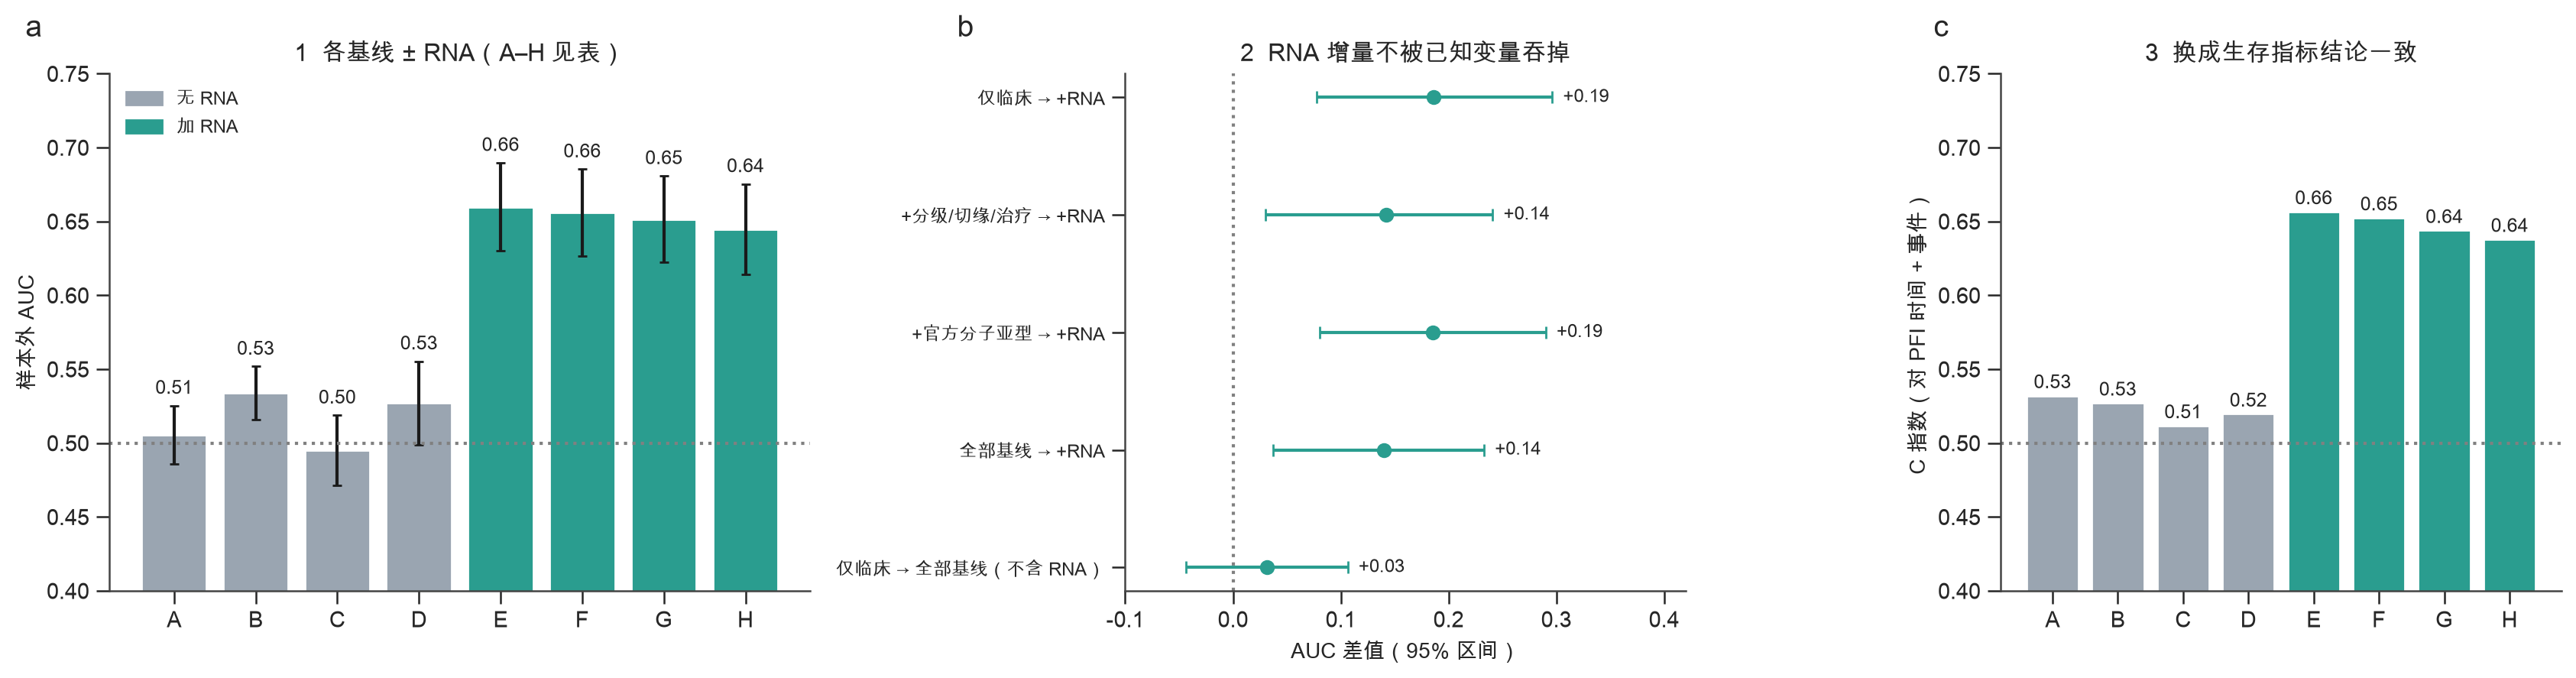

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
ax = axes[0]
ks = list(FR); cols = ["#9AA5B1"] * 4 + ["#2A9D8F"] * 4
ax.bar(range(8), [FR[k]["AUC"] for k in ks], yerr=[FR[k]["sd"] for k in ks], color=cols, edgecolor="white", capsize=2)
for i_, k in enumerate(ks): ax.text(i_, FR[k]["AUC"] + FR[k]["sd"] + 0.008, f"{FR[k]['AUC']:.2f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(0.5, ls=":", c="grey"); ax.set_xticks(range(8)); ax.set_xticklabels(ks); ax.set_ylim(0.4, 0.75)
ax.legend(handles=[Patch(color="#9AA5B1", label="无 RNA"), Patch(color="#2A9D8F", label="加 RNA")], fontsize=8.5, loc="upper left")
ax.set(ylabel="样本外 AUC", title="1  各基线 ± RNA（A–H 见表）"); panel_label(ax, "a")
ax = axes[1]
lab = list(F1.index); y_ = np.arange(len(lab))[::-1]
ax.errorbar(F1["AUC差值"], y_, xerr=[F1["AUC差值"] - F1["下限"], F1["上限"] - F1["AUC差值"]], fmt="o", color="#2A9D8F", capsize=3)
for i_, (v_, p_) in enumerate(zip(F1["AUC差值"], F1["单侧 p"])): ax.text(F1["上限"].iloc[i_] + 0.01, y_[i_], f"{v_:+.2f}", va="center", fontsize=8.5)
ax.axvline(0, c="grey", ls=":"); ax.set_yticks(y_); ax.set_yticklabels(lab, fontsize=8.5); ax.set_xlim(-0.1, 0.42)
ax.set(xlabel="AUC 差值（95% 区间）", title="2  RNA 增量不被已知变量吞掉"); panel_label(ax, "b", x=-0.3)
ax = axes[2]
cc = [FR[k]["Cindex"] for k in ks]
ax.bar(range(8), cc, color=cols, edgecolor="white")
for i_, v_ in enumerate(cc): ax.text(i_, v_ + 0.005, f"{v_:.2f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(0.5, ls=":", c="grey"); ax.set_xticks(range(8)); ax.set_xticklabels(ks); ax.set_ylim(0.4, 0.75)
ax.set(ylabel="C 指数（对 PFI 时间 + 事件）", title="3  换成生存指标结论一致"); panel_label(ax, "c")
fig.tight_layout(); savefig(fig, "F1_strong_baseline")

In [44]:
_g = lambda a, b: F1.loc[b, :]
_d_all = F1.loc["全部基线 → +RNA"]; _d_clin = F1.loc["仅临床 → +RNA"]; _d_base = F1.loc["仅临床 → 全部基线（不含 RNA）"]
md(f"""### 补充分析 F 结论

- **同一批患者（n={len(ids_s)}）上**，6 变量临床基线 AUC = {FR['A']['AUC']:.2f}（接近随机），加上分级 / 切缘 / 治疗 / 官方分子亚型后只到 {FR['D']['AUC']:.2f}（差值 {_d_base['AUC差值']:+.2f}，区间 {_d_base['下限']:+.2f} ~ {_d_base['上限']:+.2f}，**包含 0**）。**这些已知变量都不能预测急型。**
- **加入 RNA 后**：仅临床 {FR['A']['AUC']:.2f} → {FR['E']['AUC']:.2f}（{_d_clin['AUC差值']:+.2f}，区间 {_d_clin['下限']:+.2f} ~ {_d_clin['上限']:+.2f}）；全部基线 {FR['D']['AUC']:.2f} → {FR['H']['AUC']:.2f}（{_d_all['AUC差值']:+.2f}，区间 {_d_all['下限']:+.2f} ~ {_d_all['上限']:+.2f}）。**RNA 的增量在所有基线下都显著大于 0，没有被官方分子亚型或治疗变量吞掉。**
- **原 {len(ids_rna)} 名患者**上：临床 {G['A']['AUC']:.3f} → 临床 + RNA {G['E']['AUC']:.3f}，差值 {F3.loc['仅临床 → +RNA','AUC差值']:+.3f}（{F3.loc['仅临床 → +RNA','下限']:+.3f} ~ {F3.loc['仅临床 → +RNA','上限']:+.3f}）。**阶段 C 报告的增量是 0.064（逐次重复的 AUC 均值之差）；这里的 0.081 是对「重复平均后的预测」做重抽样，口径略有不同。区间下限接近 0，应理解为"方向可信、幅度不确定"。**
- **C 指数**与 AUC 的方向一致（RNA 相关组合都更高），换成生存指标结论不变。
- **注意两点**：(1) 在这 {len(ids_s)} 人的子集里，加 RNA 后的绝对 AUC（约 {FR['E']['AUC']:.2f}）与全体相近，但基线 AUC 偏低（{FR['A']['AUC']:.2f} vs 全体 {G['A']['AUC']:.2f}），增量的大小部分取决于这个基线；(2) 更多的基线变量并没有让整体预测更好（H 略低于 E），说明 RNA 之外的信号太弱，加变量主要增加噪声。
- **仍然缺失**：独立外部队列验证（如 ACRG, GSE62254）。没有它，上述全部为同一队列内的结论。""")

### 补充分析 F 结论

- **同一批患者（n=241）上**，6 变量临床基线 AUC = 0.51（接近随机），加上分级 / 切缘 / 治疗 / 官方分子亚型后只到 0.53（差值 +0.03，区间 -0.04 ~ +0.11，**包含 0**）。**这些已知变量都不能预测急型。**
- **加入 RNA 后**：仅临床 0.51 → 0.66（+0.19，区间 +0.08 ~ +0.30）；全部基线 0.53 → 0.64（+0.14，区间 +0.04 ~ +0.23）。**RNA 的增量在所有基线下都显著大于 0，没有被官方分子亚型或治疗变量吞掉。**
- **原 367 名患者**上：临床 0.611 → 临床 + RNA 0.675，差值 +0.081（+0.010 ~ +0.150）。**阶段 C 报告的增量是 0.064（逐次重复的 AUC 均值之差）；这里的 0.081 是对「重复平均后的预测」做重抽样，口径略有不同。区间下限接近 0，应理解为"方向可信、幅度不确定"。**
- **C 指数**与 AUC 的方向一致（RNA 相关组合都更高），换成生存指标结论不变。
- **注意两点**：(1) 在这 241 人的子集里，加 RNA 后的绝对 AUC（约 0.66）与全体相近，但基线 AUC 偏低（0.51 vs 全体 0.61），增量的大小部分取决于这个基线；(2) 更多的基线变量并没有让整体预测更好（H 略低于 E），说明 RNA 之外的信号太弱，加变量主要增加噪声。
- **仍然缺失**：独立外部队列验证（如 ACRG, GSE62254）。没有它，上述全部为同一队列内的结论。